# DSAA2011 Course Project (Task A) — *"Where am I?"*
## Identifying Australia's climate zone from a single day of weather

**Question.** Given the weather observations of one day at one station (temperature, humidity, pressure, wind, rain),
can we tell which climate zone the station belongs to?

| Step | Question it answers |
|---|---|
| Part 1 Preprocessing | What does the data look like, and which preprocessing choices could leak the answer? |
| Part 2 t-SNE | Do days from different climate zones separate naturally in feature space? |
| Part 3 Clustering | Without labels, can clustering rediscover the climate zones? |
| Part 4 Prediction | With labels, how well can simple models classify the zone of a day? |
| Part 5 Evaluation | Which zones are confused, and does the model generalise to **stations it has never seen**? |

**Target (`Zone`, 5 classes)** is derived from the Köppen-Geiger classification of each station
(groups A and B kept whole, group C split into Cfa / Cs / Cfb). See Section 0.2.

## 0. Setup

In [1]:
import hashlib
import io
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score
from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42                      # one seed for every split / sample / model in the notebook
DATA_DIR = Path("data")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RAW_CSV = DATA_DIR / "raw" / "weatherAUS.csv"   # Kaggle: jsphyg/weather-dataset-rattle-package, version 2
RAW_SHA256 = "573fd715cd69fcacc4df32024d823b450ae3edaae7e8ff2eeb623adbed424014"

ZONE_ORDER = ["Tropical", "Arid", "Subtropical", "Mediterranean", "Oceanic"]
ZONE_COLORS = {"Tropical": "#d62728", "Arid": "#e6a01e", "Subtropical": "#2ca02c",
               "Mediterranean": "#9467bd", "Oceanic": "#1f77b4"}
sns.set_theme(style="whitegrid", context="notebook")

def savefig(name):
    # every figure is also written to figures/ so the report and slides use the same image
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

# --- result cache -------------------------------------------------------------------------
# Cross-validation, grid searches and t-SNE take 10 s - 2 min each. Their results are stored in
# data/processed/cache/. The file name contains a hash of the data version and of all parameters,
# so changing a parameter (or the data) automatically triggers a recomputation.
# RECOMPUTE = True ignores every cache and reruns everything (about 15-20 min on a laptop).
import pickle
CACHE_DIR = DATA_DIR / "processed" / "cache"; CACHE_DIR.mkdir(parents=True, exist_ok=True)
RECOMPUTE = False

def cached(name, compute, **params):
    key = hashlib.sha256(repr((RAW_SHA256, sorted(params.items()))).encode()).hexdigest()[:12]
    path = CACHE_DIR / f"{name}_{key}.pkl"
    if path.exists() and not RECOMPUTE:
        with open(path, "rb") as f:
            return pickle.load(f)
    result = compute()
    with open(path, "wb") as f:
        pickle.dump(result, f)
    return result

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.2.6 | pandas 2.3.3 | scikit-learn 1.7.2


### 0.2 Building the target: station → Köppen code → `Zone`

The dataset has no climate label, so we construct one from two documented sources:

1. **Station coordinates** — Bureau of Meteorology station list (product IDCJMC0014, downloaded 2026-11-09,
   stored in `data/external/`). Each `Location` was matched by hand to a BoM site number
   (`data/external/location_station.csv`).
2. **Köppen-Geiger code** — looked up with `kgcpy` 1.1.8, the Python port of the CRAN package `kgc`
   (Bryant, Wheeler, Rubel & French, 2017). Both packages ship a global 12960 × 6480 raster, i.e. 100 arc-seconds
   (≈ 3 km) per pixel, and cite Rubel et al. (2017, *Meteorol. Z.* 26:115–125, doi:10.1127/metz/2016/0816) as the
   data source. That paper's title refers to the European Alps, but it also describes the downscaling method that
   the authors used for their re-analysed **global** map, which according to the map's website
   (koeppen-geiger.vu-wien.ac.at) represents the period **1986–2010**. The lookup takes the pixel whose centre is
   nearest to the station coordinates.

The five classes are **project-defined groups of Köppen codes** (we call them "zones" for short). Groups A and B
are kept whole; group C is split by Köppen's own second letter (f = no dry season, s = dry summer) and third letter
(a = hot summer, b = warm summer). Only Am, Aw, BWh, BSh, BSk, Cfa, Csa, Csb and Cfb occur at our stations; there
are no D (snow) or E (polar) climates in the data. Any code outside the mapping below would receive no label.

| Zone | Köppen | Meaning |
|---|---|---|
| Tropical | A (Am, Aw) | hot all year, summer wet season |
| Arid | B (BWh, BSh, BSk) | desert / steppe |
| Subtropical | Cfa | hot summer, rain all year |
| Mediterranean | Csa, Csb | dry summer, wet winter |
| Oceanic | Cfb | mild summer, rain all year |

The table is cached in `data/processed/location_zone.csv`; set `REBUILD_LABELS = True` to regenerate it.

In [2]:
KOPPEN_TO_ZONE = {
    "Af": "Tropical", "Am": "Tropical", "Aw": "Tropical", "As": "Tropical",
    "BWh": "Arid", "BWk": "Arid", "BSh": "Arid", "BSk": "Arid",
    "Cfa": "Subtropical", "Cwa": "Subtropical",
    "Csa": "Mediterranean", "Csb": "Mediterranean",
    "Cfb": "Oceanic", "Cfc": "Oceanic",
}
ZONE_CSV = DATA_DIR / "processed" / "location_zone.csv"
REBUILD_LABELS = False

def read_bom_stations(zip_path):
    # BoM station list is a fixed-width text file; the first 4 lines are a header
    text = zipfile.ZipFile(zip_path).read("stations.txt").decode("latin-1")
    rows = []
    for line in text.splitlines()[4:]:
        if len(line) >= 90 and line[:7].strip().isdigit():
            rows.append({"bom_site": line[0:7].strip(), "bom_name_list": line[14:55].strip(),
                         "lat": float(line[71:80]), "lon": float(line[80:90])})
    return pd.DataFrame(rows)

def build_location_zone():
    from kgcpy import lookupCZ, nearbyCZ          # only needed when rebuilding
    loc = pd.read_csv(DATA_DIR / "external" / "location_station.csv", dtype=str)
    st = read_bom_stations(DATA_DIR / "external" / "bom_stations_IDCJMC0014_2026-11-09.zip")
    z = loc.merge(st, on="bom_site", how="left", validate="one_to_one")
    assert z["lat"].notna().all() and (z["bom_name"] == z["bom_name_list"]).all()
    z["koppen"] = [lookupCZ(a, b) for a, b in zip(z["lat"], z["lon"])]
    near = [nearbyCZ(a, b, 1) for a, b in zip(z["lat"], z["lon"])]     # 3x3 pixel window
    z["neighbour_match"] = [round(n[1], 2) for n in near]
    z["neighbour_codes"] = [";".join(sorted(set(n[2]))) for n in near]
    z["Zone"] = z["koppen"].map(KOPPEN_TO_ZONE)                          # "Ocean" -> NaN (no label)
    # boundary station = a neighbouring LAND pixel belongs to a different zone
    z["zone_boundary"] = [any(KOPPEN_TO_ZONE.get(c, c) != zz for c in codes.split(";") if c and c != "Ocean")
                          if isinstance(zz, str) else True
                          for codes, zz in zip(z["neighbour_codes"], z["Zone"])]
    z = z[["Location", "bom_site", "bom_name", "lat", "lon", "koppen",
           "neighbour_match", "neighbour_codes", "zone_boundary", "Zone"]]
    ZONE_CSV.parent.mkdir(parents=True, exist_ok=True)
    z.to_csv(ZONE_CSV, index=False)
    return z

zones = build_location_zone() if (REBUILD_LABELS or not ZONE_CSV.exists()) else pd.read_csv(ZONE_CSV, dtype={"bom_site": str})
for zone, s in zones.groupby(zones["Zone"].fillna("(no label)"))["Location"]:
    print(f"{zone:14s} {len(s):2d}: " + ", ".join(s))
print("\nboundary / unlabeled stations:")
zones[zones["zone_boundary"] | zones["Zone"].isna()][["Location", "koppen", "neighbour_codes", "Zone"]]

(no label)      1: NorfolkIsland
Arid            7: AliceSprings, Cobar, Mildura, Nhil, SalmonGums, Uluru, Woomera
Mediterranean  11: Adelaide, Albany, Dartmoor, MountGambier, Nuriootpa, PearceRAAF, Perth, PerthAirport, Portland, Walpole, Witchcliffe
Oceanic        11: Ballarat, Bendigo, Canberra, Hobart, Launceston, Melbourne, MelbourneAirport, MountGinini, Sale, Tuggeranong, Watsonia
Subtropical    15: Albury, BadgerysCreek, Brisbane, CoffsHarbour, GoldCoast, Moree, Newcastle, NorahHead, Penrith, Richmond, Sydney, SydneyAirport, WaggaWagga, Williamtown, Wollongong
Tropical        4: Cairns, Darwin, Katherine, Townsville

boundary / unlabeled stations:


,Location,koppen,neighbour_codes,Zone
27,NorfolkIsland,Ocean,NaN,NaN
47,Wollongong,Cfa,Cfb,Subtropical


**Full audit table** (all 49 stations): dataset `Location` → BoM site number and name → coordinates → Köppen code
at that pixel → codes found in the surrounding 3 × 3 pixels → project group. Anyone can check a row by looking up
the site number in the BoM list and the coordinates on the Köppen map.

In [3]:
with pd.option_context("display.max_rows", 60, "display.width", 200):
    display(zones[["Location", "bom_site", "bom_name", "lat", "lon", "koppen", "neighbour_codes", "zone_boundary", "Zone"]]
            .sort_values(["Zone", "Location"], na_position="last").reset_index(drop=True))

,Location,bom_site,bom_name,lat,lon,koppen,neighbour_codes,zone_boundary,Zone
0,AliceSprings,015590,ALICE SPRINGS AIRPORT,-23.7951,133.8890,BWh,NaN,False,Arid
1,Cobar,048027,COBAR MO,-31.4840,145.8294,BSh,NaN,False,Arid
2,Mildura,076031,MILDURA AIRPORT,-34.2358,142.0867,BSk,NaN,False,Arid
3,Nhil,078015,NHILL AERODROME,-36.3093,141.6486,BSk,NaN,False,Arid
4,SalmonGums,012071,SALMON GUMS RES.STN.,-32.9869,121.6239,BSk,NaN,False,Arid
5,Uluru,015635,YULARA AIRPORT,-25.1896,130.9737,BWh,NaN,False,Arid
6,Woomera,016001,WOOMERA AERODROME,-31.1558,136.8054,BWh,NaN,False,Arid
7,Adelaide,023090,ADELAIDE (KENT TOWN),-34.9211,138.6216,Csb,Csa,False,Mediterranean
8,Albany,009741,ALBANY AIRPORT COMPARISON,-34.9414,117.8022,Csb,NaN,False,Mediterranean
9,Dartmoor,090194,DARTMOOR,-37.9222,141.2614,Csb,NaN,False,Mediterranean


**Norfolk Island.** Its station (BoM 200288, Norfolk Island Aero) gets the code "Ocean". To rule out a coordinate or
rounding error we search outward from its pixel for the nearest *land* pixel of the raster. This needs `kgcpy`; the
result is cached so the notebook runs without it.

In [4]:
def norfolk_check():
    import kgcpy
    img, codes = kgcpy.img, kgcpy.kg_zoneNum_df
    ocean = set(codes.loc[codes["kg_zone"] == "Ocean", "zoneNum"])
    lat, lon = zones.set_index("Location").loc["NorfolkIsland", ["lat", "lon"]]
    x0 = round((lon + 180) * img.size[0] / 360 - 0.5); y0 = round(-(lat - 90) * img.size[1] / 180 - 0.5)
    best = None
    for r in range(1, 400):                      # square rings of growing radius (in pixels)
        ring = [(dx, dy) for dx in range(-r, r + 1) for dy in (-r, r)] + [(dx, dy) for dx in (-r, r) for dy in range(-r + 1, r)]
        land = [(np.hypot(dx, dy), dx, dy) for dx, dy in ring if img.getpixel((x0 + dx, y0 + dy)) not in ocean]
        if land:
            d, dx, dy = min(land)
            v = img.getpixel((x0 + dx, y0 + dy))
            lat2 = 90 - (y0 + dy + 0.5) * 180 / img.size[1]; lon2 = (x0 + dx + 0.5) * 360 / img.size[0] - 180
            p1, p2, dl = np.deg2rad(lat), np.deg2rad(lat2), np.deg2rad(lon2 - lon)      # haversine distance
            km = 2 * 6371 * np.arcsin(np.sqrt(np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2))
            best = {"pixel size (arcsec)": 360 * 3600 / img.size[0], "code at station pixel": "Ocean",
                    "first ring with land (pixels)": r, "nearest land pixel lat": round(lat2, 2),
                    "nearest land pixel lon": round(lon2, 2),
                    "code there": codes.loc[codes["zoneNum"] == v, "kg_zone"].item(), "distance (km)": round(km)}
            break
    return best

pd.Series(cached("p0_norfolk_check", norfolk_check, version=1))

pixel size (arcsec)               100.0
code at station pixel             Ocean
first ring with land (pixels)       185
nearest land pixel lat           -34.18
nearest land pixel lon           172.85
code there                          Cfb
distance (km)                       736
dtype: object

The island is simply not on the raster (it is about 8 km across and the map's land mask omits it): the first land
pixel appears 185 pixels away, at the northern tip of New Zealand, 736 km from the station. The "Ocean" code is
therefore not a coordinate or rounding error. Rather than assign a label by hand, we drop the station (3,009 rows, 2.1% of the
data). Because it had no label, dropping it does not change the class proportions of the remaining data.

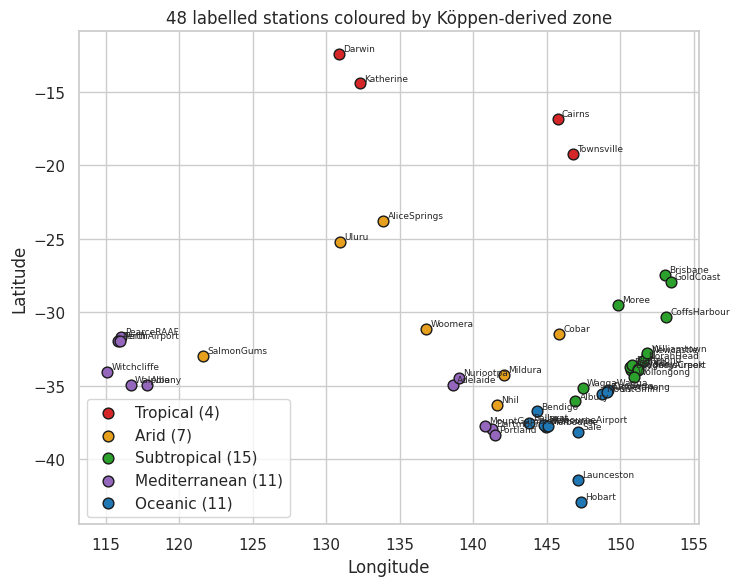

In [5]:
# Where are the stations? (plain lon/lat scatter, no basemap needed)
z = zones.dropna(subset=["Zone"])
fig, ax = plt.subplots(figsize=(8, 6.5))
for zone in ZONE_ORDER:
    s = z[z["Zone"] == zone]
    ax.scatter(s["lon"], s["lat"], s=60, color=ZONE_COLORS[zone], edgecolor="k", label=f"{zone} ({len(s)})")
for r in z.itertuples():
    ax.annotate(r.Location, (r.lon, r.lat), fontsize=6.5, xytext=(3, 2), textcoords="offset points")
ax.set(xlabel="Longitude", ylabel="Latitude", title="48 labelled stations coloured by Köppen-derived zone")
ax.set_aspect("equal"); ax.legend(loc="lower left")
savefig("p1_station_map"); plt.show()

## 1. Data Preprocessing

### 1.1 Loading and leakage audit

For this target, three columns must never be features:

* `Location` — the zone is a deterministic function of the station (this would be the answer itself);
* `RainTomorrow` — information from the next day;
* `RISK_MM` — next-day rainfall in older versions of the dataset (we check rather than assume it is absent).

`Location` is kept **outside** the feature table as `groups`; it is only used for station-grouped splits and error analysis.
`Date` is only used to derive the day of year; the year itself is not used.

In [6]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

assert sha256(RAW_CSV) == RAW_SHA256, "data file differs from the documented Kaggle v2 file"
raw = pd.read_csv(RAW_CSV, parse_dates=["Date"])
print("raw shape:", raw.shape, "| dates:", raw["Date"].min().date(), "->", raw["Date"].max().date(),
      "| stations:", raw["Location"].nunique())

LEAKAGE_DROP = ["Location", "RainTomorrow", "RISK_MM"]
print("leakage columns present:", [c for c in LEAKAGE_DROP if c in raw.columns],
      "| absent:", [c for c in LEAKAGE_DROP if c not in raw.columns])

df = raw.merge(zones[["Location", "Zone"]], on="Location", how="left", validate="many_to_one")
print("rows without a zone label (dropped):", df["Zone"].isna().sum(), sorted(df.loc[df["Zone"].isna(), "Location"].unique()))
df = df[df["Zone"].notna()].reset_index(drop=True)

groups = df["Location"].copy()                     # station id, NEVER a model input
df = df.drop(columns=[c for c in LEAKAGE_DROP if c in df.columns])
y = df["Zone"].values
print("final shape:", df.shape, "| duplicated (Date, station):", pd.DataFrame({"d": df["Date"], "g": groups}).duplicated().sum())

raw shape: (145460, 23) | dates: 2007-11-01 -> 2017-06-25 | stations: 49
leakage columns present: ['Location', 'RainTomorrow'] | absent: ['RISK_MM']
rows without a zone label (dropped): 3009 ['NorfolkIsland']
final shape: (142451, 22) | duplicated (Date, station): 0


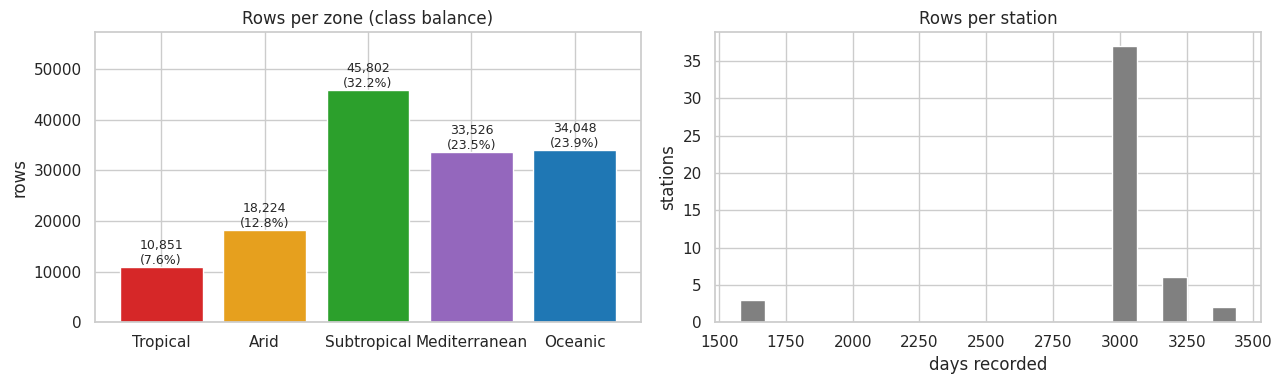

majority-class baseline accuracy: 0.322


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cnt = df["Zone"].value_counts().reindex(ZONE_ORDER)
axes[0].bar(cnt.index, cnt.values, color=[ZONE_COLORS[z] for z in cnt.index])
for i, v in enumerate(cnt.values):
    axes[0].text(i, v, f"{v:,}\n({v / cnt.sum():.1%})", ha="center", va="bottom", fontsize=9)
axes[0].set(title="Rows per zone (class balance)", ylabel="rows"); axes[0].set_ylim(0, cnt.max() * 1.25)

per_station = groups.value_counts()
axes[1].hist(per_station.values, bins=20, color="grey")
axes[1].set(title="Rows per station", xlabel="days recorded", ylabel="stations")
plt.tight_layout(); savefig("p1_class_balance"); plt.show()
print("majority-class baseline accuracy:", round(cnt.max() / cnt.sum(), 3))

### 1.2 Missing values: the structure matters more than the rate

We first look at *where* values are missing, not just how many.

In [8]:
RAW_FEATURES = ["MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Sunshine", "WindGustDir", "WindGustSpeed",
                "WindDir9am", "WindDir3pm", "WindSpeed9am", "WindSpeed3pm", "Humidity9am", "Humidity3pm",
                "Pressure9am", "Pressure3pm", "Cloud9am", "Cloud3pm", "Temp9am", "Temp3pm", "RainToday"]
miss_station = df[RAW_FEATURES].isna().groupby(groups).mean()          # station x column missing rate
summary = pd.DataFrame({
    "missing_%": (df[RAW_FEATURES].isna().mean() * 100).round(1),
    "stations_fully_missing(>95%)": (miss_station > 0.95).sum(),
}).sort_values("missing_%", ascending=False)
summary

,missing_%,stations_fully_missing(>95%)
Sunshine,48.7,19
Evaporation,43.9,17
Cloud3pm,41.6,12
Cloud9am,39.2,12
Pressure9am,10.6,4
Pressure3pm,10.5,4
WindDir9am,7.4,0
WindGustDir,7.2,2
WindGustSpeed,7.2,2
Humidity3pm,3.2,0


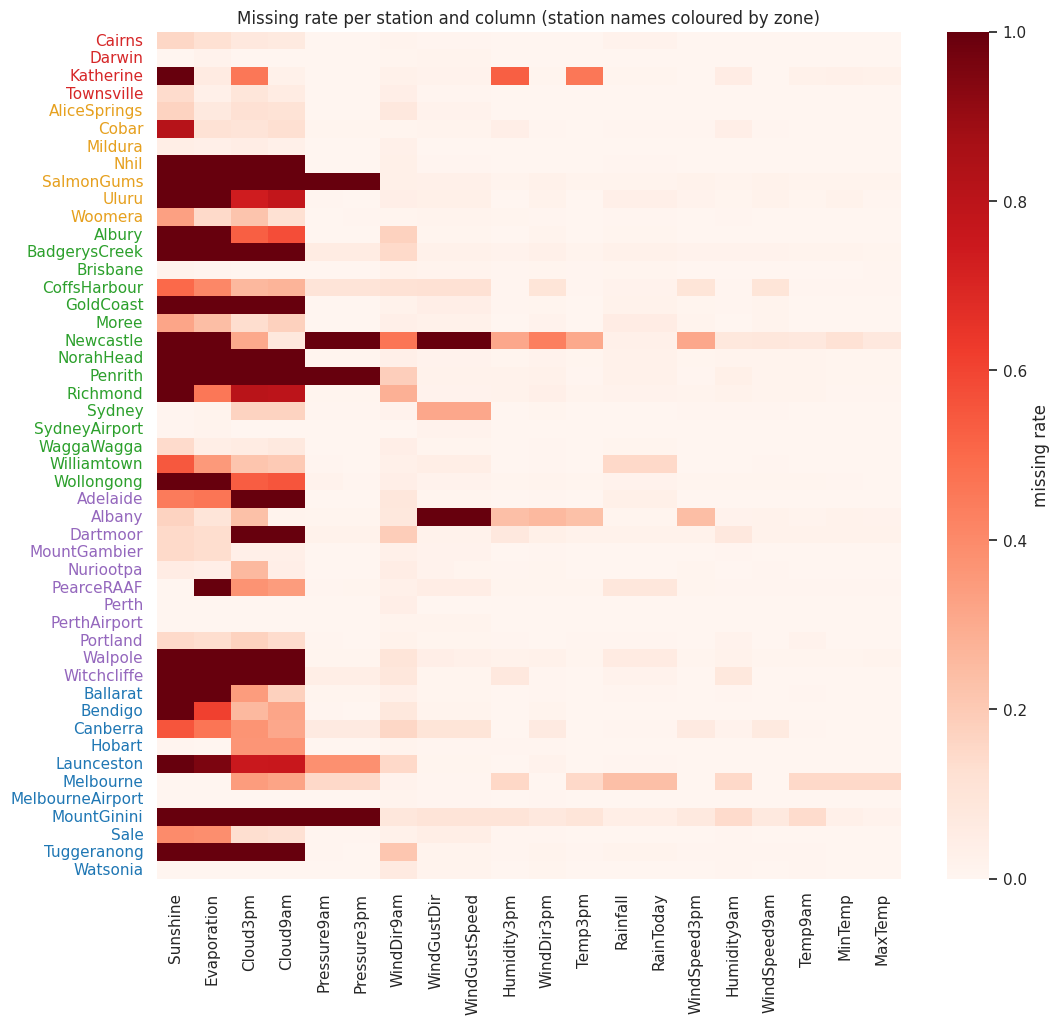

In [9]:
# station x column heatmap, stations sorted by zone; tick labels coloured by zone
station_zone = zones.set_index("Location")["Zone"]
order = sorted(miss_station.index, key=lambda s: (ZONE_ORDER.index(station_zone[s]), s))
cols = summary.index.tolist()
fig, ax = plt.subplots(figsize=(12, 11))
sns.heatmap(miss_station.loc[order, cols], cmap="Reds", vmin=0, vmax=1, cbar_kws={"label": "missing rate"}, ax=ax)
for t in ax.get_yticklabels():
    t.set_color(ZONE_COLORS[station_zone[t.get_text()]])
ax.set(title="Missing rate per station and column (station names coloured by zone)", xlabel="", ylabel="")
savefig("p1_missing_heatmap"); plt.show()

**Observation.** Missingness is a *station property*: Sunshine, Evaporation and Cloud are absent for entire stations
(12–19 of 48) because those stations do not have the instruments. This creates a hidden risk for our target:
the *pattern* of missing values may identify the station, and the station determines the zone.
We test this directly: train a decision tree on **only the 20 is-missing flags** (no weather values at all).

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
X_missing = df[RAW_FEATURES].isna().astype(int)
def fingerprint_test():
    out = {}
    for name, target in [("Zone", df["Zone"]), ("Location", groups)]:
        tree = cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE), X_missing, target, cv=cv).mean()
        dummy = cross_val_score(DummyClassifier(strategy="most_frequent"), X_missing, target, cv=cv).mean()
        out[name] = {"tree on missing flags": round(tree, 3), "majority baseline": round(dummy, 3)}
    year_acc = cross_val_score(DecisionTreeClassifier(random_state=RANDOM_STATE),
                               df[["Date"]].apply(lambda d: d.dt.year), df["Zone"], cv=cv).mean()
    out["Zone (from year only)"] = {"tree on missing flags": round(year_acc, 3),
                                    "majority baseline": out["Zone"]["majority baseline"]}
    return out

fingerprint = cached("p1_fingerprint", fingerprint_test, seed=RANDOM_STATE, cols=tuple(RAW_FEATURES))
pd.DataFrame(fingerprint).T

,tree on missing flags,majority baseline
Zone,0.439,0.322
Location,0.240,0.024
Zone (from year only),0.323,0.322


**Result.** The missing flags alone predict the zone far above the majority baseline and identify the exact station
about 10× better than chance. Missing indicators (and any imputation that copies station-specific values) would
therefore let a model *recognise the station* instead of *learning the climate*. The year, by contrast, carries
almost no information here (most stations start in 2008–2009); we still exclude it because it has no
meteorological meaning.

### 1.3 Two missing values that are not really missing

In [11]:
for d, s in [("WindDir9am", "WindSpeed9am"), ("WindDir3pm", "WindSpeed3pm")]:
    calm = df[s] == 0
    print(f"{d}: {df[d].isna().sum():6d} missing | rows with {s}==0: {calm.sum():5d}, "
          f"of which direction missing: {df.loc[calm, d].isna().mean():.0%}")
r = df.dropna(subset=["Rainfall", "RainToday"])
print("RainToday == (Rainfall > 1 mm) for", f"{((r['Rainfall'] > 1) == (r['RainToday'] == 'Yes')).mean():.1%}", "of rows")

WindDir9am:  10535 missing | rows with WindSpeed9am==0:  8722, of which direction missing: 100%
WindDir3pm:   4223 missing | rows with WindSpeed3pm==0:  1109, of which direction missing: 100%
RainToday == (Rainfall > 1 mm) for 100.0% of rows


* **Calm wind.** Every row with wind speed 0 has no direction: the direction is *undefined*, not unknown.
  Encoding wind as a vector `(u, v)` handles this exactly — calm is `(0, 0)`.
* **RainToday** is a deterministic function of `Rainfall` (threshold 1 mm). After encoding it as 0/1 it adds no
  information, so we drop it and keep `Rainfall`.

### 1.4 Handling non-numeric values and further processing

| Raw column(s) | Treatment | Reason |
|---|---|---|
| `WindGustDir`, `WindDir9am`, `WindDir3pm` + speeds | 16-point compass → angle θ → vector `u = −s·sinθ`, `v = −s·cosθ` | keeps the circular order (N is next to NNW), merges direction and strength, calm = (0,0); 6 numbers instead of 48 one-hot columns |
| `Date` | day of year → `sin`, `cos` | 31 Dec and 1 Jan are neighbours; year not used |
| `RainToday` | Yes/No → 1/0, then dropped | identical to `Rainfall > 1` |
| `Rainfall`, `Evaporation` | `log1p` | strongly right-skewed, 63% zeros |
| all numeric | median imputation → `StandardScaler` | fitted **inside the pipeline on training data only** |
| Sunshine, Evaporation, Cloud9am/3pm | excluded from the default (`core`) feature set | missing for whole stations → station fingerprint; kept in a `full` set for a sensitivity check |

All transformations in `make_features` are row-wise (no statistics are learned), so applying them before the split is safe.

In [12]:
COMPASS = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
DIR_TO_DEG = {d: i * 22.5 for i, d in enumerate(COMPASS)}
WIND_PAIRS = {"Gust": ("WindGustDir", "WindGustSpeed"),
              "Wind9am": ("WindDir9am", "WindSpeed9am"),
              "Wind3pm": ("WindDir3pm", "WindSpeed3pm")}

def wind_vector(direction, speed):
    theta = np.deg2rad(direction.map(DIR_TO_DEG))
    u, v = -speed * np.sin(theta), -speed * np.cos(theta)
    calm = speed.eq(0)                       # calm: direction undefined, vector is exactly zero
    u[calm], v[calm] = 0.0, 0.0
    return u, v

def make_features(data):
    out = pd.DataFrame(index=data.index)
    for c in ["MinTemp", "MaxTemp", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm", "Humidity9am", "Humidity3pm",
              "Pressure9am", "Pressure3pm", "Temp9am", "Temp3pm", "Sunshine", "Cloud9am", "Cloud3pm"]:
        out[c] = data[c]
    out["Rainfall_log1p"] = np.log1p(data["Rainfall"])
    out["Evaporation_log1p"] = np.log1p(data["Evaporation"])
    for prefix, (dcol, scol) in WIND_PAIRS.items():
        out[f"{prefix}_u"], out[f"{prefix}_v"] = wind_vector(data[dcol], data[scol])
    doy = data["Date"].dt.dayofyear
    out["doy_sin"], out["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    return out

CORE_NUMERIC = ["MinTemp", "MaxTemp", "Rainfall_log1p", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm",
                "Humidity9am", "Humidity3pm", "Pressure9am", "Pressure3pm", "Temp9am", "Temp3pm"]
WIND_VECTOR = [f"{p}_{c}" for p in WIND_PAIRS for c in ("u", "v")]
SEASON = ["doy_sin", "doy_cos"]
STATION_SENSOR = ["Sunshine", "Evaporation_log1p", "Cloud9am", "Cloud3pm"]
FEATURE_SETS = {"core": CORE_NUMERIC + WIND_VECTOR + SEASON,
                "full": CORE_NUMERIC + WIND_VECTOR + SEASON + STATION_SENSOR}

def build_preprocessor(add_indicator=False):
    # learned statistics (medians, means, stds) -> always inside a Pipeline, fitted on training data only
    return Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=add_indicator)),
                     ("scale", StandardScaler())])

F = make_features(df)
X_core = F[FEATURE_SETS["core"]]
print("features:", F.shape[1], "| core set:", X_core.shape[1], "columns")
print("remaining missing rate in core set (top 5):")
print((X_core.isna().mean() * 100).round(1).sort_values(ascending=False).head(5).to_string())

features: 24 | core set: 20 columns
remaining missing rate in core set (top 5):
Pressure9am      10.6
Pressure3pm      10.5
WindGustSpeed     7.2
Gust_v            7.2
Gust_u            7.2


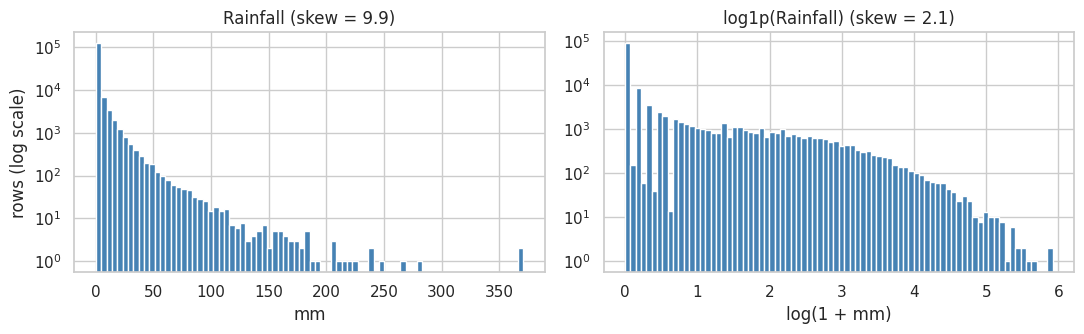

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(df["Rainfall"].dropna(), bins=80, color="steelblue"); axes[0].set_yscale("log")
axes[0].set(title=f"Rainfall (skew = {df['Rainfall'].skew():.1f})", xlabel="mm", ylabel="rows (log scale)")
axes[1].hist(F["Rainfall_log1p"].dropna(), bins=80, color="steelblue"); axes[1].set_yscale("log")
axes[1].set(title=f"log1p(Rainfall) (skew = {F['Rainfall_log1p'].skew():.1f})", xlabel="log(1 + mm)")
plt.tight_layout(); savefig("p1_rainfall_log"); plt.show()

### 1.5 Patterns in the data: what distinguishes the zones?

The **seasonal cycle** is the textbook definition of the Köppen classes, so we expect it to be visible in the data.

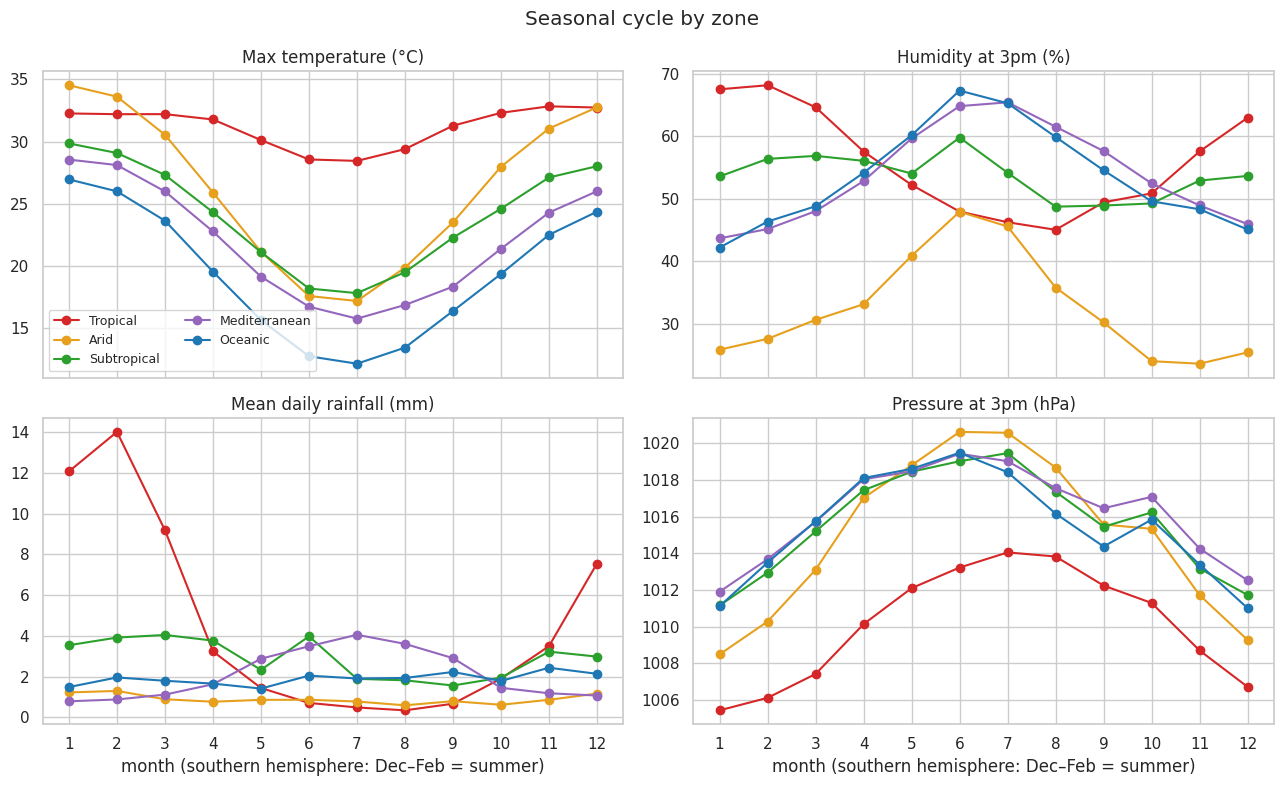

In [14]:
monthly = df.assign(month=df["Date"].dt.month).groupby(["Zone", "month"])[
    ["MaxTemp", "Humidity3pm", "Rainfall", "Pressure3pm"]].mean()
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
titles = {"MaxTemp": "Max temperature (°C)", "Humidity3pm": "Humidity at 3pm (%)",
          "Rainfall": "Mean daily rainfall (mm)", "Pressure3pm": "Pressure at 3pm (hPa)"}
for ax, col in zip(axes.ravel(), titles):
    for zone in ZONE_ORDER:
        ax.plot(range(1, 13), monthly.loc[zone, col], marker="o", color=ZONE_COLORS[zone], label=zone)
    ax.set(title=titles[col]); ax.set_xticks(range(1, 13))
for ax in axes[1]:
    ax.set_xlabel("month (southern hemisphere: Dec–Feb = summer)")
axes[0, 0].legend(ncol=2, fontsize=9)
plt.suptitle("Seasonal cycle by zone"); plt.tight_layout(); savefig("p1_seasonal_cycle"); plt.show()

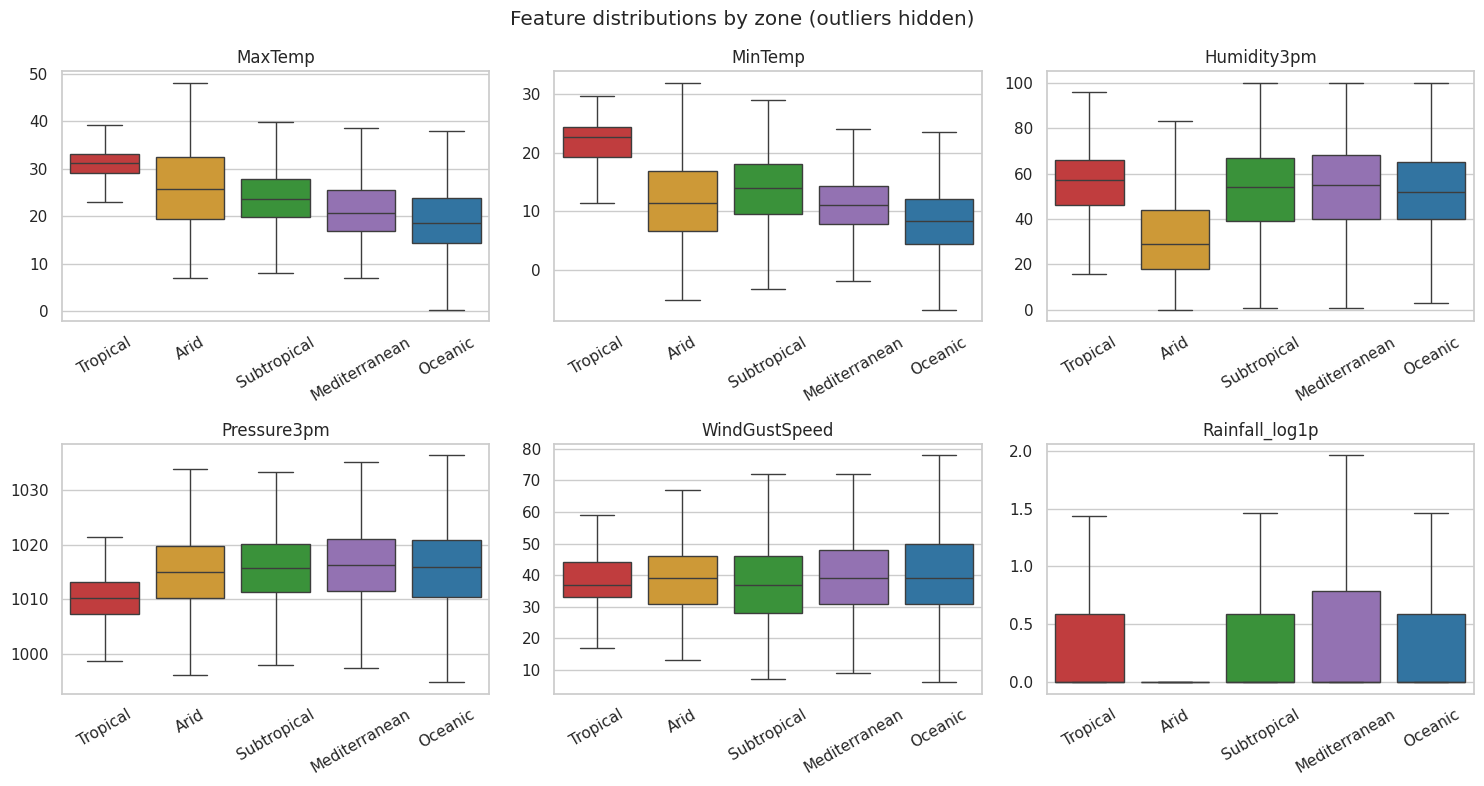

In [15]:
show = ["MaxTemp", "MinTemp", "Humidity3pm", "Pressure3pm", "WindGustSpeed", "Rainfall_log1p"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), show):
    sns.boxplot(x=df["Zone"], y=F[col], order=ZONE_ORDER, hue=df["Zone"], hue_order=ZONE_ORDER,
                palette=ZONE_COLORS, showfliers=False, legend=False, ax=ax)
    ax.set(title=col, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Feature distributions by zone (outliers hidden)")
plt.tight_layout(); savefig("p1_boxplots"); plt.show()

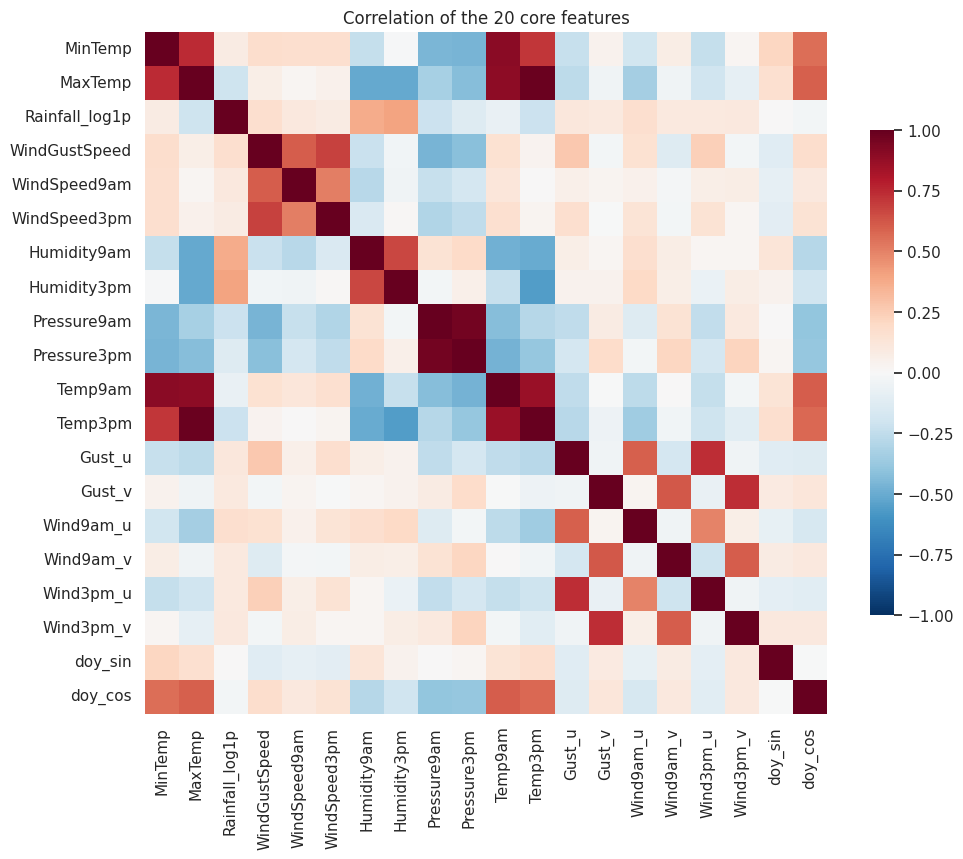

most correlated pairs:
 MaxTemp      Temp3pm        0.985
Pressure9am  Pressure3pm    0.961
MinTemp      Temp9am        0.902
MaxTemp      Temp9am        0.891
Temp9am      Temp3pm        0.864
MinTemp      MaxTemp        0.744


In [16]:
corr = X_core.corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, ax=ax, cbar_kws={"shrink": .7})
ax.set_title("Correlation of the 20 core features"); savefig("p1_correlation"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
print("most correlated pairs:\n", pairs.head(6).round(3).to_string())

### 1.6 Sensitivity check: does the feature-set / indicator choice create a station shortcut?

A quick logistic-regression probe (full evaluation follows in Parts 4–5). Two splits answer two different questions:

* **random stratified 70/30** — can the model recognise a *new day* of stations it has seen?
* **station-grouped 70/30** — can it recognise the zone of *stations it has never seen*?

If a preprocessing choice helps only under the random split, it is helping the model memorise stations.

In [17]:
idx = np.arange(len(df))
rand_tr, rand_te = train_test_split(idx, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
grp_tr, grp_te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=RANDOM_STATE).split(idx, y, groups))
print("grouped split: test stations =", groups.iloc[grp_te].nunique(), "| overlap with train stations =",
      len(set(groups.iloc[grp_te]) & set(groups.iloc[grp_tr])))

def sensitivity_probe():
    rows = []
    for fs, ind in [("core", False), ("full", False), ("full", True)]:
        X = F[FEATURE_SETS[fs]]
        for split, (a, b) in {"random": (rand_tr, rand_te), "grouped": (grp_tr, grp_te)}.items():
            model = make_pipeline(build_preprocessor(add_indicator=ind), LogisticRegression(max_iter=3000))
            model.fit(X.iloc[a], y[a]); pred = model.predict(X.iloc[b])
            rows.append({"features": fs, "missing indicator": ind, "split": split,
                         "accuracy": accuracy_score(y[b], pred), "macro-F1": f1_score(y[b], pred, average="macro")})
    return rows

rows = cached("p1_sensitivity", sensitivity_probe, seed=RANDOM_STATE, sets=repr(FEATURE_SETS))
sens = pd.DataFrame(rows).pivot_table(index=["features", "missing indicator"], columns="split",
                                      values=["accuracy", "macro-F1"]).round(3)
sens

grouped split: test stations = 15 | overlap with train stations = 0


accuracy        macro-F1       
split                       grouped random  grouped random
features missing indicator                                
core     False                0.563  0.599    0.561  0.615
full     False                0.569  0.606    0.567  0.622
         True                 0.572  0.671    0.558  0.688

**Reading the table.** Adding missing indicators raises the random-split score clearly but gives no gain on unseen
stations — the improvement comes from recognising stations, not climate. Adding the four sensor columns without
indicators changes little. We therefore use the **`core` feature set without missing indicators** as the default
for all later parts, and keep `full` + indicators only as a documented counter-example.

### 1.7 Summary of Part 1

**Methods.** Köppen-derived 5-class target from BoM coordinates; explicit removal of `Location`, `RainTomorrow`
(and a check for `RISK_MM`); NorfolkIsland dropped (no Köppen label on the 3 km grid); wind as `(u, v)` vectors
with calm = 0; day-of-year as `sin/cos`; `log1p` for rainfall; `RainToday` dropped as redundant; median imputation
and standardisation inside a pipeline fitted on training data only; 20 `core` features.

**Observations.**
1. Classes are moderately imbalanced (Subtropical 32% vs Tropical 7.6%), so we report macro-averaged metrics.
2. Missingness is structured by station, and the missing pattern alone identifies stations ≈10× better than chance —
   a concrete leakage route that we close by excluding whole-station sensor columns and indicators.
3. The seasonal cycle separates the zones in the way Köppen defines them: Tropical has the summer wet season,
   Mediterranean the winter rain, Arid the lowest humidity, Oceanic the coolest summers.
4. Temperature variables are highly correlated (e.g. `MaxTemp`–`Temp3pm`), which matters for the interpretation of
   linear-model coefficients later.

## 2. Data Visualization with t-SNE

**Question.** Do days from different climate zones separate naturally in the 20-dimensional feature space?

### 2.1 Sample and caching

t-SNE costs roughly O(n log n) per iteration with a large constant, so we embed a **balanced sample of 1,200 days per zone
(6,000 days)**. Balancing keeps the small Tropical class (7.6% of rows) from being drowned by Subtropical (32%) in the
picture. The same sample is reused for clustering in Part 3.

The preprocessor (median imputation + standardisation, no missing indicators) is fitted on this sample. No labels
are used anywhere in t-SNE; `Zone` is only used afterwards to colour the points.

Each embedding takes 20–30 s. Embeddings are cached in `data/processed/tsne/`; the file name contains a hash of
the input matrix and the parameters, so a changed input can never reuse a stale result. Set `RECOMPUTE_TSNE = True`
to ignore the cache.

In [18]:
N_PER_ZONE = 1200
sample_idx = df.groupby("Zone", group_keys=False).sample(n=N_PER_ZONE, random_state=RANDOM_STATE).index
X_vis = build_preprocessor().fit_transform(F.loc[sample_idx, FEATURE_SETS["core"]])
y_vis = df.loc[sample_idx, "Zone"].values
g_vis = groups.loc[sample_idx].values
month_vis = df.loc[sample_idx, "Date"].dt.month.values
SEASON_OF_MONTH = {12: "Summer", 1: "Summer", 2: "Summer", 3: "Autumn", 4: "Autumn", 5: "Autumn",
                   6: "Winter", 7: "Winter", 8: "Winter", 9: "Spring", 10: "Spring", 11: "Spring"}
season_vis = np.array([SEASON_OF_MONTH[m] for m in month_vis])
print("sample:", X_vis.shape, "| stations in sample:", len(set(g_vis)))

TSNE_DIR = DATA_DIR / "processed" / "tsne"; TSNE_DIR.mkdir(parents=True, exist_ok=True)
RECOMPUTE_TSNE = False

def tsne_cached(X, n_components=2, perplexity=30, seed=RANDOM_STATE):
    key = hashlib.sha256(np.ascontiguousarray(X).tobytes()).hexdigest()[:12]
    path = TSNE_DIR / f"tsne_{key}_d{n_components}_p{perplexity}_s{seed}.npy"
    if path.exists() and not RECOMPUTE_TSNE:
        return np.load(path)
    E = TSNE(n_components=n_components, perplexity=perplexity, init="pca", learning_rate="auto",
             max_iter=1000, random_state=seed).fit_transform(X)
    np.save(path, E)
    return E

def knn_purity(E, labels, k=10):
    # 5-fold accuracy of a k-NN classifier on the embedding = how often a point's neighbours share its label
    return cross_val_score(KNeighborsClassifier(n_neighbors=k), E, labels, cv=5).mean()

def knn_kappa(E, labels, k=10):
    # the same k-NN predictions, scored with Cohen's kappa = (accuracy - chance agreement) / (1 - chance agreement),
    # so that label sets with different numbers of classes / class shares can be compared
    pred = cross_val_predict(KNeighborsClassifier(n_neighbors=k), E, labels, cv=5)
    return cohen_kappa_score(labels, pred)

sample: (6000, 20) | stations in sample: 48


### 2.2 Main embedding (perplexity 30)

We colour the same embedding three ways: by zone (our target), by month, and by maximum temperature.

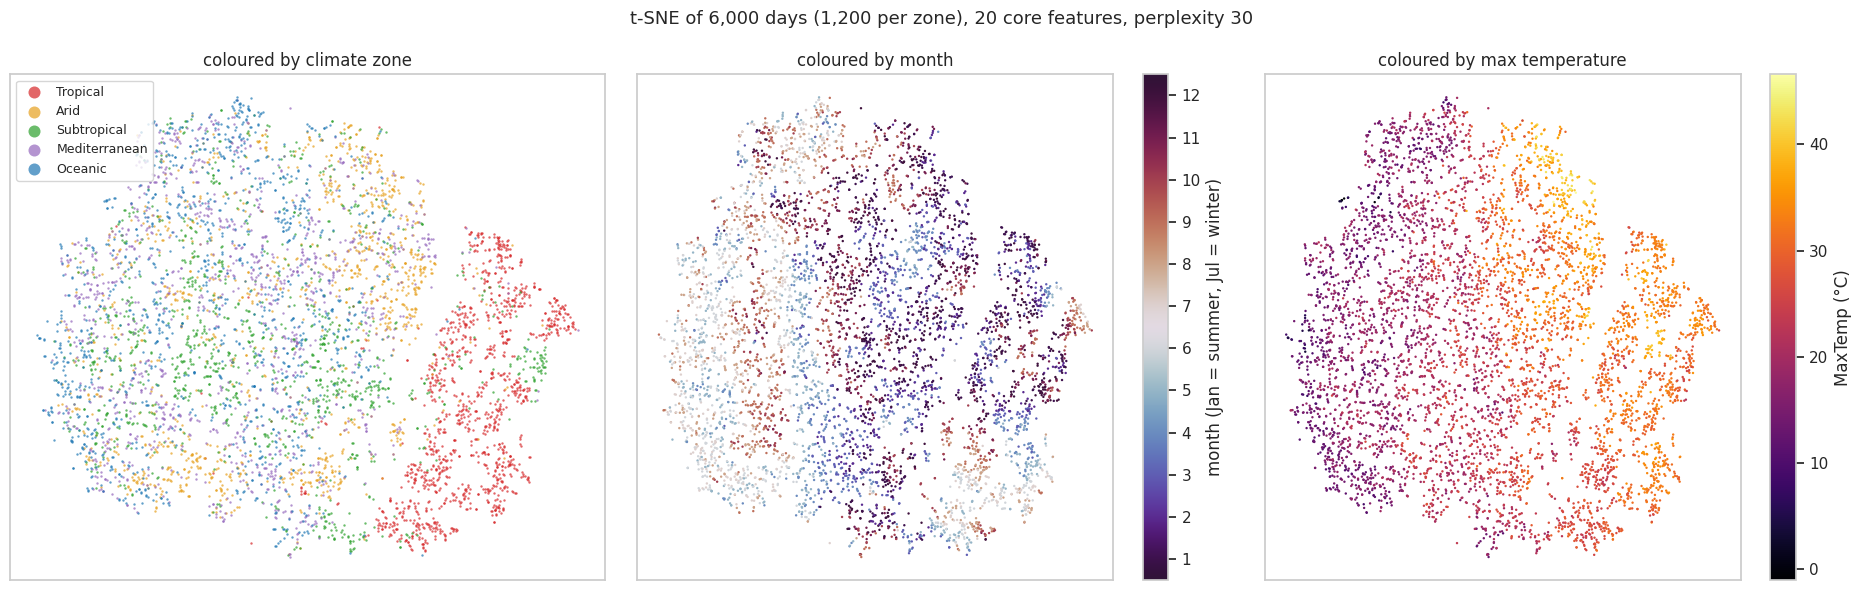

In [19]:
E2 = tsne_cached(X_vis, perplexity=30)

def scatter_by_zone(ax, E, labels=y_vis, s=3):
    for zone in ZONE_ORDER:
        m = labels == zone
        ax.scatter(E[m, 0], E[m, 1], s=s, color=ZONE_COLORS[zone], label=zone, alpha=0.7, linewidths=0)
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
scatter_by_zone(axes[0], E2)
axes[0].legend(markerscale=5, loc="upper left", fontsize=9); axes[0].set_title("coloured by climate zone")
sc = axes[1].scatter(E2[:, 0], E2[:, 1], s=3, c=month_vis, cmap="twilight_shifted", vmin=0.5, vmax=12.5, linewidths=0)
cb = plt.colorbar(sc, ax=axes[1], ticks=range(1, 13)); cb.set_label("month (Jan = summer, Jul = winter)")
axes[1].set_title("coloured by month"); axes[1].set_xticks([]); axes[1].set_yticks([])
sc = axes[2].scatter(E2[:, 0], E2[:, 1], s=3, c=F.loc[sample_idx, "MaxTemp"], cmap="inferno", linewidths=0)
plt.colorbar(sc, ax=axes[2]).set_label("MaxTemp (°C)")
axes[2].set_title("coloured by max temperature"); axes[2].set_xticks([]); axes[2].set_yticks([])
fig.suptitle("t-SNE of 6,000 days (1,200 per zone), 20 core features, perplexity 30", fontsize=13)
plt.tight_layout(); savefig("p2_tsne_main"); plt.show()

### 2.3 Quantifying what the picture shows

A t-SNE plot is easy to over-read, so we add three descriptive numbers:

* **k-NN purity** — 5-fold accuracy of a 10-nearest-neighbour classifier on the coordinates. It answers
  "how often do a point's neighbours have the same label?" With 5 balanced classes, chance is 0.20.
* **Cohen's κ** of the same predictions. Zone (5 balanced classes), season (4 classes) and station (48 classes)
  have different chance levels, so raw purities cannot be compared across label sets; κ subtracts chance agreement.
* **Trustworthiness** (`sklearn.manifold.trustworthiness`, k = 10) — how well the 2-D neighbourhoods reflect
  the true 20-D neighbourhoods (1 = perfect).

PCA to 2-D is the linear baseline. **These are diagnostics of the picture, not estimates of classification
performance**: t-SNE reshapes neighbourhoods, it used all 6,000 points at once (no train/test separation), and days
of the same station appear on both sides of every k-NN fold. Generalisation is measured in Parts 4–6.

In [20]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_vis)
P2 = pca2.transform(X_vis)
spaces = {"original 20-D": X_vis, "PCA 2-D": P2, "t-SNE 2-D": E2}
quant = pd.DataFrame({
    "purity: zone": {k: knn_purity(v, y_vis) for k, v in spaces.items()},
    "κ: zone": {k: knn_kappa(v, y_vis) for k, v in spaces.items()},
    "purity: season": {k: knn_purity(v, season_vis) for k, v in spaces.items()},
    "κ: season": {k: knn_kappa(v, season_vis) for k, v in spaces.items()},
    "purity: station (48)": {k: knn_purity(v, g_vis) for k, v in spaces.items()},
    "κ: station": {k: knn_kappa(v, g_vis) for k, v in spaces.items()},
    "trustworthiness": {"original 20-D": 1.0, "PCA 2-D": trustworthiness(X_vis, P2, n_neighbors=10),
                        "t-SNE 2-D": trustworthiness(X_vis, E2, n_neighbors=10)},
}).round(3)
print(f"chance level: zone 0.20, season ~0.25, station ~{1 / 48:.3f}; "
      f"PCA explains {pca2.explained_variance_ratio_.sum():.1%} of the variance in 2-D")
quant

chance level: zone 0.20, season ~0.25, station ~0.021; PCA explains 42.2% of the variance in 2-D


,purity: zone,κ: zone,purity: season,κ: season,purity: station (48),κ: station,trustworthiness
original 20-D,0.683,0.604,0.794,0.724,0.354,0.334,1.000
PCA 2-D,0.378,0.223,0.409,0.210,0.113,0.083,0.809
t-SNE 2-D,0.631,0.539,0.663,0.550,0.310,0.290,0.985


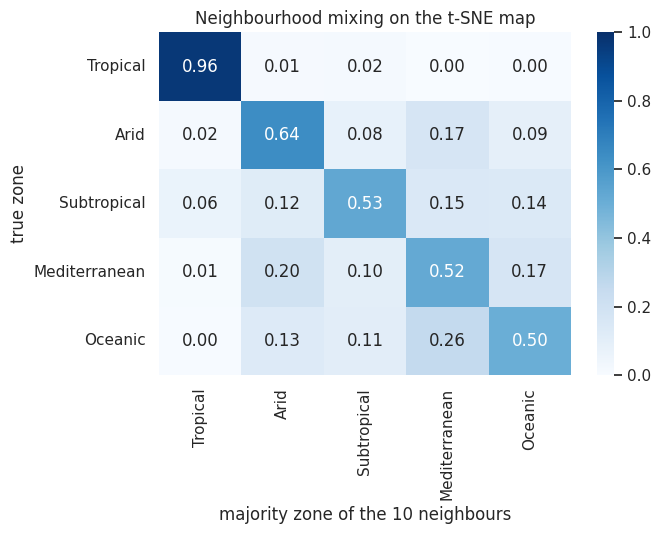

In [21]:
# Which zones are mixed with which? k-NN predictions on the t-SNE map, row-normalised
pred = cross_val_predict(KNeighborsClassifier(n_neighbors=10), E2, y_vis, cv=5)
mix = pd.crosstab(pd.Series(y_vis, name="true zone"), pd.Series(pred, name="majority zone of the 10 neighbours"),
                  normalize="index").loc[ZONE_ORDER, ZONE_ORDER]
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(mix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set_title("Neighbourhood mixing on the t-SNE map")
plt.tight_layout(); savefig("p2_tsne_neighbour_mixing"); plt.show()

### 2.4 Is the structure just the season?

The month colouring shows a strong summer–winter gradient. If season alone drove the layout, zones would
separate much better once the season is held fixed. We check this by (a) embedding summer days and winter days
separately, and (b) removing the two day-of-year features.

In [22]:
feat = FEATURE_SETS["core"]
no_season_cols = [i for i, f in enumerate(feat) if not f.startswith("doy")]
variants = {
    "all days, all 20 features": (X_vis, y_vis),
    "summer days only (Dec–Feb)": (X_vis[season_vis == "Summer"], y_vis[season_vis == "Summer"]),
    "winter days only (Jun–Aug)": (X_vis[season_vis == "Winter"], y_vis[season_vis == "Winter"]),
    "all days, without doy_sin/doy_cos": (X_vis[:, no_season_cols], y_vis),
}
rows, embs = [], {}
for name, (Xv, yv) in variants.items():
    Ev = E2 if name.startswith("all days, all") else tsne_cached(Xv, perplexity=30)
    embs[name] = (Ev, yv)
    sv = season_vis if name.startswith("all days") else None            # season is constant in the 1-season variants
    rows.append({"variant": name, "n": len(yv), "zone purity (20-D)": knn_purity(Xv, yv),
                 "zone purity (t-SNE)": knn_purity(Ev, yv), "zone κ (t-SNE)": knn_kappa(Ev, yv),
                 "season κ (t-SNE)": knn_kappa(Ev, sv) if sv is not None else np.nan})
pd.DataFrame(rows).set_index("variant").round(3)

,n,zone purity (20-D),zone purity (t-SNE),zone κ (t-SNE),season κ (t-SNE)
variant,,,,,
"all days, all 20 features",6000,0.683,0.631,0.539,0.550
summer days only (Dec–Feb),1514,0.688,0.653,0.567,NaN
winter days only (Jun–Aug),1529,0.672,0.642,0.552,NaN
"all days, without doy_sin/doy_cos",6000,0.641,0.591,0.489,0.173


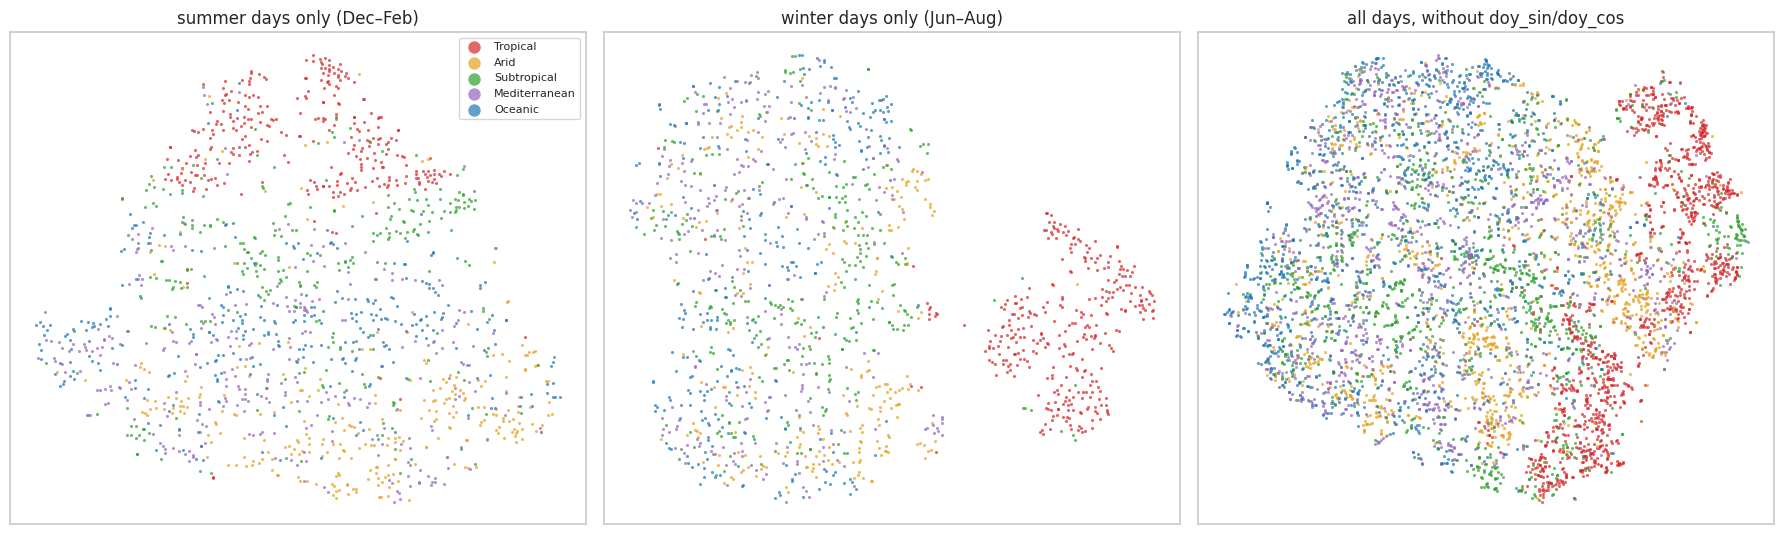

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, name in zip(axes, list(embs)[1:]):
    Ev, yv = embs[name]
    scatter_by_zone(ax, Ev, yv, s=5); ax.set_title(name)
axes[0].legend(markerscale=4, fontsize=8)
plt.tight_layout(); savefig("p2_tsne_season_control"); plt.show()

### 2.5 Sensitivity: perplexity and random seed

Perplexity is roughly the number of effective neighbours each point considers: small values emphasise local
detail, large values preserve more global structure. t-SNE is also non-convex, so different seeds give different
layouts; conclusions should hold for all of them.

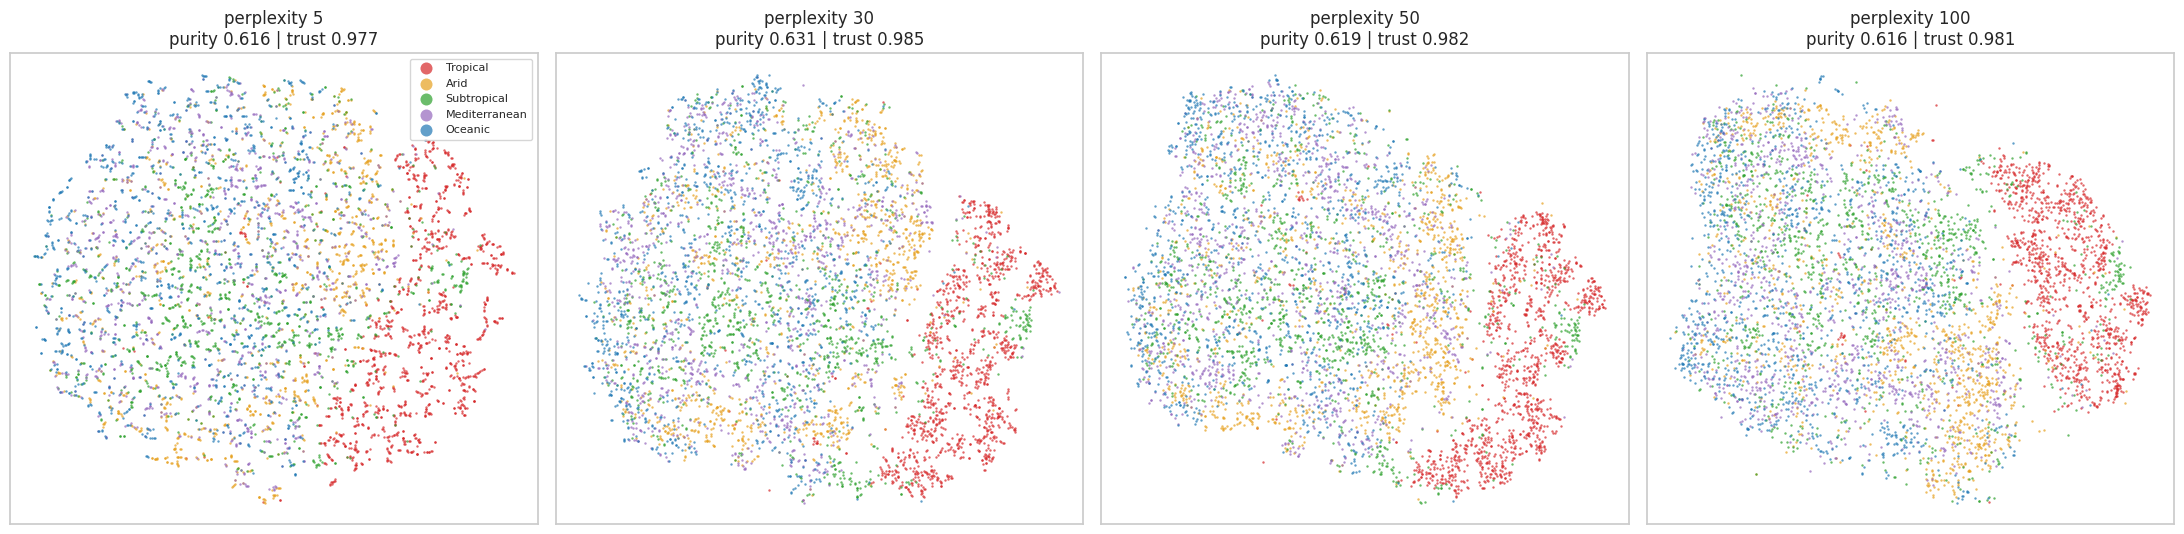

perplexity,5,30,50,100
zone purity,0.616,0.631,0.619,0.616
trustworthiness,0.977,0.985,0.982,0.981


In [24]:
perplexities = [5, 30, 50, 100]
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
perp_rows = []
for ax, p in zip(axes, perplexities):
    Ep = tsne_cached(X_vis, perplexity=p)
    pur, tru = knn_purity(Ep, y_vis), trustworthiness(X_vis, Ep, n_neighbors=10)
    perp_rows.append({"perplexity": p, "zone purity": pur, "trustworthiness": tru})
    scatter_by_zone(ax, Ep); ax.set_title(f"perplexity {p}\npurity {pur:.3f} | trust {tru:.3f}")
axes[0].legend(markerscale=5, fontsize=8)
plt.tight_layout(); savefig("p2_tsne_perplexity"); plt.show()
pd.DataFrame(perp_rows).set_index("perplexity").round(3).T

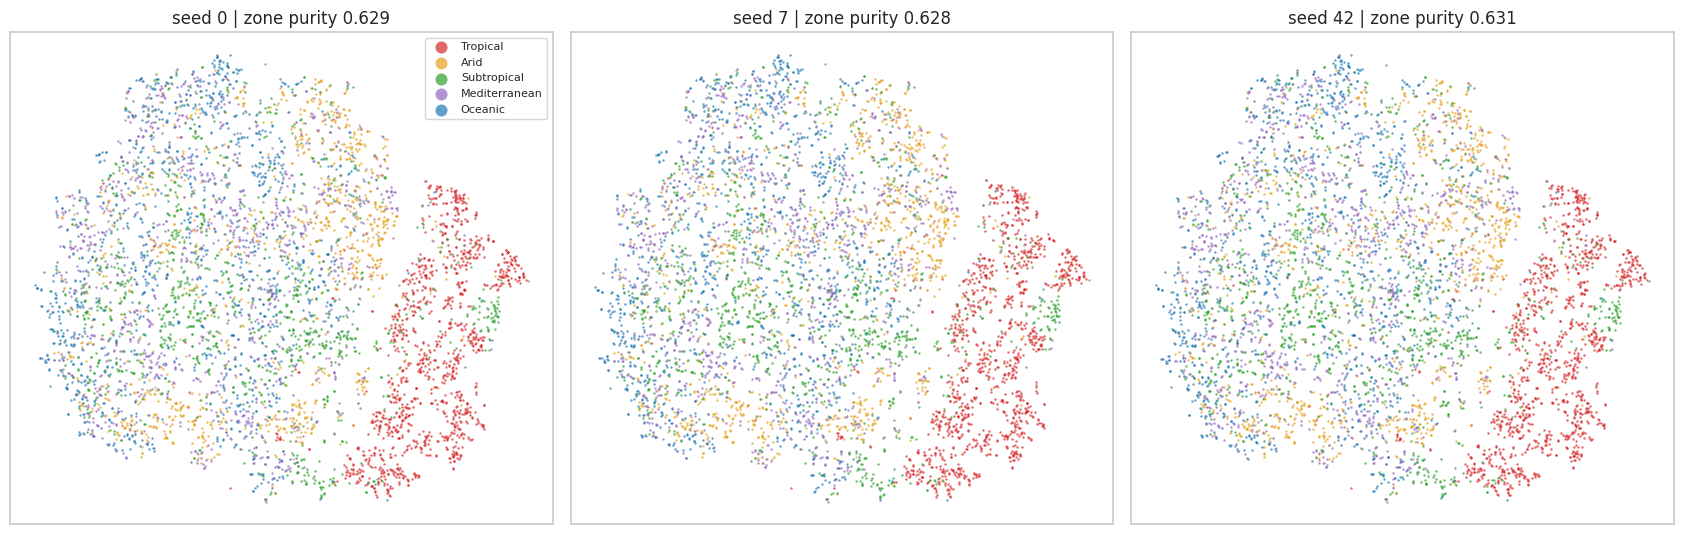

In [25]:
seeds = [0, 7, RANDOM_STATE]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, s in zip(axes, seeds):
    Es = tsne_cached(X_vis, perplexity=30, seed=s)
    scatter_by_zone(ax, Es); ax.set_title(f"seed {s} | zone purity {knn_purity(Es, y_vis):.3f}")
axes[0].legend(markerscale=5, fontsize=8)
plt.tight_layout(); savefig("p2_tsne_seeds"); plt.show()

### 2.6 PCA (linear) vs t-SNE, and a 3-D t-SNE view

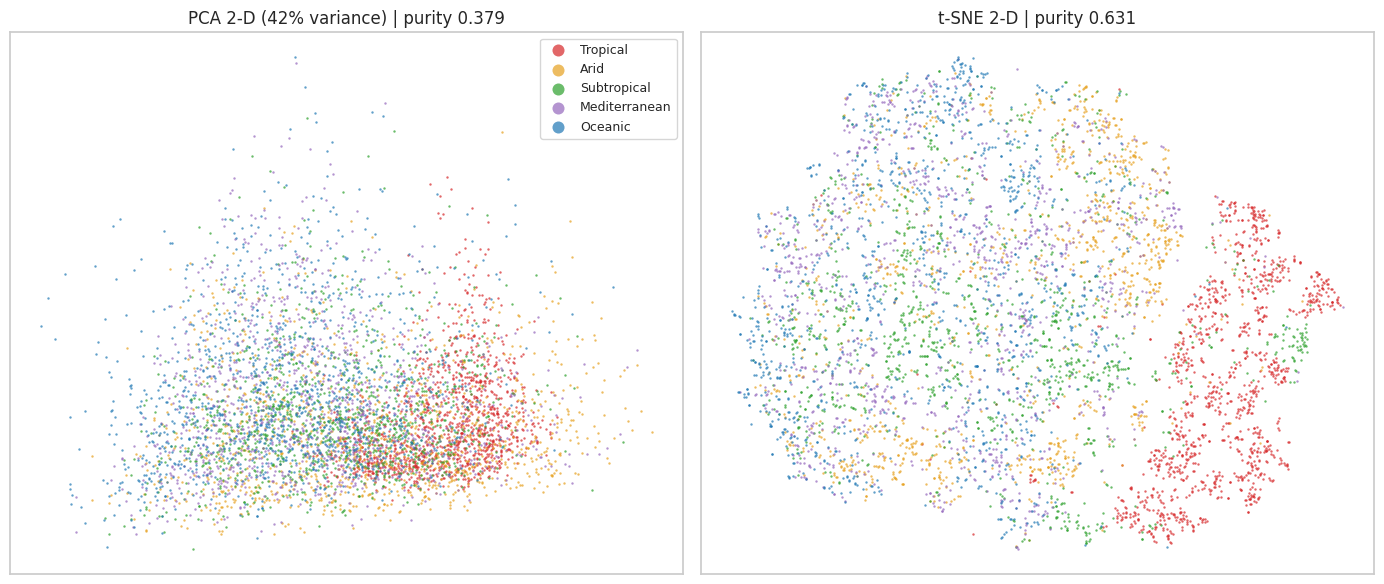

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
scatter_by_zone(axes[0], P2)
axes[0].set_title(f"PCA 2-D ({pca2.explained_variance_ratio_.sum():.0%} variance) | purity {knn_purity(P2, y_vis):.3f}")
scatter_by_zone(axes[1], E2); axes[1].set_title(f"t-SNE 2-D | purity {knn_purity(E2, y_vis):.3f}")
axes[0].legend(markerscale=5, fontsize=9)
plt.tight_layout(); savefig("p2_pca_vs_tsne"); plt.show()

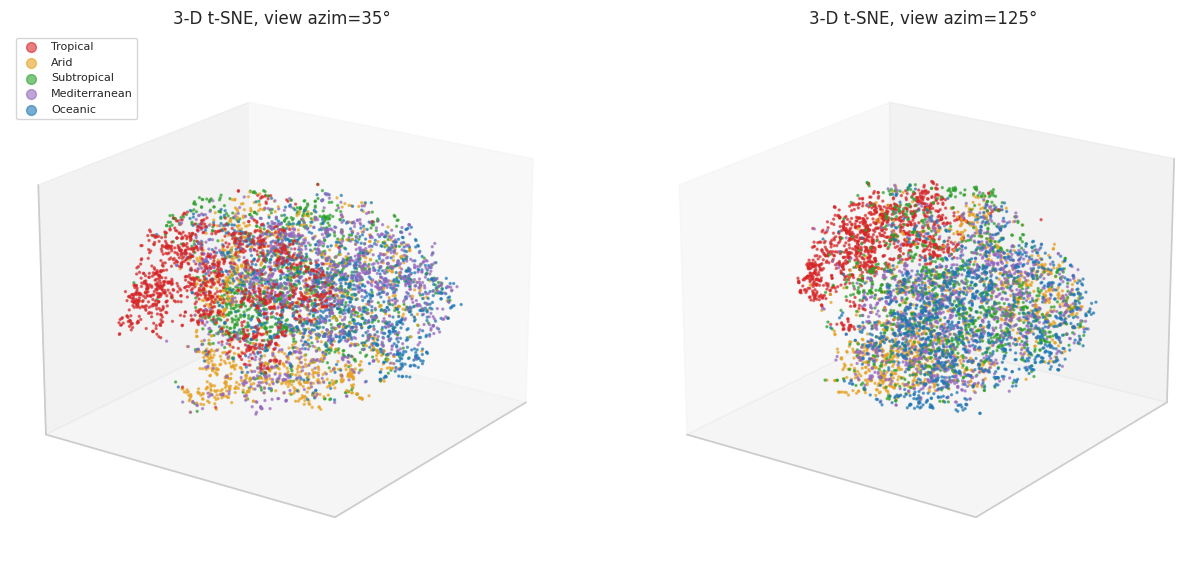

zone purity in 3-D t-SNE: 0.633


In [27]:
E3 = tsne_cached(X_vis, n_components=3, perplexity=30)
fig = plt.figure(figsize=(13, 6))
for i, (elev, azim) in enumerate([(20, 35), (20, 125)]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    for zone in ZONE_ORDER:
        m = y_vis == zone
        ax.scatter(E3[m, 0], E3[m, 1], E3[m, 2], s=2, color=ZONE_COLORS[zone], label=zone, alpha=0.6)
    ax.view_init(elev=elev, azim=azim); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    ax.set_title(f"3-D t-SNE, view azim={azim}°")
fig.axes[0].legend(markerscale=5, fontsize=8, loc="upper left")
plt.tight_layout(); savefig("p2_tsne_3d"); plt.show()
print("zone purity in 3-D t-SNE:", round(knn_purity(E3, y_vis), 3))

### 2.7 Observations and insights

The numbers below refer to the tables printed above.

1. **Only the Tropical zone forms its own region.** Tropical days occupy a separate band of the map, and 96% of
   them have a Tropical majority among their 10 nearest neighbours. The four other zones overlap heavily: their
   neighbourhood agreement is only about 0.50–0.64. Hot nights (MinTemp ≈ 20–25 °C) and low pressure make tropical
   days unlike anything else, while a mild day in Adelaide can look exactly like one in Melbourne.
2. **The season gradient on the map comes mostly from the calendar features.** The month colouring shows summer
   and winter days on opposite sides. With all 20 features, neighbourhoods agree about equally well on season and on
   zone (κ 0.55 vs 0.54; the raw purities 0.663 vs 0.631 are not comparable because the chance levels differ).
   But `doy_sin`/`doy_cos` are inputs, so part of this is by construction: without them, season agreement falls to
   κ 0.17 while zone agreement stays at 0.49. The weather itself carries more information about the zone than about
   the season. Holding the season fixed (summer-only or winter-only embeddings) changes zone κ only slightly
   (0.57 and 0.55 vs 0.54), so season does not explain the overlap between zones.
   The season-specific maps do show *which* zone is distinctive when: in winter the Tropical days form a
   completely separate island (warm, humid dry season vs. cool south), while in summer the Arid days move to
   their own edge (hottest and driest), opposite the hot-and-humid Tropical days.
3. **The confusions follow climate similarity.** Mediterranean and Oceanic are the most mixed pair
   (both southern, temperate, wet winter); Arid days mix most with Mediterranean (hot, dry summers in
   inland South Australia and Victoria). This is the confusion pattern we expect the classifiers in Part 4 to show.
4. **Neighbours also share stations.** Station purity on the map is 0.31 (κ 0.29; chance 0.02): days from the
   same station tend to have similar neighbours. This shows that station-specific information is present in the
   weather variables. It does not by itself show what a classifier will learn; it is a warning that a random
   train/test split *could* reward recognising stations, which Parts 4–6 test directly.
5. **t-SNE vs PCA.** A 2-D PCA projection keeps 42% of the variance and preserves neighbourhoods poorly
   (trustworthiness 0.81 vs 0.985 for t-SNE; zone κ 0.22 vs 0.54). So t-SNE preserves *local neighbourhoods* much
   better than a 2-D linear projection. This alone does not prove that the zone structure is non-linear: two
   principal components discard more than half of the variance.
6. **Robustness.** Zone purity varies by about ±0.01 across perplexities 5–100 and across three random seeds,
   so the conclusions do not depend on these settings. The 2-D maps keep almost all of the 20-D neighbourhood
   information: the 20-D k-NN purity (0.683) is only about 5 points higher than on the t-SNE map (0.631).

**Limitations of reading t-SNE.** Distances between groups, group sizes and the empty space on the map are not
meaningful; t-SNE preserves local neighbourhoods only. The embedding also cannot place new points, so it is used
here for exploration, not as input to the classifiers.

## 3. Clustering Analysis

**Question.** Without labels, can clustering rediscover the climate zones?

We cluster the same balanced sample of 6,000 days as in Part 2 (preprocessed 20-D `core` features). Labels are
never given to the algorithms; `Zone` (and the season) are only used afterwards as *external* references.

### 3.1 Algorithms and why we chose them

| Algorithm | Model of a cluster | Why it is useful here |
|---|---|---|
| **K-means** | a centroid; points go to the nearest one (spherical, similar-size clusters) | the standard baseline; fast enough for repeated runs (stability test) |
| **Agglomerative, Ward linkage** | merges the pair of clusters that increases within-cluster variance least | deterministic (no random initialisation); gives a hierarchy and a dendrogram; Ward optimises the same criterion as K-means, so differences come from greedy merging vs iterative refinement |
| **Gaussian Mixture (full covariance)** | each cluster is a Gaussian with its own covariance; soft assignments | allows elliptical, differently-shaped clusters; has a likelihood, so BIC can choose the number of components |

### 3.2 Choosing the number of clusters

For k = 2 … 10 we record internal metrics (no labels needed) and external metrics (agreement with zone / season):

* **Silhouette** (−1 … 1, higher is better): how much closer a point is to its own cluster than to the next one.
* **Davies–Bouldin** (≥ 0, lower is better): average ratio of within-cluster spread to between-cluster distance.
* **Calinski–Harabasz** (higher is better): between-cluster variance / within-cluster variance.
* **Inertia** (K-means, elbow) and **BIC** (GMM, lower is better).
* **ARI** and **NMI** with `Zone` and with the season (0 = no agreement beyond chance, 1 = identical partition).

In [28]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.mixture import GaussianMixture

def fit_cluster(alg, k, X, seed=RANDOM_STATE):
    # returns (labels, fitted model)
    if alg == "K-means":
        m = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X); return m.labels_, m
    if alg == "Ward":
        m = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X); return m.labels_, m
    if alg == "GMM":
        m = GaussianMixture(n_components=k, covariance_type="full", n_init=2, random_state=seed).fit(X)
        return m.predict(X), m
    raise ValueError(alg)

ALGS = ["K-means", "Ward", "GMM"]
def cluster_sweep():
    rows, labels = [], {}
    for k in range(2, 11):
        for alg in ALGS:
            lab, m = fit_cluster(alg, k, X_vis)
            labels[(alg, k)] = lab
            rows.append({"algorithm": alg, "k": k,
                         "silhouette": silhouette_score(X_vis, lab),
                         "Davies-Bouldin": davies_bouldin_score(X_vis, lab),
                         "Calinski-Harabasz": calinski_harabasz_score(X_vis, lab),
                         "ARI zone": adjusted_rand_score(y_vis, lab), "NMI zone": normalized_mutual_info_score(y_vis, lab),
                         "ARI season": adjusted_rand_score(season_vis, lab),
                         "inertia": m.inertia_ if alg == "K-means" else np.nan,
                         "BIC": m.bic(X_vis) if alg == "GMM" else np.nan})
    return pd.DataFrame(rows), labels

sweep, labels_k = cached("p3_sweep", cluster_sweep, n_per_zone=N_PER_ZONE, seed=RANDOM_STATE, ks=(2, 10), algs=tuple(ALGS))
sweep.pivot(index="k", columns="algorithm", values=["silhouette", "Davies-Bouldin", "ARI zone"]).round(3)

silhouette                Davies-Bouldin                ARI zone  \
algorithm        GMM K-means   Ward            GMM K-means   Ward      GMM   
k                                                                            
2              0.085   0.171  0.124          2.940   2.031  2.501    0.106   
3              0.032   0.164  0.117          2.958   1.880  2.150    0.034   
4              0.023   0.137  0.107          2.663   2.042  2.316    0.030   
5              0.005   0.131  0.097          2.775   2.080  2.233    0.020   
6              0.008   0.129  0.064          2.974   2.008  2.321    0.037   
7             -0.016   0.106  0.059          3.182   1.985  2.177    0.045   
8             -0.010   0.108  0.061          3.138   2.000  2.298    0.048   
9             -0.016   0.108  0.058          3.417   2.019  2.544    0.042   
10            -0.036   0.101  0.041          3.322   2.051  2.555    0.049   

                          
algorithm K-means   Ward  
k                         
2           0.106  0.121  
3           0.098  0.114  
4           0.075  0.104  
5           0.096  0.126  
6           0.108  0.120  
7           0.109  0.103  
8           0.099  0.121  
9           0.101  0.117  
10          0.098  0.116

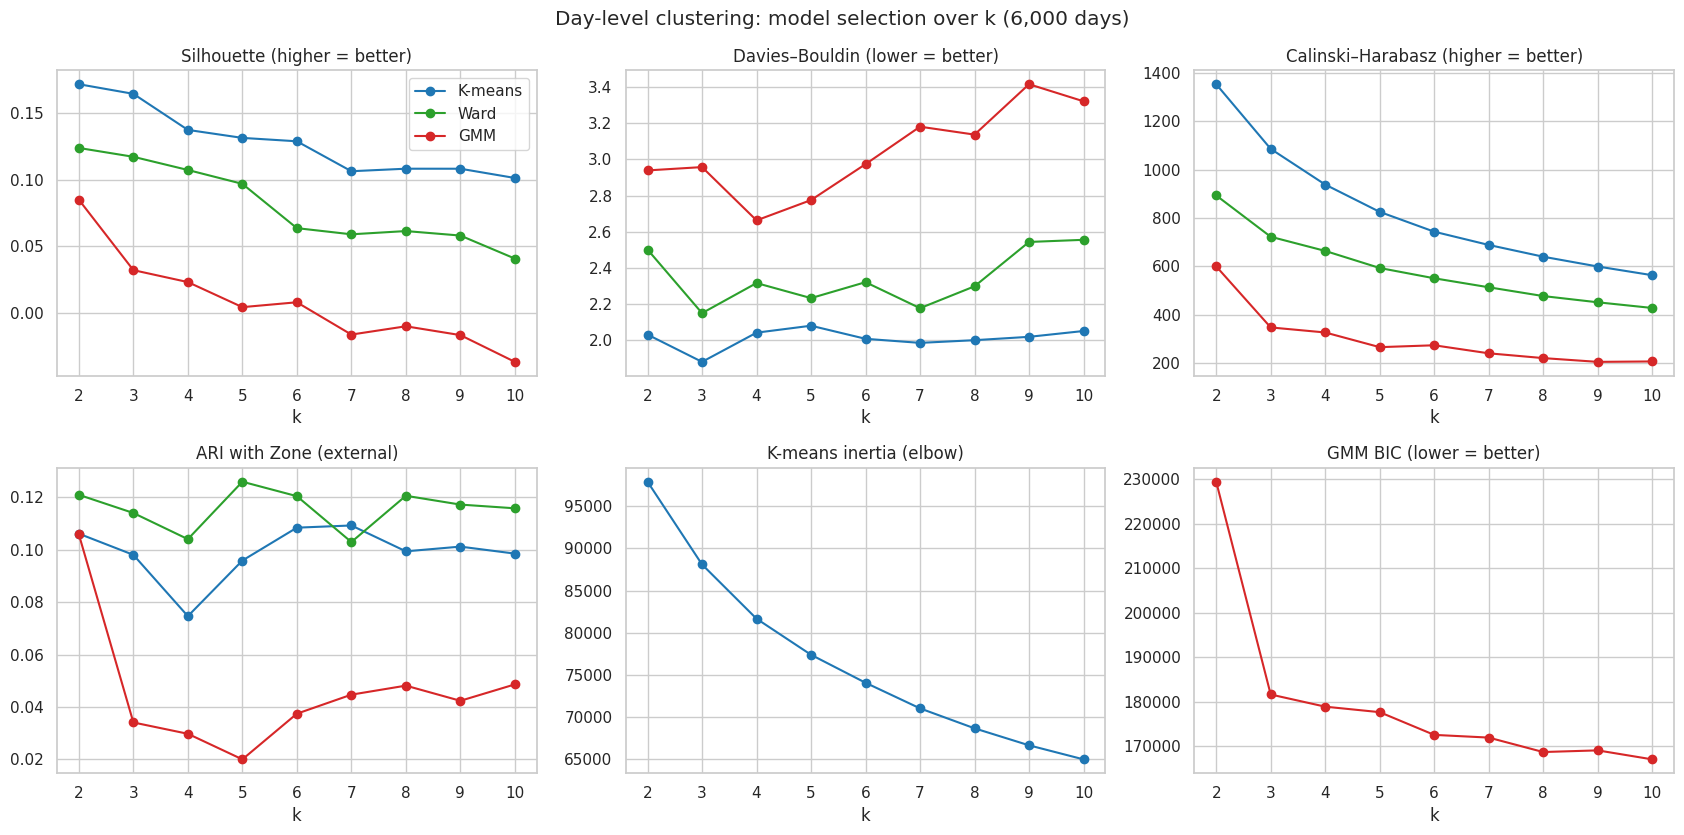

In [29]:
ALG_COLORS = {"K-means": "#1f77b4", "Ward": "#2ca02c", "GMM": "#d62728"}
panels = [("silhouette", "Silhouette (higher = better)"), ("Davies-Bouldin", "Davies–Bouldin (lower = better)"),
          ("Calinski-Harabasz", "Calinski–Harabasz (higher = better)"), ("ARI zone", "ARI with Zone (external)"),
          ("inertia", "K-means inertia (elbow)"), ("BIC", "GMM BIC (lower = better)")]
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for ax, (col, title) in zip(axes.ravel(), panels):
    for alg in ALGS:
        s = sweep[sweep["algorithm"] == alg]
        if s[col].notna().any():
            ax.plot(s["k"], s[col], marker="o", color=ALG_COLORS[alg], label=alg)
    ax.set(title=title, xlabel="k"); ax.set_xticks(range(2, 11))
axes[0, 0].legend()
plt.suptitle("Day-level clustering: model selection over k (6,000 days)"); plt.tight_layout()
savefig("p3_k_selection"); plt.show()

**Stability (all three algorithms).** A good clustering should not change much when the data change slightly.
For every algorithm and every k we refit on 10 random subsamples containing 80% of the 6,000 days (drawn without
replacement) and compare the subsample's partition with the reference partition **on the same days** (ARI;
1 = identical). This needs no rule for assigning left-out points, so it treats K-means, Ward (which has no
`predict`) and GMM identically. Each (algorithm, k) result is cached separately.

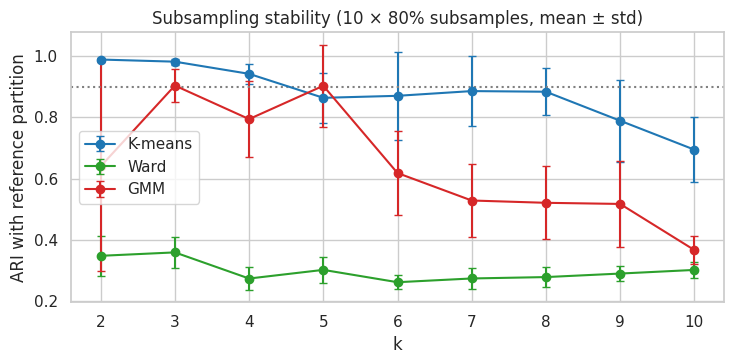

k,2,3,4,5,6,7,8,9,10
algorithm,,,,,,,,,
GMM,0.640,0.904,0.795,0.904,0.618,0.528,0.521,0.517,0.366
K-means,0.990,0.983,0.943,0.864,0.871,0.886,0.884,0.789,0.695
Ward,0.347,0.358,0.273,0.301,0.261,0.273,0.278,0.289,0.301


In [30]:
from scipy.cluster.hierarchy import fcluster
N_SUB, SUB_FRAC = 10, 0.8
SUB_IDX = [np.random.default_rng(RANDOM_STATE + b).choice(len(X_vis), size=int(SUB_FRAC * len(X_vis)), replace=False)
           for b in range(N_SUB)]

def stability_kmeans_gmm(alg, k):
    ref, scores = labels_k[(alg, k)], []
    for b, idx in enumerate(SUB_IDX):
        lab, _ = fit_cluster(alg, k, X_vis[idx], seed=b)
        scores.append(adjusted_rand_score(ref[idx], lab))
    return scores

def stability_ward():
    # one Ward tree per subsample, cut at every k
    out = {k: [] for k in range(2, 11)}
    for idx in SUB_IDX:
        Z_sub = linkage(X_vis[idx], method="ward")
        for k in out:
            out[k].append(adjusted_rand_score(labels_k[("Ward", k)][idx], fcluster(Z_sub, t=k, criterion="maxclust")))
    return out

STAB_PARAMS = dict(n_sub=N_SUB, frac=SUB_FRAC, seed=RANDOM_STATE, scheme="subsample")
stab_scores = {("Ward", k): v for k, v in cached("p3_stab_ward", stability_ward, **STAB_PARAMS).items()}
for alg in ["K-means", "GMM"]:
    for k in range(2, 11):
        stab_scores[(alg, k)] = cached(f"p3_stab_{alg}_{k}", lambda a=alg, k=k: stability_kmeans_gmm(a, k), **STAB_PARAMS)
stab = pd.DataFrame([{"algorithm": a, "k": k, "stability": np.mean(v), "stability std": np.std(v)}
                     for (a, k), v in stab_scores.items()])
sweep = sweep.drop(columns=[c for c in ["stability", "stability std"] if c in sweep]).merge(stab, on=["algorithm", "k"])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for alg in ALGS:
    st_ = sweep[sweep["algorithm"] == alg]
    ax.errorbar(st_["k"], st_["stability"], yerr=st_["stability std"], marker="o", capsize=3, color=ALG_COLORS[alg], label=alg)
ax.axhline(0.9, ls=":", color="grey"); ax.set_xticks(range(2, 11))
ax.set(xlabel="k", ylabel="ARI with reference partition", title="Subsampling stability (10 × 80% subsamples, mean ± std)")
ax.legend(); plt.tight_layout(); savefig("p3_stability"); plt.show()
sweep.pivot(index="k", columns="algorithm", values="stability").round(3).T

**Why does GMM score so badly on the internal metrics?** With full covariance it can put a component on any
low-dimensional "spike" in the data. Rainfall is exactly 0 on 63% of days, so a single standardised value is
shared by most of the sample; GMM can give one component (almost) zero variance in that direction and an
arbitrarily high likelihood. We check the variance of `Rainfall_log1p` inside each component:

In [31]:
_, gmm5 = fit_cluster("GMM", 5, X_vis)
ri = FEATURE_SETS["core"].index("Rainfall_log1p")
dry = X_vis[:, ri] == X_vis[:, ri].min()
gmm_lab = gmm5.predict(X_vis)
pd.DataFrame({
    "weight": gmm5.weights_,
    "var(Rainfall_log1p) inside component": gmm5.covariances_[:, ri, ri],
    "share of dry days (Rainfall = 0)": [dry[gmm_lab == c].mean() for c in range(5)],
}).round(4)

,weight,var(Rainfall_log1p) inside component,share of dry days (Rainfall = 0)
0,0.6151,0.0000,1.0000
1,0.1062,0.8763,0.0712
2,0.0983,1.5468,0.2973
3,0.0801,2.0561,0.1860
4,0.1003,1.4991,0.0166


One component contains essentially all dry days and has zero rainfall variance: GMM is splitting the data into
"rain / no rain" rather than into compact weather groups. BIC keeps preferring more components because each extra
component can exploit another spike (calm wind = 0, imputed medians). This is a property of the data (point masses
from zeros and imputation), not a bug, and it explains why the likelihood-based criterion (BIC) and the
geometry-based criteria (silhouette, Davies–Bouldin) disagree for GMM.

**GMM settings and a check of the degeneracy.** All GMMs above use scikit-learn defaults except `n_init = 2`:
`covariance_type = "full"`, `reg_covar = 1e-6` (added to the covariance diagonals), `max_iter = 100`, `tol = 1e-3`,
k-means initialisation. Below we report convergence and refit with a larger `reg_covar`, which puts a floor under
every variance and should remove the zero-variance "dry" component if the degeneracy is the problem.

In [32]:
def gmm_sensitivity():
    rows = []
    for k in [3, 5]:
        for reg in [1e-6, 1e-3, 1e-2, 1e-1]:
            g = GaussianMixture(n_components=k, covariance_type="full", n_init=2, reg_covar=reg,
                                random_state=RANDOM_STATE).fit(X_vis)
            lab = g.predict(X_vis)
            rows.append({"k": k, "reg_covar": reg, "converged": g.converged_, "EM iterations": g.n_iter_,
                         "largest weight": g.weights_.max(),
                         "min var(Rainfall_log1p)": g.covariances_[:, ri, ri].min(),
                         "silhouette": silhouette_score(X_vis, lab) if len(np.unique(lab)) > 1 else np.nan,
                         "Davies-Bouldin": davies_bouldin_score(X_vis, lab) if len(np.unique(lab)) > 1 else np.nan,
                         "ARI zone": adjusted_rand_score(y_vis, lab), "BIC": g.bic(X_vis)})
    return pd.DataFrame(rows)

gmm_sens = cached("p3_gmm_sensitivity", gmm_sensitivity, n_per_zone=N_PER_ZONE, seed=RANDOM_STATE, version=1)
gmm_sens.round(4)

,k,reg_covar,converged,EM iterations,largest weight,min var(Rainfall_log1p),silhouette,Davies-Bouldin,ARI zone,BIC
0,3,0.000,True,26,0.6313,0.0000,0.0322,2.9579,0.0341,181636.6187
1,3,0.001,True,29,0.5543,0.0010,0.0174,3.1174,0.0563,207159.2151
2,3,0.010,True,28,0.5091,0.0156,0.0431,2.9579,0.1365,216517.0142
3,3,0.100,True,24,0.4099,0.1451,0.0999,2.6995,0.0796,243419.7182
4,5,0.000,True,30,0.6151,0.0000,0.0045,2.7754,0.0201,177673.6266
5,5,0.001,True,40,0.4805,0.0010,0.0275,2.8477,0.0344,200830.6126
6,5,0.010,True,27,0.3722,0.0131,0.0490,2.7112,0.0604,210004.3633
7,5,0.100,True,34,0.3266,0.1286,0.0742,2.3471,0.0777,239361.8706


All eight fits in the table converged (24–40 EM iterations). With the default `reg_covar = 1e-6` the "dry" component keeps zero
rainfall variance and 61–63% of the weight. Raising `reg_covar` to 0.1 gives every component a rainfall variance of
at least 0.13, lowers the largest weight to 0.33–0.41 and roughly triples the silhouette at k = 3 (0.032 → 0.100).
GMM nevertheless stays below K-means (silhouette 0.164, Davies–Bouldin 1.88 vs 2.70), and its ARI with the zones
stays ≤ 0.14. The degeneracy explains part of GMM's poor scores; the rest is that these weather data do not form
well-separated Gaussian groups. The sweep keeps the default GMM; this table is a sensitivity check.

### 3.3 Choosing the best day-level clustering

In [33]:
# Selection rule, applied to all 27 (algorithm, k) solutions:
#   1. eligible = subsampling stability >= 0.90 (the partition must be reproducible);
#   2. score    = mean of the ranks on silhouette (high), Davies-Bouldin (low) and Calinski-Harabasz (high);
#   3. choose the eligible solution with the best (lowest) mean rank.
# External metrics (ARI/NMI with zone or season) are NOT used for the choice: they measure agreement with our
# question, not clustering quality, and are reported only for interpretation.
rank = sweep[["algorithm", "k"]].copy()
rank["rank silhouette"] = sweep["silhouette"].rank(ascending=False)
rank["rank DB"] = sweep["Davies-Bouldin"].rank(ascending=True)
rank["rank CH"] = sweep["Calinski-Harabasz"].rank(ascending=False)
rank["mean rank"] = rank[["rank silhouette", "rank DB", "rank CH"]].mean(axis=1)
rank["stability"] = sweep["stability"]
rank["eligible"] = rank["stability"] >= 0.90
rank = rank.sort_values("mean rank")
best_row = rank[rank["eligible"]].iloc[0]
ALG_BEST, K_BEST = best_row["algorithm"], int(best_row["k"])
print(f"selected: {ALG_BEST}, k = {K_BEST}")
display(rank.head(8).round(3))

best = sweep[sweep["k"] == K_BEST].set_index("algorithm")[
    ["silhouette", "Davies-Bouldin", "Calinski-Harabasz", "BIC", "ARI zone", "NMI zone", "ARI season", "stability"]]
print(f"k = {K_BEST}: comparison of the three algorithms")
best.round(3)

selected: K-means, k = 3


,algorithm,k,rank silhouette,rank DB,rank CH,mean rank,stability,eligible
3,K-means,3,2.0,1.0,2.0,1.667,0.983,True
0,K-means,2,1.0,6.0,1.0,2.667,0.990,True
6,K-means,4,3.0,7.0,3.0,4.333,0.943,True
12,K-means,6,5.0,4.0,6.0,5.000,0.871,False
9,K-means,5,4.0,9.0,5.0,6.000,0.864,False
15,K-means,7,11.0,2.0,8.0,7.000,0.886,False
18,K-means,8,8.0,3.0,10.0,7.000,0.884,False
4,Ward,3,7.0,10.0,7.0,8.000,0.358,False


k = 3: comparison of the three algorithms


,silhouette,Davies-Bouldin,Calinski-Harabasz,BIC,ARI zone,NMI zone,ARI season,stability
algorithm,,,,,,,,
K-means,0.164,1.880,1085.792,NaN,0.098,0.122,0.096,0.983
Ward,0.117,2.150,722.379,NaN,0.114,0.150,0.049,0.358
GMM,0.032,2.958,347.402,181636.619,0.034,0.097,0.005,0.904


**Decision: K-means with k = 3.** The rule in the code cell above was written down after the first version of this
analysis (it formalises the reasoning we had used) and it reproduces the original choice:

* Eligible solutions (stability ≥ 0.90) are K-means with k = 2–4 and GMM with k = 3 and 5. Ward is never eligible.
* K-means k = 3 has the best mean rank (1.67): second on silhouette (0.164 vs 0.171 at k = 2), **first on
  Davies–Bouldin among all 27 solutions** (1.88), second on Calinski–Harabasz, stability 0.98. K-means k = 2 is
  first on two metrics but only sixth on Davies–Bouldin (mean rank 2.67).
* **Ward is the least stable algorithm** (0.26–0.36 for every k): removing 20% of the days changes which large
  groups are merged first, and a greedy merge can never be undone. It is deterministic for fixed data, but not
  robust to small changes in the data.
* GMM is stable at k = 3 and 5 but degenerate (above), and ranks far behind on the internal metrics.
* The extra cluster at k = 3 is physically meaningful (next section): it splits cool days into two different
  weather regimes that k = 2 merges.

### 3.4 Visualising and interpreting the clusters

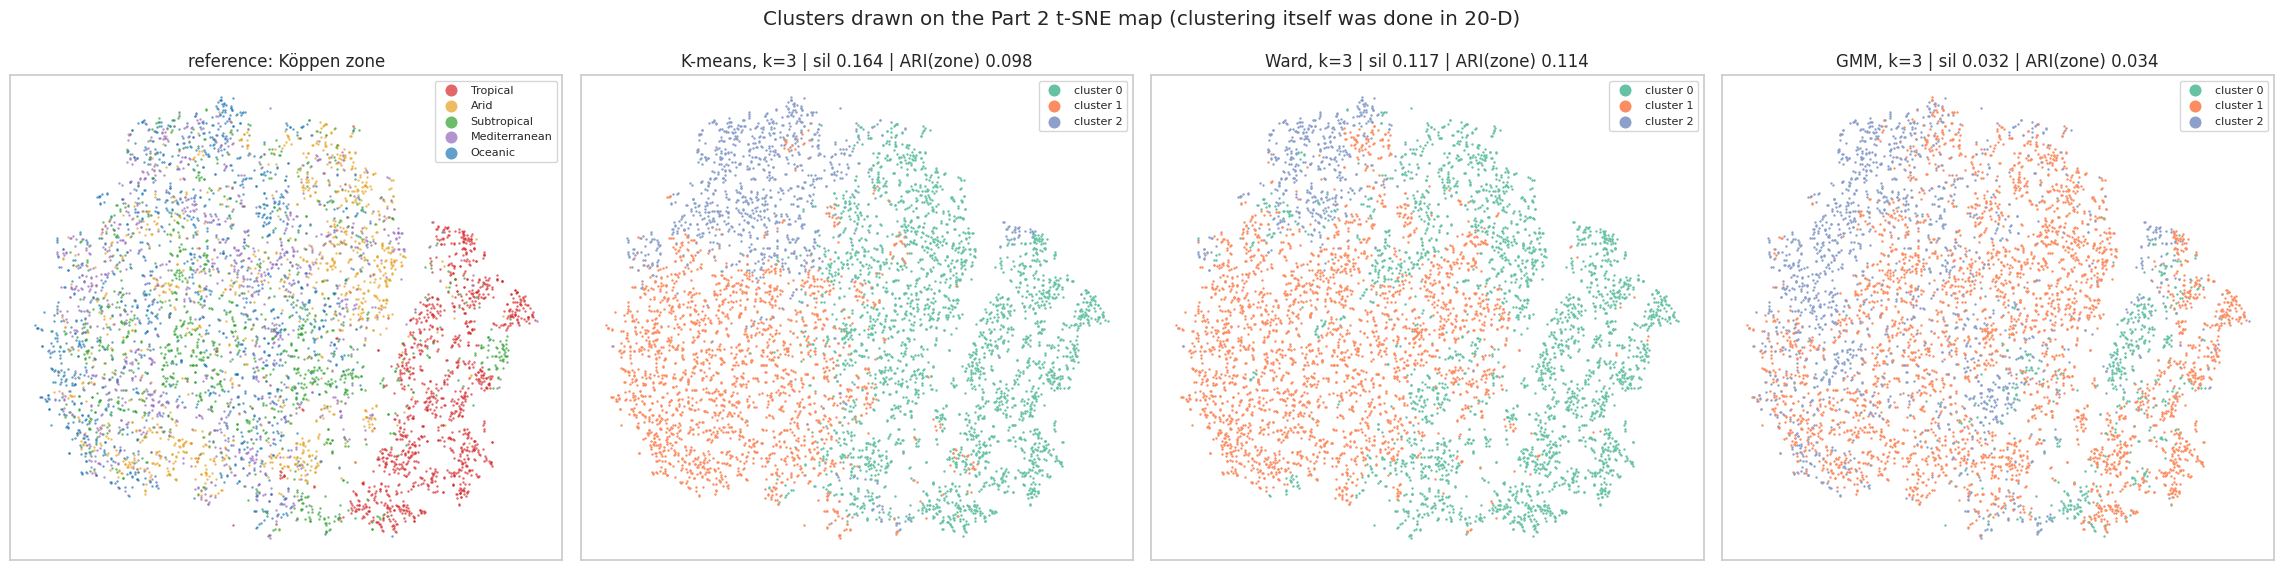

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(23, 5.8))
scatter_by_zone(axes[0], E2); axes[0].set_title("reference: Köppen zone"); axes[0].legend(markerscale=5, fontsize=8)
cl_cmap = plt.get_cmap("Set2")
for ax, alg in zip(axes[1:], ALGS):
    lab = labels_k[(alg, K_BEST)]
    for c in np.unique(lab):
        m = lab == c
        ax.scatter(E2[m, 0], E2[m, 1], s=3, color=cl_cmap(c), label=f"cluster {c}", linewidths=0)
    r = sweep[(sweep["algorithm"] == alg) & (sweep["k"] == K_BEST)].iloc[0]
    ax.set_title(f"{alg}, k={K_BEST} | sil {r['silhouette']:.3f} | ARI(zone) {r['ARI zone']:.3f}")
    ax.set_xticks([]); ax.set_yticks([]); ax.legend(markerscale=5, fontsize=8)
plt.suptitle("Clusters drawn on the Part 2 t-SNE map (clustering itself was done in 20-D)")
plt.tight_layout(); savefig("p3_clusters_on_tsne"); plt.show()

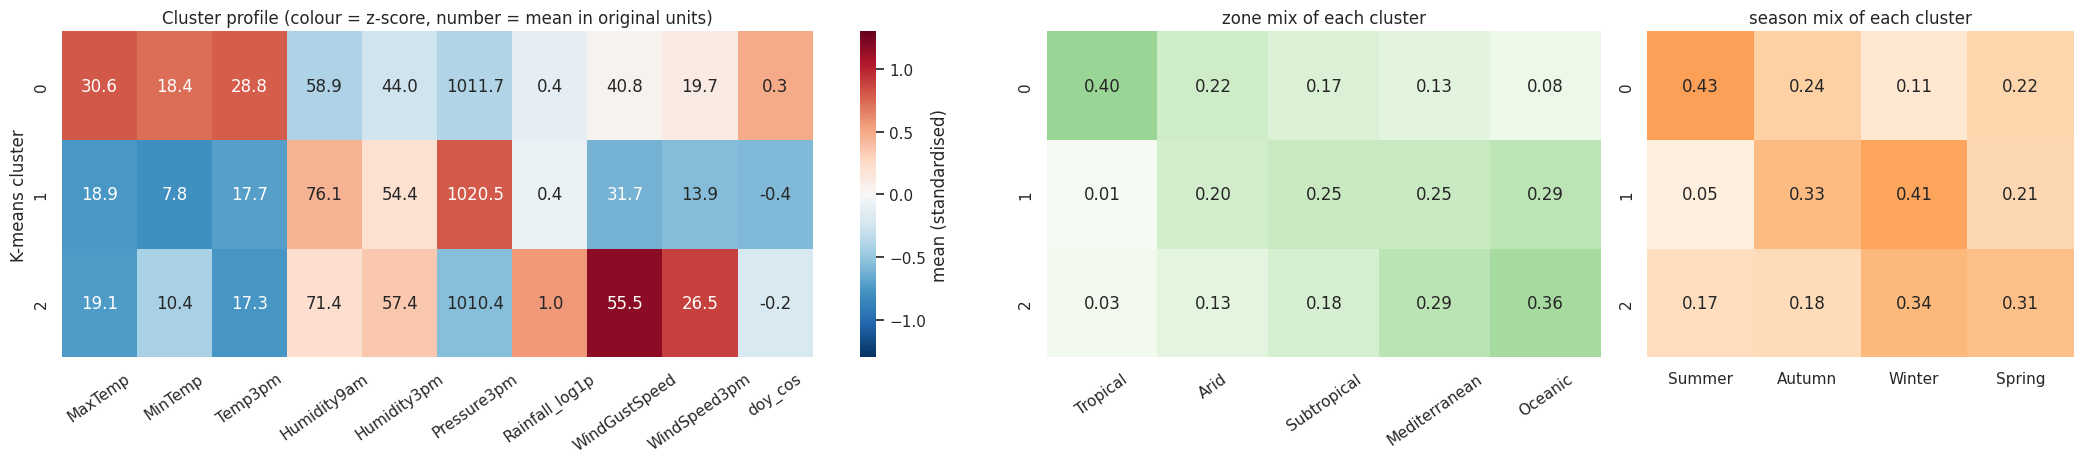

cluster sizes: [2891 2118  991]


In [35]:
km_lab = labels_k[("K-means", K_BEST)]
profile_cols = ["MaxTemp", "MinTemp", "Temp3pm", "Humidity9am", "Humidity3pm", "Pressure3pm",
                "Rainfall_log1p", "WindGustSpeed", "WindSpeed3pm", "doy_cos"]
raw_vis = F.loc[sample_idx]
fig, axes = plt.subplots(1, 3, figsize=(21, 4.8), gridspec_kw={"width_ratios": [2.2, 1.3, 1]})
z_means = pd.DataFrame(X_vis, columns=FEATURE_SETS["core"]).groupby(km_lab)[profile_cols].mean()
annot = raw_vis.groupby(km_lab)[profile_cols].mean().round(1)        # annotate with real units
sns.heatmap(z_means, annot=annot, fmt="", cmap="RdBu_r", center=0, vmin=-1.3, vmax=1.3, ax=axes[0],
            cbar_kws={"label": "mean (standardised)"})
axes[0].set(title="Cluster profile (colour = z-score, number = mean in original units)", ylabel="K-means cluster")
axes[0].tick_params(axis="x", rotation=35)
ct_zone = pd.crosstab(km_lab, y_vis, normalize="index")[ZONE_ORDER]
sns.heatmap(ct_zone, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, ax=axes[1], cbar=False)
axes[1].set(title="zone mix of each cluster", xlabel="", ylabel=""); axes[1].tick_params(axis="x", rotation=35)
ct_season = pd.crosstab(km_lab, season_vis, normalize="index")[["Summer", "Autumn", "Winter", "Spring"]]
sns.heatmap(ct_season, annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1, ax=axes[2], cbar=False)
axes[2].set(title="season mix of each cluster", xlabel="", ylabel="")
plt.tight_layout(); savefig("p3_cluster_profiles"); plt.show()
print("cluster sizes:", np.bincount(km_lab))

**Interpretation (K-means, k = 3).** The clusters are *weather regimes*, not climate zones:

* **Warm days** — high max/min temperature, slightly lower humidity, mostly summer and autumn. This cluster
  contains almost all Tropical days (and is about 40% Tropical), because tropical days are warm all year.
* **Cool, calm days** — the lowest temperatures, low wind and little rain, mostly winter and autumn: settled high-pressure weather.
* **Cool, windy, wet days** — much higher gusts and rainfall: the passage of fronts and storms, most common in the
  southern zones (Oceanic, Mediterranean).

Every non-tropical zone appears in all three clusters, because every zone has warm days, calm winter days and
stormy days. This is why ARI with `Zone` never exceeds 0.13 for any algorithm or k (ARI with the season is
at most about 0.1 as well): a **single day** of weather does not carry a clear climate signature.

### 3.5 Extra: clustering *stations* instead of days

Climate is the long-term statistics of weather. If we describe each of the 48 stations by its **average seasonal
cycle** — mean MaxTemp, MinTemp, Humidity3pm and Rainfall for each of the 12 months (48 numbers per station,
computed from all its days) — the climate signal should no longer be hidden by day-to-day weather.

Pressure is not used because 4 stations never record it. Each of the 48 columns is standardised. This analysis
uses `Location` only to *aggregate* days; the algorithms still never see the zone labels.

In [36]:
PROFILE_VARS = ["MaxTemp", "MinTemp", "Humidity3pm", "Rainfall"]
station_profile = (df.assign(month=df["Date"].dt.month, Location=groups)
                     .pivot_table(index="Location", columns="month", values=PROFILE_VARS, aggfunc="mean"))
assert station_profile.notna().all().all()
S = StandardScaler().fit_transform(station_profile.values)
station_zone_true = station_zone.loc[station_profile.index].values
print("station profile matrix:", S.shape)

st_rows = []
for k in range(3, 8):
    for alg in ["K-means", "Ward"]:
        lab = (KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(S) if alg == "K-means"
               else AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(S))
        st_rows.append({"algorithm": alg, "k": k, "silhouette": silhouette_score(S, lab),
                        "ARI zone": adjusted_rand_score(station_zone_true, lab),
                        "NMI zone": normalized_mutual_info_score(station_zone_true, lab)})
st_sweep = pd.DataFrame(st_rows)
st_sweep.pivot(index="k", columns="algorithm", values=["silhouette", "ARI zone", "NMI zone"]).round(3)

station profile matrix: (48, 48)


silhouette        ARI zone        NMI zone       
algorithm    K-means   Ward  K-means   Ward  K-means   Ward
k                                                          
3              0.290  0.293    0.351  0.282    0.551  0.442
4              0.317  0.321    0.404  0.331    0.638  0.536
5              0.333  0.319    0.284  0.345    0.541  0.540
6              0.287  0.294    0.370  0.412    0.569  0.603
7              0.301  0.299    0.462  0.420    0.633  0.625

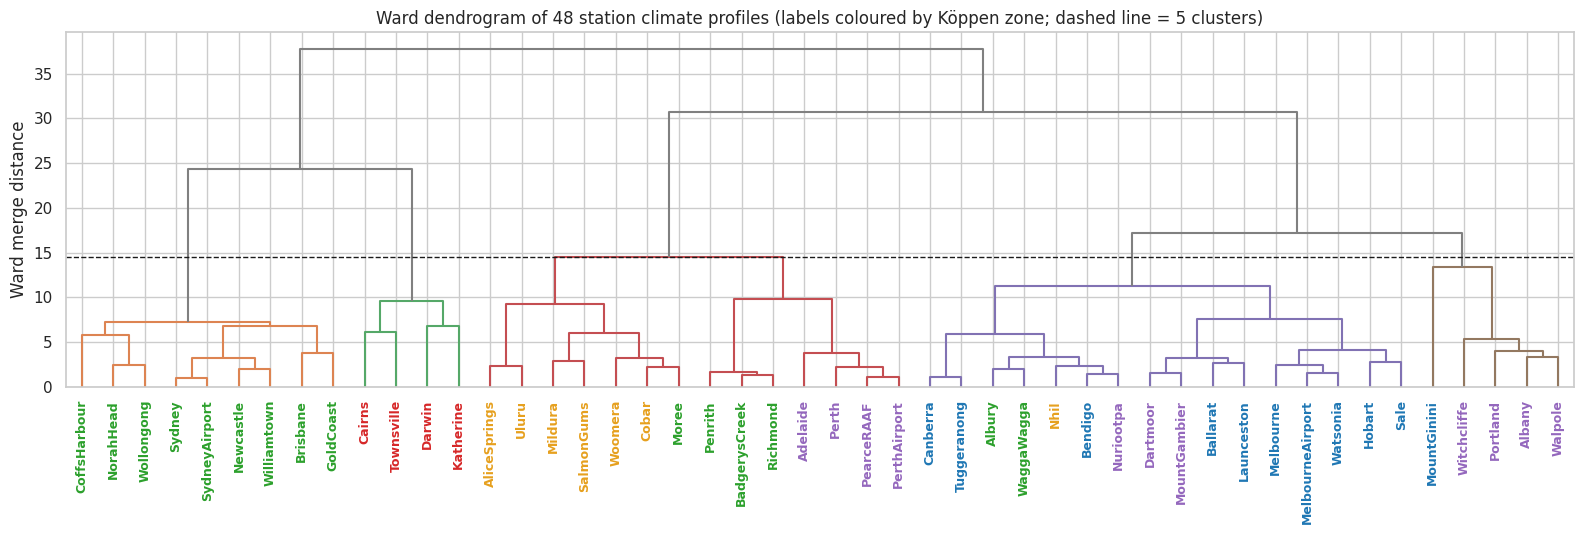

In [37]:
Z = linkage(S, method="ward")
st_lab = AgglomerativeClustering(n_clusters=5, linkage="ward").fit_predict(S)
fig, ax = plt.subplots(figsize=(16, 5.5))
dendrogram(Z, labels=station_profile.index.tolist(), leaf_rotation=90, leaf_font_size=9,
           color_threshold=Z[-5, 2] + 1e-9, above_threshold_color="grey", ax=ax)
for t in ax.get_xticklabels():                         # leaf labels coloured by the Köppen zone
    t.set_color(ZONE_COLORS[station_zone[t.get_text()]]); t.set_fontweight("bold")
ax.axhline(Z[-5, 2] + 1e-9, ls="--", color="k", lw=1)
ax.set(title="Ward dendrogram of 48 station climate profiles (labels coloured by Köppen zone; dashed line = 5 clusters)",
       ylabel="Ward merge distance")
plt.tight_layout(); savefig("p3_station_dendrogram"); plt.show()

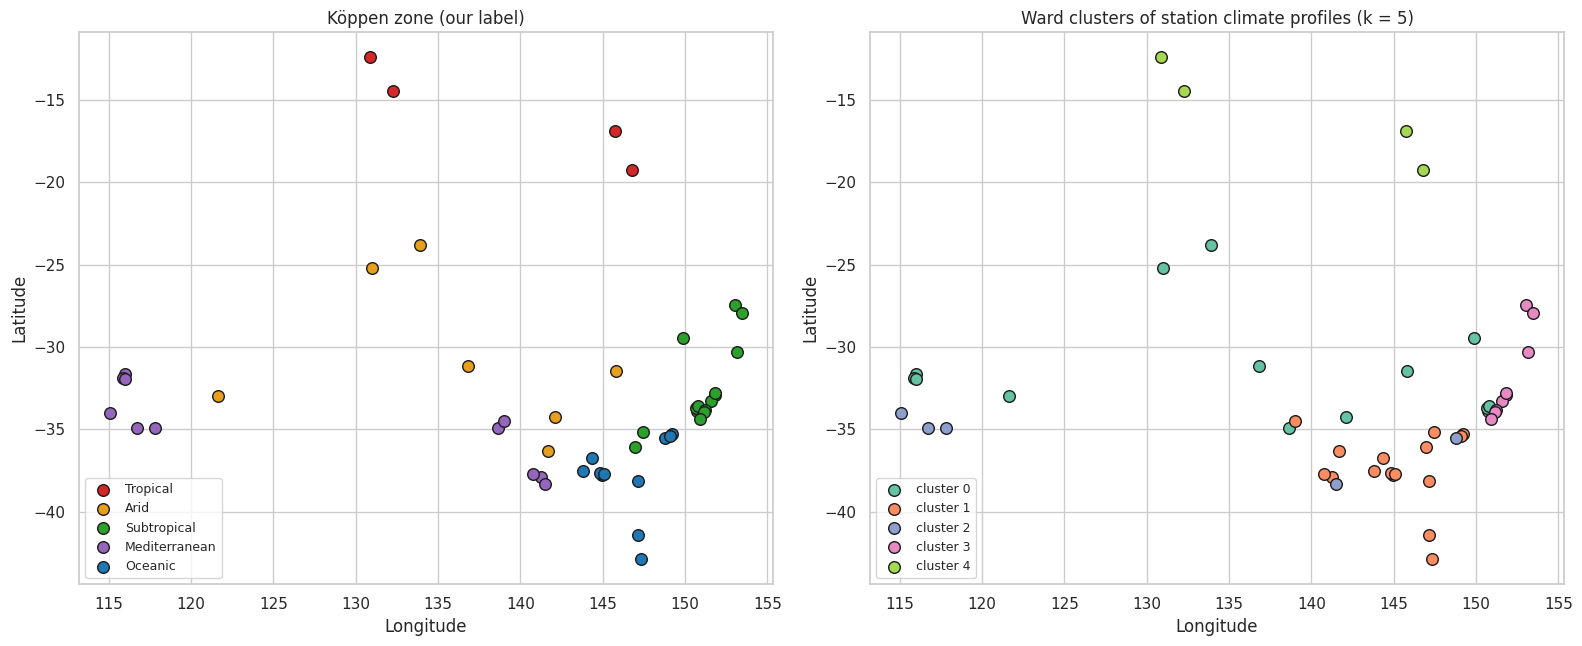

zone     Tropical  Arid  Subtropical  Mediterranean  Oceanic
cluster                                                     
0               0     6            4              4        0
1               0     1            2              3       10
2               0     0            0              4        1
3               0     0            9              0        0
4               4     0            0              0        0
cluster 0: Adelaide, AliceSprings, BadgerysCreek, Cobar, Mildura, Moree, PearceRAAF, Penrith, Perth, PerthAirport, Richmond, SalmonGums, Uluru, Woomera
cluster 1: Albury, Ballarat, Bendigo, Canberra, Dartmoor, Hobart, Launceston, Melbourne, MelbourneAirport, MountGambier, Nhil, Nuriootpa, Sale, Tuggeranong, WaggaWagga, Watsonia
cluster 2: Albany, MountGinini, Portland, Walpole, Witchcliffe
cluster 3: Brisbane, CoffsHarbour, GoldCoast, Newcastle, NorahHead, Sydney, SydneyAirport, Williamtown, Wollongong
cluster 4: Cairns, Darwin, Katherine, Townsville


In [38]:
loc_xy = zones.set_index("Location").loc[station_profile.index, ["lon", "lat"]]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for zone in ZONE_ORDER:
    m = station_zone_true == zone
    axes[0].scatter(loc_xy["lon"][m], loc_xy["lat"][m], s=70, color=ZONE_COLORS[zone], edgecolor="k", label=zone)
axes[0].set_title("Köppen zone (our label)")
for c in range(5):
    m = st_lab == c
    axes[1].scatter(loc_xy["lon"][m], loc_xy["lat"][m], s=70, color=cl_cmap(c), edgecolor="k", label=f"cluster {c}")
axes[1].set_title("Ward clusters of station climate profiles (k = 5)")
for ax in axes:
    ax.set(xlabel="Longitude", ylabel="Latitude"); ax.set_aspect("equal"); ax.legend(loc="lower left", fontsize=9)
plt.tight_layout(); savefig("p3_station_clusters_map"); plt.show()

print(pd.crosstab(pd.Series(st_lab, name="cluster"), pd.Series(station_zone_true, name="zone"))[ZONE_ORDER])
for c in range(5):
    print(f"cluster {c}: " + ", ".join(station_profile.index[st_lab == c]))

In [39]:
compare = pd.DataFrame({
    "unit clustered": ["one day (6,000 days)", "one day (6,000 days)", "station profile (48 stations)"],
    "algorithm": ["K-means k=3 (best by internal metrics)", "Ward k=5 (same k as zones)", "Ward k=5"],
    "ARI with Zone": [sweep.query("algorithm=='K-means' and k==3")["ARI zone"].item(),
                      sweep.query("algorithm=='Ward' and k==5")["ARI zone"].item(),
                      st_sweep.query("algorithm=='Ward' and k==5")["ARI zone"].item()],
    "NMI with Zone": [sweep.query("algorithm=='K-means' and k==3")["NMI zone"].item(),
                      sweep.query("algorithm=='Ward' and k==5")["NMI zone"].item(),
                      st_sweep.query("algorithm=='Ward' and k==5")["NMI zone"].item()],
}).round(3)
compare

,unit clustered,algorithm,ARI with Zone,NMI with Zone
0,"one day (6,000 days)",K-means k=3 (best by internal metrics),0.098,0.122
1,"one day (6,000 days)",Ward k=5 (same k as zones),0.126,0.180
2,station profile (48 stations),Ward k=5,0.345,0.540


**Interpretation of the station clusters (Ward, k = 5).**

* Two Köppen zones are recovered exactly: all 4 **Tropical** stations form one cluster, and a second cluster
  holds exactly the 9 **coastal Subtropical** stations from Brisbane to Wollongong.
* The other three clusters follow **distance from the sea** more than Köppen's rainfall-season rule: a hot, dry
  *inland* cluster (6 of the 7 Arid stations, plus the Perth area, Adelaide, Moree and western Sydney), a cool
  *south-east* cluster (10 of 11 Oceanic stations plus Albury, Wagga Wagga, Nhil and the Mediterranean stations of
  south-east South Australia / western Victoria), and a small cool, wet, windy
  *south-west coast* cluster (Albany, Walpole, Witchcliffe, Portland, and the alpine MountGinini).
* The Mediterranean zone is split across three clusters. Köppen defines it by a *ratio* (the driest summer month
  has less than a third of the wettest winter month's rain), which is a small part of our 48-number profile,
  whereas temperature and humidity differences between coast and inland dominate the Euclidean distance.
* ARI with the zones rises from about 0.1 for days to about 0.35 for stations (and to 0.42–0.46 for k = 7).

### 3.6 Summary of Part 3

1. **Algorithms**: K-means, Ward agglomerative and GMM (full covariance), each for k = 2–10, compared with three
   internal metrics, two external metrics, subsampling stability (all three algorithms), inertia and BIC.
2. **Best day-level result** (stability ≥ 0.90, best mean rank of silhouette / Davies–Bouldin / Calinski–Harabasz):
   K-means, k = 3 (lowest Davies–Bouldin of all solutions, near-best silhouette, stability 0.98). Its clusters are
   weather regimes (warm / cool-calm / cool-windy-wet), not climate zones.
3. **Algorithm comparison**: K-means ≥ Ward on all internal metrics, and Ward is unstable under subsampling
   (≤ 0.36); GMM with full covariance degenerates by placing a zero-variance component on the 63% of dry days, so
   BIC and silhouette disagree; a larger `reg_covar` reduces but does not remove the gap to K-means.
4. **Can clustering rediscover the zones?** From single days, no (ARI ≤ 0.13 for every algorithm and k). From
   station climate profiles, partly (ARI ≈ 0.35): the tropics and the subtropical coast are found exactly, and the
   rest of the map is organised by coast vs. inland. For Part 4 this means a classifier must combine many weak
   signals of a single day; we should expect Tropical to be easy and the southern zones to be confused.

## 4. Prediction: Training and Testing

**Question.** Given the labels, how well can simple models classify the climate zone of a single day?

### 4.1 Target, models and why we chose them

* **Target**: `Zone` (5 classes, Köppen-derived, Section 0.2). Classes are moderately imbalanced
  (Tropical 7.6% … Subtropical 32.2%), so besides accuracy we always report **macro-F1** (every zone counts equally).
* **Features**: the 20 `core` features from Part 1 (no station-specific sensors, no missing indicators).
* **Logistic Regression (multinomial)** — a linear model: one weight vector per zone, softmax over the five scores.
  It is the natural linear baseline, gives calibrated-looking probabilities (needed for ROC in Part 5), and its
  coefficients are interpretable. Default regularisation `C = 1`.
* **Decision Tree (CART, Gini)** — a non-linear model made of axis-aligned threshold rules such as
  "MinTemp > 18.5 °C". It can represent interactions that LR cannot (e.g. *hot and dry* vs *hot and humid*), and
  its rules are readable. We first train it with **default settings (no depth limit)** to see what an
  unconstrained model does; Part 5 tunes it.

Both models are sklearn Pipelines `median imputation → standardisation → model`, so the imputation medians and the
scaling statistics are learned from the training set only.

### 4.2 Two 70/30 splits, two questions

| Split | How | Question it answers |
|---|---|---|
| **Random** (required by the task) | stratified by `Zone`, 70% / 30% of the rows | Can the model classify *new days* of stations it has already seen? |
| **Station-grouped** | 70% / 30% of the **stations** (`GroupShuffleSplit`); no station appears on both sides | Can it classify days from *stations it has never seen*? |

Both splits were created in Section 1.6 and are reused here. The grouped test set contains 15 stations from all
5 zones.

In [40]:
X_all = F[FEATURE_SETS["core"]]
ALL = np.arange(len(df))
SPLITS = {"random": (rand_tr, rand_te), "grouped": (grp_tr, grp_te)}
print("grouped test stations:", ", ".join(sorted(groups.iloc[grp_te].unique())))
print(pd.DataFrame({s: pd.Series(y[b]).value_counts() for s, (a, b) in SPLITS.items()}).loc[ZONE_ORDER]
      .rename(columns=lambda c: f"{c} test rows"))

def make_model(name, **params):
    if name == "LR":
        est = LogisticRegression(max_iter=3000, **params)
    elif name == "DT":
        est = DecisionTreeClassifier(random_state=RANDOM_STATE, **params)
    else:
        raise ValueError(name)
    return make_pipeline(build_preprocessor(), est)

grouped test stations: AliceSprings, BadgerysCreek, Bendigo, Cairns, Dartmoor, MelbourneAirport, Newcastle, Nhil, NorahHead, Nuriootpa, Richmond, SydneyAirport, Tuggeranong, Uluru, Watsonia
               random test rows  grouped test rows
Tropical                   3255               3040
Arid                       5467               6196
Subtropical               13741              15070
Mediterranean             10058               6018
Oceanic                   10215              12097


### 4.3 Training

Training is a single `fit` on the training rows. For LR, `lbfgs` minimises the multinomial cross-entropy plus an
L2 penalty `‖w‖² / (2C)`. For the tree, CART greedily chooses at every node the feature and threshold that most
reduce Gini impurity, and keeps splitting until every leaf is pure (default settings).

In [41]:
import time
models_p4, fit_info = {}, []
for split, (a, b) in SPLITS.items():
    for name in ["LR", "DT"]:
        t0 = time.time()
        m = make_model(name).fit(X_all.iloc[a], y[a])
        info = {"split": split, "model": name, "fit time (s)": round(time.time() - t0, 1)}
        if name == "DT":
            info.update(depth=m[-1].get_depth(), leaves=m[-1].get_n_leaves())
        fit_info.append(info); models_p4[(split, name)] = m
pd.DataFrame(fit_info)

,split,model,fit time (s),depth,leaves
0,random,LR,2.6,NaN,NaN
1,random,DT,1.3,35.0,18947.0
2,grouped,LR,2.3,NaN,NaN
3,grouped,DT,1.3,36.0,17470.0


The unconstrained tree grows to a depth of about 35 with roughly 18,000 leaves for ~100,000 training days, i.e.
on average about 5–6 training days per leaf. This already suggests memorisation.

### 4.4 Evaluation on the training set, test set and entire set

In [42]:
from sklearn.metrics import confusion_matrix

def evaluate(model, idx):
    pred = model.predict(X_all.iloc[idx])
    return {"accuracy": accuracy_score(y[idx], pred),
            "macro-F1": f1_score(y[idx], pred, average="macro"),
            "weighted-F1": f1_score(y[idx], pred, average="weighted")}, pred

eval_rows, preds_p4 = [], {}
for (split, name), m in models_p4.items():
    a, b = SPLITS[split]
    for part, idx in [("train", a), ("test", b), ("entire", ALL)]:
        res, pred = evaluate(m, idx)
        preds_p4[(split, name, part)] = pred
        eval_rows.append({"split": split, "model": name, "set": part, **res})
p4_table = pd.DataFrame(eval_rows)
p4_table.pivot_table(index=["split", "model"], columns="set", values=["accuracy", "macro-F1"]).round(3)[
    [("accuracy", "train"), ("accuracy", "test"), ("accuracy", "entire"),
     ("macro-F1", "train"), ("macro-F1", "test"), ("macro-F1", "entire")]]

accuracy               macro-F1              
set              train   test entire    train   test entire
split   model                                              
grouped DT       1.000  0.533  0.861    1.000  0.536  0.865
        LR       0.609  0.563  0.596    0.625  0.561  0.609
random  DT       1.000  0.652  0.895    1.000  0.669  0.900
        LR       0.604  0.599  0.602    0.620  0.615  0.618

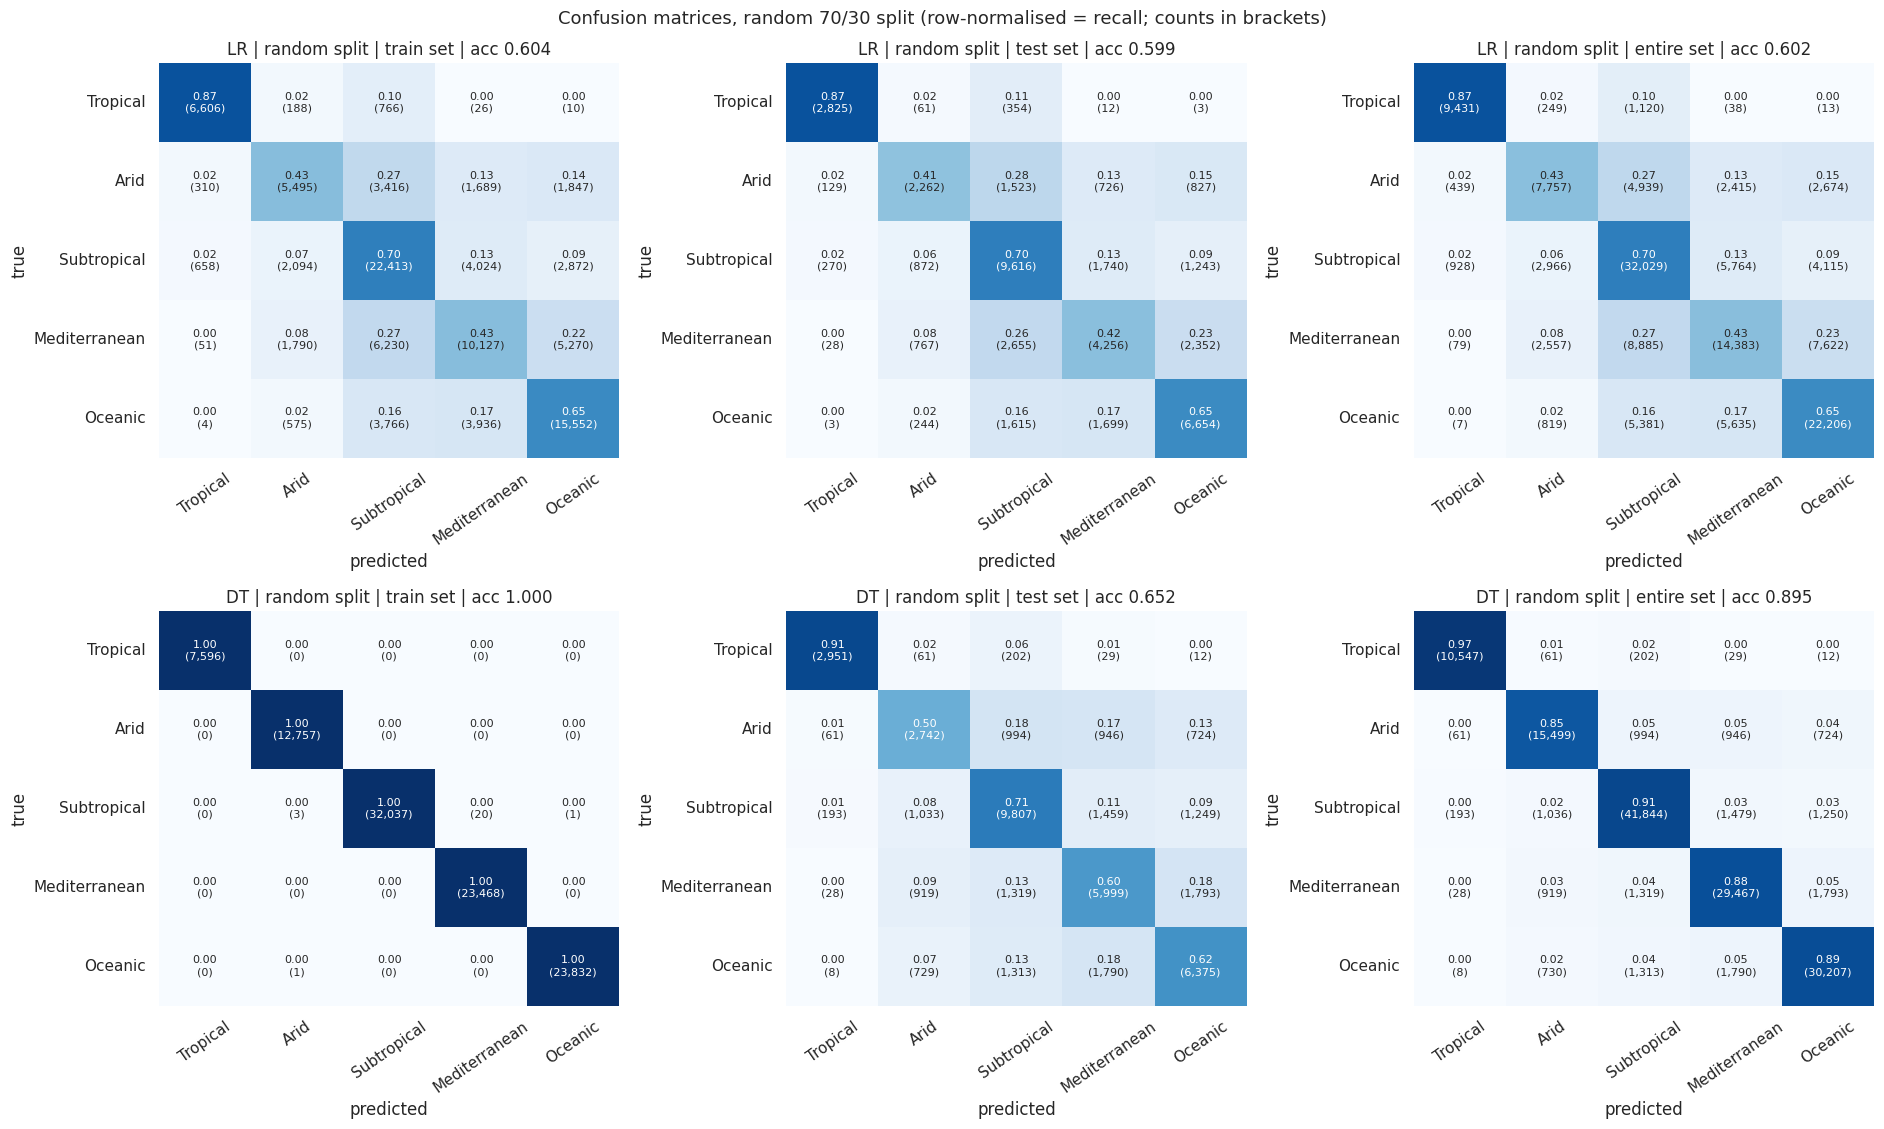

In [43]:
def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=ZONE_ORDER)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{p:.2f}\n({c:,})" for p, c in zip(rp, rc)] for rp, rc in zip(cm_norm, cm)])
    sns.heatmap(cm_norm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=ZONE_ORDER, yticklabels=ZONE_ORDER, annot_kws={"fontsize": 8})
    ax.set(title=title, xlabel="predicted", ylabel="true")
    ax.tick_params(axis="x", rotation=35); ax.tick_params(axis="y", rotation=0)
    return cm

fig, axes = plt.subplots(2, 3, figsize=(19, 11.5))
for i, name in enumerate(["LR", "DT"]):
    for j, part in enumerate(["train", "test", "entire"]):
        idx = {"train": rand_tr, "test": rand_te, "entire": ALL}[part]
        acc = accuracy_score(y[idx], preds_p4[("random", name, part)])
        plot_cm(axes[i, j], y[idx], preds_p4[("random", name, part)], f"{name} | random split | {part} set | acc {acc:.3f}")
plt.suptitle("Confusion matrices, random 70/30 split (row-normalised = recall; counts in brackets)", fontsize=13)
plt.tight_layout(); savefig("p4_confusion_random"); plt.show()

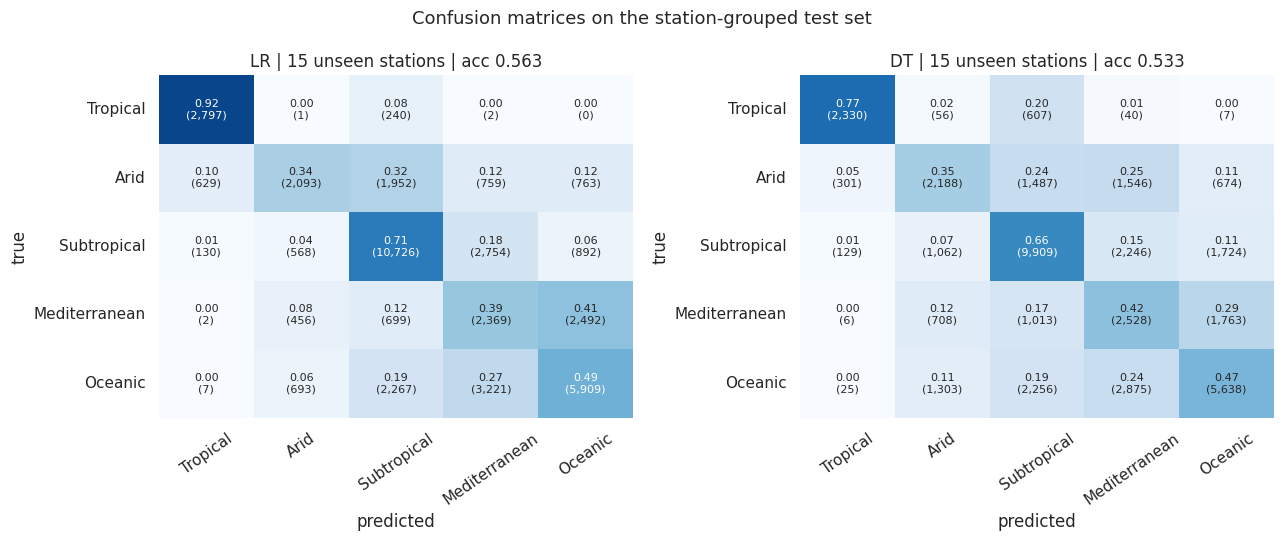

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, name in zip(axes, ["LR", "DT"]):
    acc = accuracy_score(y[grp_te], preds_p4[("grouped", name, "test")])
    plot_cm(ax, y[grp_te], preds_p4[("grouped", name, "test")], f"{name} | 15 unseen stations | acc {acc:.3f}")
plt.suptitle("Confusion matrices on the station-grouped test set", fontsize=13)
plt.tight_layout(); savefig("p4_confusion_grouped"); plt.show()

### 4.5 Visualising the decision boundary

The models live in 20 dimensions, so we draw the boundary of the same model classes trained on **two features
only**. We picked the pair with the best two-feature LR test macro-F1 among the interpretable candidates:
`MinTemp` (night temperature) and `Humidity3pm` (afternoon humidity). The decision tree is shown twice: with
default settings, and with `max_depth = 6` to show what limiting complexity does. Points are 1,500 random test days.

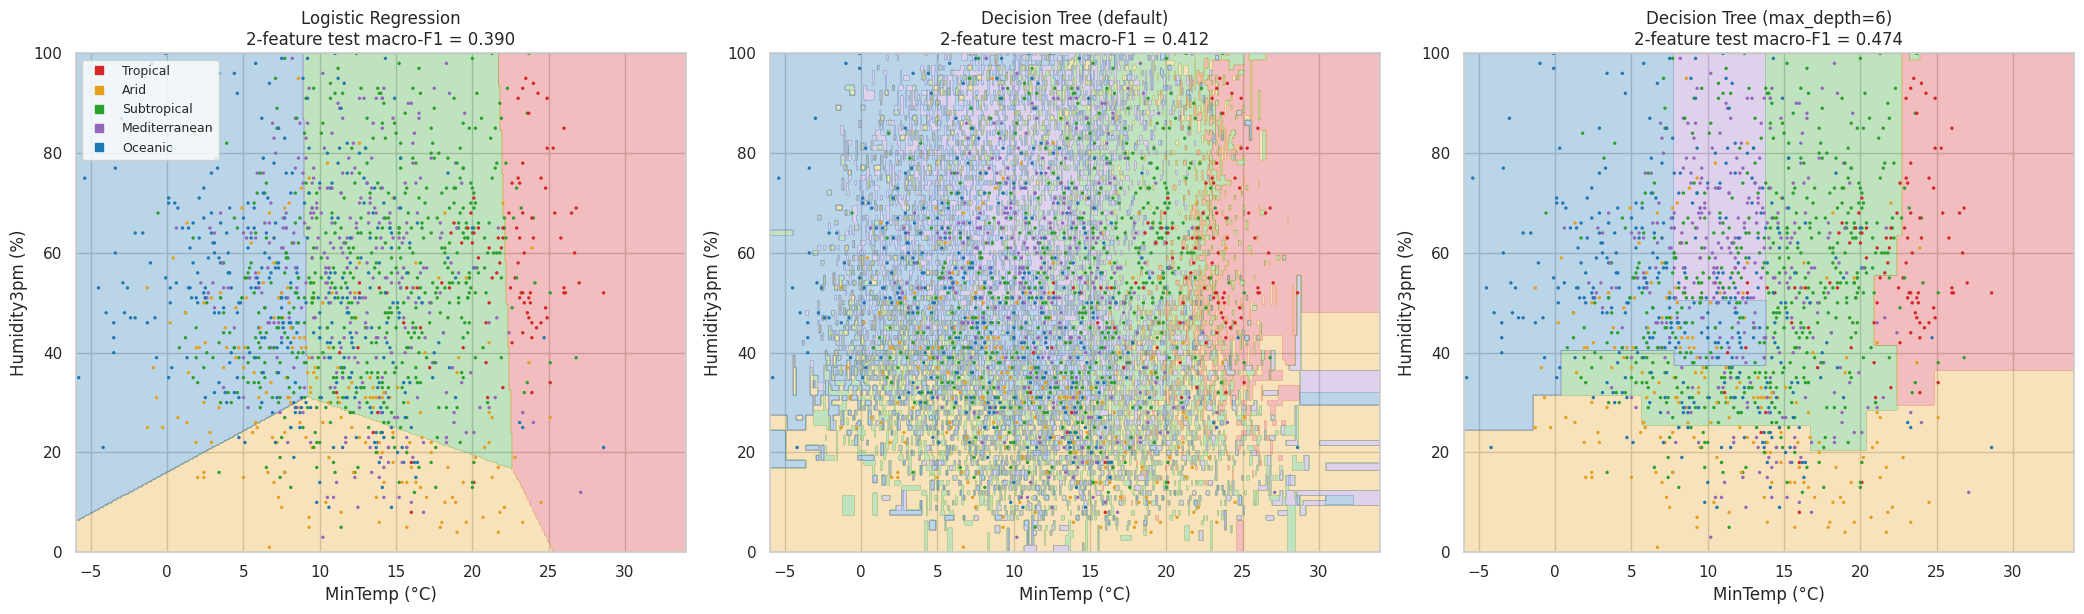

In [45]:
pair = ["MinTemp", "Humidity3pm"]
X2_tr, X2_te = F.iloc[rand_tr][pair], F.iloc[rand_te][pair]
boundary_models = {"Logistic Regression": make_model("LR"), "Decision Tree (default)": make_model("DT"),
                   "Decision Tree (max_depth=6)": make_model("DT", max_depth=6)}
xx, yy = np.meshgrid(np.linspace(-6, 34, 400), np.linspace(0, 100, 400))
grid = pd.DataFrame({pair[0]: xx.ravel(), pair[1]: yy.ravel()})
zone_idx = {z: i for i, z in enumerate(ZONE_ORDER)}
from matplotlib.colors import ListedColormap
cmap5 = ListedColormap([ZONE_COLORS[z] for z in ZONE_ORDER])
pts = np.random.default_rng(RANDOM_STATE).choice(len(rand_te), 1500, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(21, 6.3))
for ax, (title, m) in zip(axes, boundary_models.items()):
    m.fit(X2_tr, y[rand_tr])
    Z = np.vectorize(zone_idx.get)(m.predict(grid)).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(-0.5, 5.5), cmap=cmap5, alpha=0.30)
    ax.scatter(X2_te.iloc[pts][pair[0]], X2_te.iloc[pts][pair[1]], s=6, linewidths=0,
               c=[ZONE_COLORS[z] for z in y[rand_te][pts]])
    f1 = f1_score(y[rand_te], m.predict(X2_te), average="macro")
    ax.set(title=f"{title}\n2-feature test macro-F1 = {f1:.3f}", xlabel="MinTemp (°C)", ylabel="Humidity3pm (%)",
           xlim=(-6, 34), ylim=(0, 100))
handles = [plt.Line2D([], [], marker="s", ls="", color=ZONE_COLORS[z], label=z) for z in ZONE_ORDER]
axes[0].legend(handles=handles, loc="upper left", fontsize=9)
plt.tight_layout(); savefig("p4_decision_boundary"); plt.show()

* **LR** draws straight boundaries: warm nights (MinTemp > ~22 °C) → Tropical, low afternoon humidity → Arid,
  cold nights → Oceanic, and a wide middle band → Subtropical. **No region is assigned to Mediterranean at all**:
  with only these two features, Mediterranean days are never the most probable class anywhere.
* **The default tree** cuts the plane into thousands of tiny axis-aligned rectangles; many of them contain a single
  training day, which is overfitting made visible.
* **The depth-6 tree** keeps the large structures (the tropical corner, the dry strip) with at most 64 leaves,
  carves out a Mediterranean box (mild nights, humid afternoons) that LR cannot represent, and has the highest
  test score of the three (0.474 vs 0.412 for the default tree and 0.390 for LR).

### 4.6 Interpretation of the results on the training, test and entire sets

*All numbers refer to the tables above.*

**Logistic regression.** Training, test and entire-set scores are almost the same (accuracy ≈ 0.60 on the
random split). A linear model with 105 parameters cannot memorise 100,000 days: its errors come from **bias**
(the zones are not linearly separable), not from variance.

**Decision tree.** It is perfect on the training set (accuracy 1.000) but only ≈ 0.65 on the random test set:
a classic case of **overfitting**. Even so, its test score is higher than LR's, because the tree can model
non-linear interactions.

**The entire set is not an independent estimate.** It is 70% training rows and 30% test rows, so
`entire ≈ 0.7 · train + 0.3 · test`. For LR this changes nothing; for the tree it produces a misleading 0.895.
Only the test column measures generalisation.

**Unseen stations.** On the grouped split both models lose accuracy, but the tree loses far more (test accuracy
falls from 0.65 to 0.53) and drops *below* LR (0.56). Part of what the tree learned on the random split was
**station-specific** (it recognised the typical days of each station), and that knowledge does not transfer to new
stations. LR, which cannot memorise, is the more robust model here.

**Which zones are confused?** Tropical is recognised best in every test matrix (recall 0.77–0.92); its errors
go almost only to Subtropical (the warm, humid Queensland coast). The largest confusion is between Mediterranean
and Oceanic (up to 41% of Mediterranean test days on unseen stations are called Oceanic), as expected from the
t-SNE map (Part 2) and the clusters (Part 3). Arid has the lowest recall (0.34–0.50); its days are most often called
Subtropical, because the inland Subtropical stations (Moree, Wagga Wagga) have hot, dry summers too.

### 4.7 Comparison of the two models

| | Logistic Regression | Decision Tree (default) |
|---|---|---|
| Random test accuracy / macro-F1 | ≈ 0.60 / 0.62 | ≈ 0.65 / 0.67 |
| Unseen-station test accuracy / macro-F1 | ≈ 0.56 / 0.56 | ≈ 0.53 / 0.54 |
| Train − test gap | ≈ 0 (high bias, low variance) | ≈ 0.35 (low bias, high variance) |
| Boundary shape | linear | axis-aligned, very fragmented |

Neither model is good enough yet. Part 5 computes the full metrics, draws the ROC curves and improves both models
with validation.

## 5. Evaluation and Choice of Prediction Model

### 5.1 Metrics computed from the confusion matrix

For a multi-class confusion matrix `C` (rows = true zone, columns = predicted zone), each zone *k* is treated as
"zone *k* vs. the rest":

* `TP_k = C[k, k]`, `FP_k = Σ_i C[i, k] − TP_k` (column sum), `FN_k = Σ_j C[k, j] − TP_k` (row sum)
* precision_k = TP / (TP + FP), recall_k = TP / (TP + FN), F1_k = 2·P·R / (P + R)
* accuracy = trace(C) / ΣC
* **macro** average = plain mean over the 5 zones (each zone counts equally);
  **weighted** average = mean weighted by the number of true days of each zone.

We compute these by hand from the matrices of Part 4 and check them against `sklearn.metrics.classification_report`.

In [46]:
from sklearn.metrics import classification_report, precision_recall_fscore_support

def metrics_from_cm(cm):
    tp = np.diag(cm).astype(float)
    precision = tp / cm.sum(axis=0)
    recall = tp / cm.sum(axis=1)
    f1 = 2 * precision * recall / (precision + recall)
    support = cm.sum(axis=1)
    per_class = pd.DataFrame({"precision": precision, "recall": recall, "F1": f1, "support": support}, index=ZONE_ORDER)
    w = support / support.sum()
    summary = {"accuracy": tp.sum() / cm.sum(),
               "macro-P": precision.mean(), "macro-R": recall.mean(), "macro-F1": f1.mean(),
               "weighted-P": (precision * w).sum(), "weighted-R": (recall * w).sum(), "weighted-F1": (f1 * w).sum()}
    return per_class, summary

per_class_tables, summaries = {}, {}
for split in ["random", "grouped"]:
    b = SPLITS[split][1]
    for name in ["LR", "DT"]:
        cm = confusion_matrix(y[b], preds_p4[(split, name, "test")], labels=ZONE_ORDER)
        pc, sm = metrics_from_cm(cm)
        # sanity check against sklearn
        p, r, f, _ = precision_recall_fscore_support(y[b], preds_p4[(split, name, "test")], labels=ZONE_ORDER)
        assert np.allclose(pc[["precision", "recall", "F1"]].values, np.c_[p, r, f])
        per_class_tables[(split, name)] = pc; summaries[(split, name)] = sm

pd.concat({f"{n} ({s} test)": per_class_tables[(s, n)][["precision", "recall", "F1"]]
           for s in ["random", "grouped"] for n in ["LR", "DT"]}, axis=1).round(3)

LR (random test)               DT (random test)                \
                     precision recall     F1        precision recall     F1   
Tropical                 0.868  0.868  0.868            0.911  0.907  0.909   
Arid                     0.538  0.414  0.468            0.500  0.502  0.501   
Subtropical              0.610  0.700  0.652            0.719  0.714  0.716   
Mediterranean            0.505  0.423  0.460            0.587  0.596  0.592   
Oceanic                  0.601  0.651  0.625            0.628  0.624  0.626   

              LR (grouped test)               DT (grouped test)                
                      precision recall     F1         precision recall     F1  
Tropical                  0.785  0.920  0.847             0.835  0.766  0.799  
Arid                      0.549  0.338  0.418             0.412  0.353  0.380  
Subtropical               0.675  0.712  0.693             0.649  0.658  0.653  
Mediterranean             0.260  0.394  0.313             0.274  0.420  0.331  
Oceanic                   0.588  0.488  0.533             0.575  0.466  0.515

In [47]:
pd.DataFrame(summaries).T.round(3).rename_axis(["split", "model"])

accuracy  macro-P  macro-R  macro-F1  weighted-P  weighted-R  \
split   model                                                                 
random  LR        0.599    0.624    0.611     0.615       0.593       0.599   
        DT        0.652    0.669    0.668     0.669       0.653       0.652   
grouped LR        0.563    0.571    0.570     0.561       0.581       0.563   
        DT        0.533    0.549    0.533     0.536       0.553       0.533   

               weighted-F1  
split   model               
random  LR           0.593  
        DT           0.652  
grouped LR           0.565  
        DT           0.539

**Reading the per-zone metrics.** Tropical has the highest precision and recall for both models and both splits.
Arid and Mediterranean have the lowest F1 (0.31–0.59), Mediterranean particularly on unseen stations. On the random
split macro-F1 is slightly *higher* than weighted-F1, because the smallest class (Tropical, 7.6%) is the easiest
one and counts as much as the large classes in the macro average. Precision and recall of a zone can differ a lot
(LR, Arid: precision 0.54, recall 0.41): the model rarely predicts Arid, and is often right when it does.

### 5.2 ROC curves and AUC (one-vs-rest)

With 5 classes there is no single ROC curve. For each zone *k* we use the predicted probability `P(zone = k)` as a
score for the binary problem "zone *k* vs. rest" and draw one ROC curve; **macro-AUC** is the mean of the 5 AUCs.

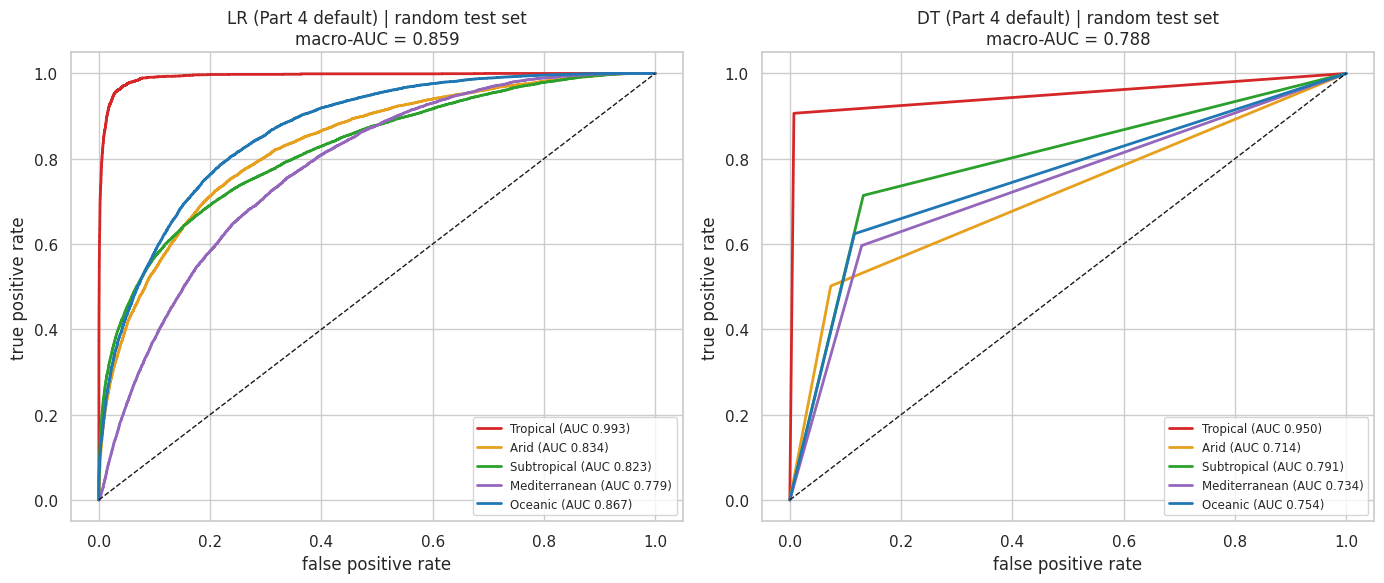

In [48]:
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.preprocessing import label_binarize

def per_class_auc(model, idx):
    proba = model.predict_proba(X_all.iloc[idx])
    classes = list(model.classes_)
    Y = label_binarize(y[idx], classes=classes)
    aucs = {z: roc_auc_score(Y[:, classes.index(z)], proba[:, classes.index(z)]) for z in ZONE_ORDER}
    aucs["macro"] = np.mean([aucs[z] for z in ZONE_ORDER])
    aucs["weighted"] = roc_auc_score(y[idx], proba, multi_class="ovr", average="weighted", labels=classes)
    return aucs, proba, classes

def plot_roc(ax, model, idx, title):
    aucs, proba, classes = per_class_auc(model, idx)
    Y = label_binarize(y[idx], classes=classes)
    for z in ZONE_ORDER:
        fpr, tpr, _ = roc_curve(Y[:, classes.index(z)], proba[:, classes.index(z)])
        ax.plot(fpr, tpr, color=ZONE_COLORS[z], lw=2, label=f"{z} (AUC {aucs[z]:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set(title=f"{title}\nmacro-AUC = {aucs['macro']:.3f}", xlabel="false positive rate", ylabel="true positive rate")
    ax.legend(loc="lower right", fontsize=8.5)
    return aucs

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
auc_p4 = {name: plot_roc(ax, models_p4[("random", name)], rand_te, f"{name} (Part 4 default) | random test set")
          for ax, name in zip(axes, ["LR", "DT"])}
plt.tight_layout(); savefig("p5_roc_default"); plt.show()

The default tree has pure leaves, so its "probabilities" are almost always 0 or 1. Each ROC curve therefore
collapses to a single corner point joined to (0, 0) and (1, 1), and its AUC is much lower than LR's even though
its accuracy is higher. **AUC rewards a good ranking of probabilities, which an overfitted tree cannot provide.**

### 5.3 Improving each model via validation

We tune both models with `GridSearchCV` (5-fold, scoring = macro-F1, the training scores are also recorded):

* **LR**: `C ∈ {0.001, 0.01, 0.1, 1, 10, 100}` (inverse L2 strength) × `class_weight ∈ {None, balanced}`
* **DT**: `max_depth ∈ {2, 4, 6, 8, 10, 13, 16, 20, 25, None}` × `min_samples_leaf ∈ {1, 20, 100, 400}`

The validation folds must imitate the test situation, so we run every search twice:

| Setting | Training data | CV folds |
|---|---|---|
| random | random training set | `StratifiedKFold` — validation days come from the same stations |
| unseen stations | grouped training set (33 stations) | `StratifiedGroupKFold` by station — validation stations are never in the training folds |

The four searches take ~1 min each; results are cached (Section 0). Note that `GridSearchCV` scores each fold with
sklearn's default macro-F1; under grouped CV this is biased downwards (explained in Section 5.6), which affects all
candidates alike, so it is fine for *ranking* configurations but its level should not be compared with test scores.

In [49]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

PARAM_GRIDS = {
    "LR": {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100],
           "logisticregression__class_weight": [None, "balanced"]},
    "DT": {"decisiontreeclassifier__max_depth": [2, 4, 6, 8, 10, 13, 16, 20, 25, None],
           "decisiontreeclassifier__min_samples_leaf": [1, 20, 100, 400]},
}
CV_SCHEMES = {"random": StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
              "grouped": StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)}

def run_search(name, split):
    a = SPLITS[split][0]
    gs = GridSearchCV(make_model(name), PARAM_GRIDS[name], cv=CV_SCHEMES[split],
                      scoring={"macro-F1": "f1_macro", "accuracy": "accuracy"}, refit="macro-F1",
                      return_train_score=True, n_jobs=2)
    fit_kw = {"groups": groups.iloc[a].values} if split == "grouped" else {}
    gs.fit(X_all.iloc[a], y[a], **fit_kw)
    return gs

searches = {(name, split): cached(f"p5_grid_{name}_{split}", lambda n=name, s=split: run_search(n, s),
                                  grid=repr(PARAM_GRIDS[name]), cv=repr(CV_SCHEMES[split]), seed=RANDOM_STATE)
            for name in ["LR", "DT"] for split in ["random", "grouped"]}
pd.DataFrame([{"model": n, "CV setting": s,
               "best parameters": {k.split("__")[1]: v for k, v in gs.best_params_.items()},
               "best CV macro-F1": gs.best_score_,
               "train macro-F1 at best": gs.cv_results_["mean_train_macro-F1"][gs.best_index_]}
              for (n, s), gs in searches.items()]).round(3)

,model,CV setting,best parameters,best CV macro-F1,train macro-F1 at best
0,LR,random,"{'C': 100, 'class_weight': None}",0.620,0.620
1,LR,grouped,"{'C': 0.01, 'class_weight': 'balanced'}",0.466,0.621
2,DT,random,"{'max_depth': 16, 'min_samples_leaf': 20}",0.682,0.755
3,DT,grouped,"{'max_depth': 16, 'min_samples_leaf': 20}",0.426,0.780


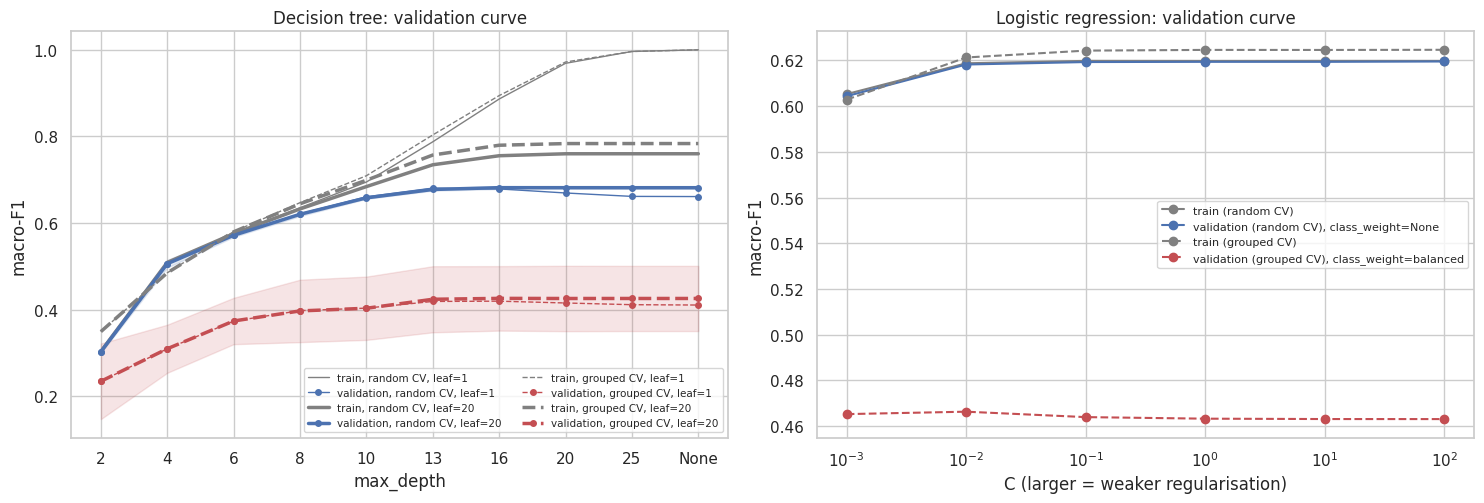

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
# Decision tree: validation curve over max_depth for min_samples_leaf = 1 (thin) and the selected value (thick)
depths = PARAM_GRIDS["DT"]["decisiontreeclassifier__max_depth"]
xpos = np.arange(len(depths))
for split, ls in [("random", "-"), ("grouped", "--")]:
    gs = searches[("DT", split)]; res = pd.DataFrame(gs.cv_results_)
    col = "C3" if split == "grouped" else "C0"
    best_leaf = gs.best_params_["decisiontreeclassifier__min_samples_leaf"]
    for leaf, lw in [(1, 1.0), (best_leaf, 2.5)]:
        r = res[res["param_decisiontreeclassifier__min_samples_leaf"] == leaf]
        axes[0].plot(xpos, r["mean_train_macro-F1"], ls, color="grey", lw=lw,
                     label=f"train, {split} CV, leaf={leaf}")
        axes[0].plot(xpos, r["mean_test_macro-F1"], ls, marker="o", ms=4, color=col, lw=lw,
                     label=f"validation, {split} CV, leaf={leaf}")
        if leaf == best_leaf:
            axes[0].fill_between(xpos, r["mean_test_macro-F1"] - r["std_test_macro-F1"],
                                 r["mean_test_macro-F1"] + r["std_test_macro-F1"], color=col, alpha=0.15)
axes[0].set_xticks(xpos); axes[0].set_xticklabels([str(d) for d in depths])
axes[0].set(title="Decision tree: validation curve", xlabel="max_depth", ylabel="macro-F1"); axes[0].legend(fontsize=7.5, ncol=2)
# Logistic regression: validation curve over C (at the best class_weight)
Cs = PARAM_GRIDS["LR"]["logisticregression__C"]
for split, ls in [("random", "-"), ("grouped", "--")]:
    gs = searches[("LR", split)]; res = pd.DataFrame(gs.cv_results_)
    cw = gs.best_params_["logisticregression__class_weight"]
    r = res[res["param_logisticregression__class_weight"].astype(str) == str(cw)]
    axes[1].semilogx(Cs, r["mean_train_macro-F1"], ls, marker="o", color="grey", label=f"train ({split} CV)")
    axes[1].semilogx(Cs, r["mean_test_macro-F1"], ls, marker="o", color="C3" if split == "grouped" else "C0",
                     label=f"validation ({split} CV), class_weight={cw}")
axes[1].set(title="Logistic regression: validation curve", xlabel="C (larger = weaker regularisation)", ylabel="macro-F1")
axes[1].legend(fontsize=8)
plt.tight_layout(); savefig("p5_validation_curves"); plt.show()

**Interpretation of the validation results.**

* **Decision tree.** With `min_samples_leaf = 1` (thin lines) training macro-F1 climbs to 1.0 while validation
  macro-F1 peaks around depth 13–16 and then declines: left of the peak the tree **underfits**, right of it it
  **overfits**. The selected `min_samples_leaf = 20` (thick lines) is a second regulariser: it stops the tree from
  isolating single days, so the validation curve stays at its peak instead of declining. Both CV schemes select the
  same tree (`max_depth = 16`, `min_samples_leaf = 20`). What differs is the *level*: on unseen stations the
  validation score is about 0.26 lower and varies much more between folds (shaded band), because each fold holds
  out only a few stations per zone.
* **Logistic regression.** Under random CV the train and validation curves coincide and are flat for `C ≥ 0.01`:
  105 parameters cannot overfit 100,000 days, and the limitation is bias (linear boundaries). Under grouped CV even
  LR has a train–validation gap of about 0.16. This is not overfitting to individual days but **distribution
  shift**: new stations differ systematically from the training stations. Strong regularisation (`C = 0.01`) and
  `class_weight = balanced` are selected, but they change the score by less than 0.01.
* **The random-split CV score is an optimistic estimate for new stations.** The gap between the two validation
  curves measures how much of the score comes from recognising stations that were seen during training.

### 5.4 Tuned vs. default models on the held-out test sets

In [51]:
final_rows, tuned = [], {}
for split in ["random", "grouped"]:
    a, b = SPLITS[split]
    for name in ["LR", "DT"]:
        for version, m in [("default (Part 4)", models_p4[(split, name)]), ("tuned (5.3)", searches[(name, split)].best_estimator_)]:
            if version.startswith("tuned"):
                tuned[(split, name)] = m
            tr = evaluate(m, a)[0]; te = evaluate(m, b)[0]
            aucs = per_class_auc(m, b)[0]
            final_rows.append({"split": split, "model": name, "version": version,
                               "train macro-F1": tr["macro-F1"], "test macro-F1": te["macro-F1"],
                               "gap": tr["macro-F1"] - te["macro-F1"], "test accuracy": te["accuracy"],
                               "test weighted-F1": te["weighted-F1"], "test macro-AUC": aucs["macro"]})
p5_table = pd.DataFrame(final_rows).set_index(["split", "model", "version"])
p5_table.round(3)

train macro-F1  test macro-F1    gap  \
split   model version                                                  
random  LR    default (Part 4)           0.620          0.615  0.005   
              tuned (5.3)                0.620          0.615  0.005   
        DT    default (Part 4)           1.000          0.669  0.331   
              tuned (5.3)                0.758          0.691  0.067   
grouped LR    default (Part 4)           0.625          0.561  0.064   
              tuned (5.3)                0.615          0.554  0.062   
        DT    default (Part 4)           1.000          0.536  0.464   
              tuned (5.3)                0.778          0.559  0.219   

                                test accuracy  test weighted-F1  \
split   model version                                             
random  LR    default (Part 4)          0.599             0.593   
              tuned (5.3)               0.599             0.593   
        DT    default (Part 4)          0.652             0.652   
              tuned (5.3)               0.678             0.677   
grouped LR    default (Part 4)          0.563             0.565   
              tuned (5.3)               0.553             0.561   
        DT    default (Part 4)          0.533             0.539   
              tuned (5.3)               0.559             0.564   

                                test macro-AUC  
split   model version                           
random  LR    default (Part 4)           0.859  
              tuned (5.3)                0.859  
        DT    default (Part 4)           0.788  
              tuned (5.3)                0.889  
grouped LR    default (Part 4)           0.823  
              tuned (5.3)                0.821  
        DT    default (Part 4)           0.705  
              tuned (5.3)                0.813

**Effect of validation.**

* **Decision tree**: tuning cuts the train–test gap on the random split from 0.33 to 0.07 and raises test
  macro-F1 (0.669 → 0.691) and especially macro-AUC (0.788 → 0.889), because leaves with ≥ 20 days give graded
  probabilities. On unseen stations the gain is smaller (macro-F1 0.536 → 0.559) and a gap of about 0.22 remains.
* **Logistic regression**: tuning changes nothing on the random split and slightly lowers the score on the 15
  unseen test stations (0.561 → 0.554), even though it was the best choice in cross-validation on the 33 training
  stations. With so few stations per zone, a difference of 0.01 is within the station-to-station noise.
* After tuning the tree is clearly better than LR on known stations, but **on unseen stations the two models are
  practically equal** (macro-F1 ≈ 0.55–0.56, macro-AUC ≈ 0.81–0.82).

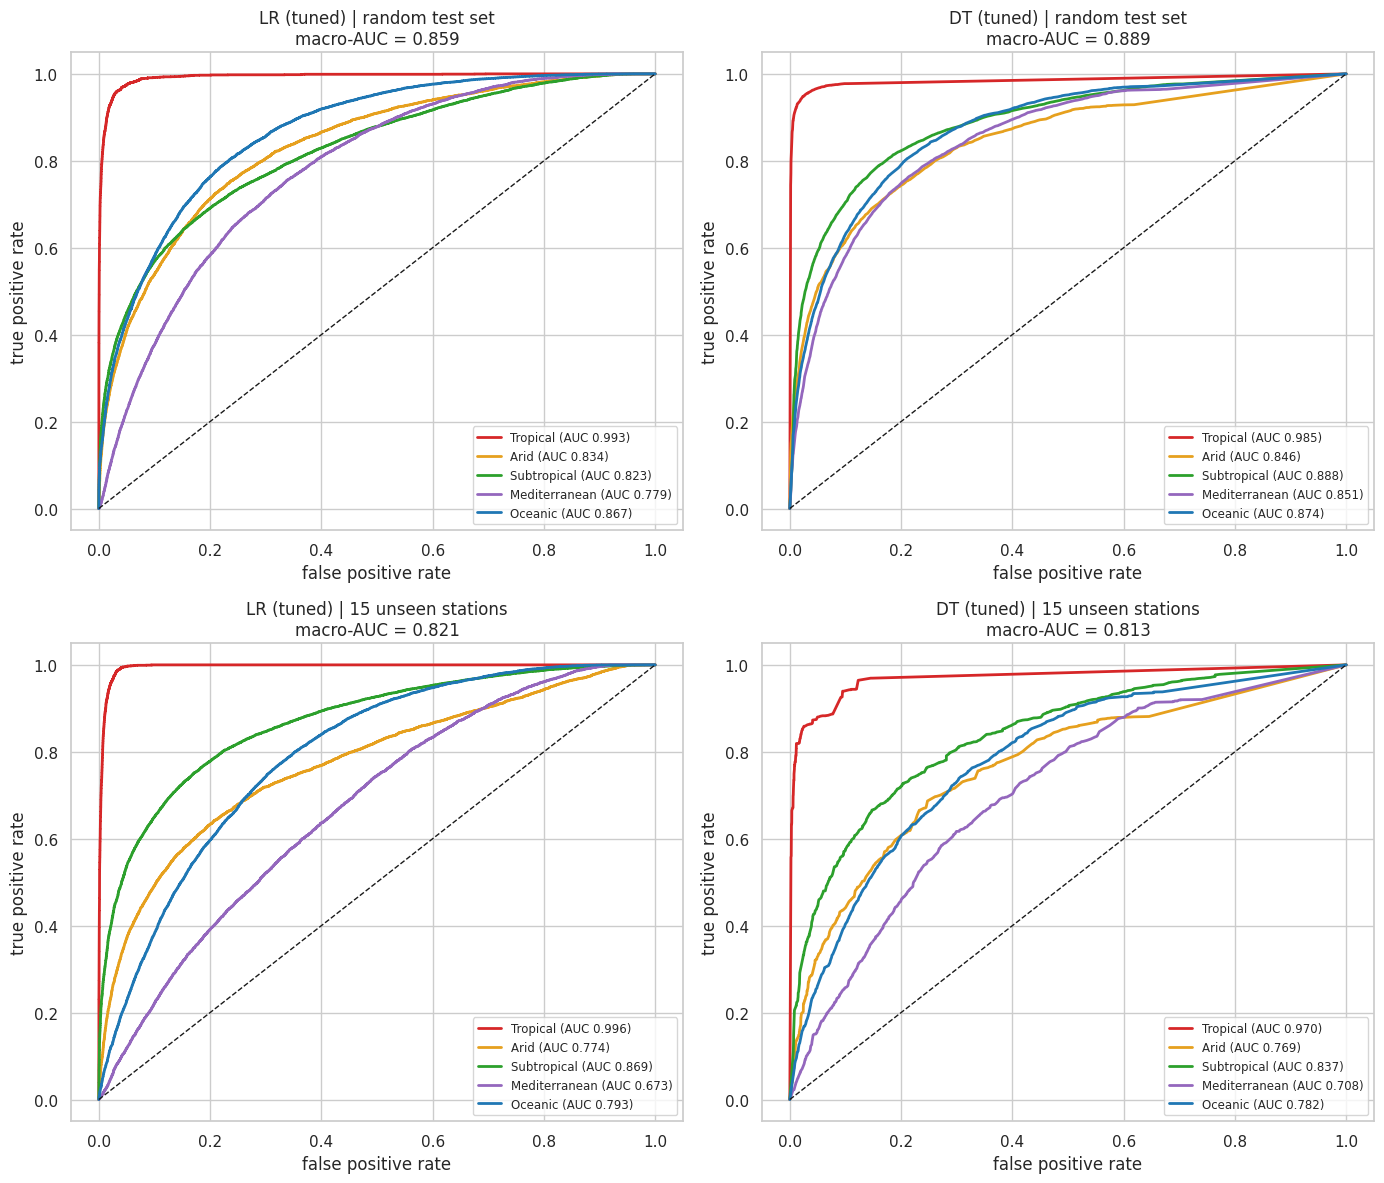

,LR | random,DT | random,LR | grouped,DT | grouped
Tropical,0.993,0.985,0.996,0.970
Arid,0.834,0.846,0.774,0.769
Subtropical,0.823,0.888,0.869,0.837
Mediterranean,0.779,0.851,0.673,0.708
Oceanic,0.867,0.874,0.793,0.782
macro,0.859,0.889,0.821,0.813
weighted,0.838,0.878,0.815,0.803


In [52]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
auc_tuned = {}
for i, split in enumerate(["random", "grouped"]):
    for j, name in enumerate(["LR", "DT"]):
        what = "random test set" if split == "random" else "15 unseen stations"
        auc_tuned[(split, name)] = plot_roc(axes[i, j], tuned[(split, name)], SPLITS[split][1], f"{name} (tuned) | {what}")
plt.tight_layout(); savefig("p5_roc_tuned"); plt.show()
pd.DataFrame({f"{n} | {s}": auc_tuned[(s, n)] for s in ["random", "grouped"] for n in ["LR", "DT"]}).round(3)

### 5.5 Error analysis: which stations are hard?

A single grouped split tests only 15 stations. To see every station as "unseen" once, we make **out-of-fold
predictions** with `StratifiedGroupKFold(5)` over all 48 stations: each day is predicted by a tuned model (grouped
CV parameters) that was trained without its station.

In [53]:
def oof_predictions(name):
    params = searches[(name, "grouped")].best_params_
    model = make_model(name).set_params(**params)
    return cross_val_predict(model, X_all, y, groups=groups.values, cv=CV_SCHEMES["grouped"], n_jobs=2)

oof = {name: cached(f"p5_oof_{name}", lambda n=name: oof_predictions(n),
                    params=repr(searches[(name, "grouped")].best_params_), cv=repr(CV_SCHEMES["grouped"]))
       for name in ["LR", "DT"]}
station_acc = pd.DataFrame({name: pd.Series(oof[name] == y).groupby(groups.values).mean() for name in oof})
station_acc["Zone"] = station_zone.loc[station_acc.index]
station_acc["koppen"] = zones.set_index("Location").loc[station_acc.index, "koppen"]
for name in oof:
    print(f"{name}: out-of-fold accuracy over all 48 unseen stations = {accuracy_score(y, oof[name]):.3f}, "
          f"macro-F1 = {f1_score(y, oof[name], average='macro'):.3f}")
station_acc.sort_values("LR").round(3).head(10)

LR: out-of-fold accuracy over all 48 unseen stations = 0.532, macro-F1 = 0.553


DT: out-of-fold accuracy over all 48 unseen stations = 0.550, macro-F1 = 0.557


,LR,DT,Zone,koppen
WaggaWagga,0.063,0.191,Subtropical,Cfa
Moree,0.075,0.247,Subtropical,Cfa
Albury,0.170,0.245,Subtropical,Cfa
SalmonGums,0.250,0.076,Arid,BSk
Portland,0.279,0.457,Mediterranean,Csb
Nuriootpa,0.287,0.274,Mediterranean,Csb
Dartmoor,0.299,0.330,Mediterranean,Csb
Nhil,0.304,0.167,Arid,BSk
MountGambier,0.317,0.430,Mediterranean,Csb
PearceRAAF,0.365,0.605,Mediterranean,Csa


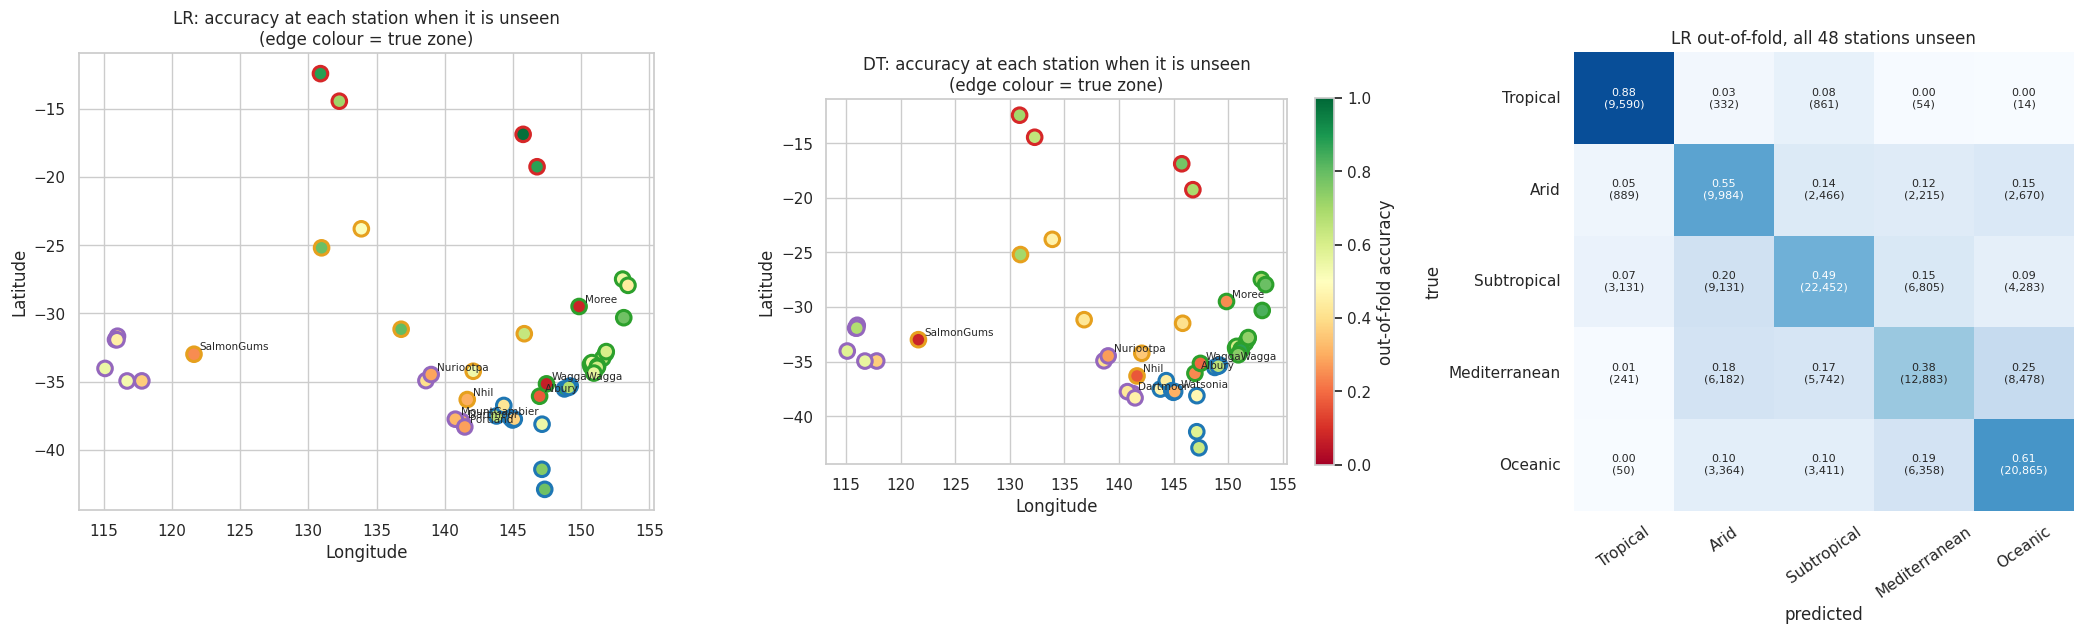

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6.3), gridspec_kw={"width_ratios": [1.15, 1.15, 1]})
xy = zones.set_index("Location").loc[station_acc.index]
for ax, name in zip(axes[:2], ["LR", "DT"]):
    sc = ax.scatter(xy["lon"], xy["lat"], c=station_acc[name], cmap="RdYlGn", vmin=0, vmax=1, s=110,
                    edgecolor=[ZONE_COLORS[z] for z in station_acc["Zone"]], linewidths=2.2)
    for loc, r in xy.iterrows():
        if station_acc.loc[loc, name] < 0.35:
            ax.annotate(loc, (r["lon"], r["lat"]), fontsize=7.5, xytext=(4, 3), textcoords="offset points")
    ax.set(title=f"{name}: accuracy at each station when it is unseen\n(edge colour = true zone)",
           xlabel="Longitude", ylabel="Latitude"); ax.set_aspect("equal")
plt.colorbar(sc, ax=axes[1], shrink=0.8).set_label("out-of-fold accuracy")
plot_cm(axes[2], y, oof["LR"], "LR out-of-fold, all 48 stations unseen")
plt.tight_layout(); savefig("p5_station_errors"); plt.show()

**What the errors tell us.** Out-of-fold, LR and the tuned tree reach about 0.53–0.55 accuracy over all 48 unseen
stations, but the accuracy per station ranges from below 0.1 to above 0.9:

* **Tropical and coastal Subtropical stations** (Darwin, Cairns, Sydney–Brisbane coast) are recognised well.
* **Inland Subtropical stations** (Wagga Wagga, Moree, Albury) are the worst (LR accuracy 0.06–0.17). Köppen calls
  them Cfa because they have hot summers and no dry season, but their weather is continental — hot dry summers,
  cold nights — and the model calls them Arid, Mediterranean or Oceanic. In the training data "Subtropical"
  means mostly the humid coast.
* **Mediterranean stations of south-east South Australia and western Victoria** (Portland, Dartmoor, Mount Gambier,
  Nuriootpa) are mostly predicted as Oceanic: their summer is only slightly drier than their winter, which is enough
  for Köppen's Cs rule but is a weak signal in a single day.
* **Cool semi-arid stations** (Nhil, Salmon Gums, Köppen BSk) do not look like the hot deserts that dominate the
  Arid class.

These are the same groupings found by the station-profile clustering in Part 3 (coast vs. inland). The labels are
correct by the Köppen definition, but the definition uses thresholds on monthly statistics that a single day hardly
reveals. With only about 38 training stations per fold, the main limit on generalisation is the **number and
diversity of training stations**, not the number of days.

### 5.6 How reliable is one unseen-station number? Pooled vs. per-fold scores

The out-of-fold predictions above can be summarised in two ways:

* **pooled**: concatenate the predictions of all 5 folds and compute one macro-F1 over all 48 stations;
* **per fold**: compute macro-F1 inside each fold (9–11 held-out stations) and report mean ± standard deviation.

Per fold there is a subtlety. With only 4 Tropical stations, some folds contain no Tropical days at all; sklearn's
default `f1_score(average="macro")` still averages over every class that appears in the *predictions*, so a fold
with no Tropical days but a few Tropical predictions gets a Tropical F1 of 0. We therefore compute per-fold
macro-F1 over the classes **present in that fold** and show the default version for comparison.

In [55]:
def per_fold_f1(pred, folds, present_only=True):
    out = []
    for _, te in folds:
        labels = np.unique(y[te]) if present_only else None
        out.append(f1_score(y[te], pred[te], labels=labels, average="macro"))
    return np.array(out)

FOLDS_42 = list(CV_SCHEMES["grouped"].split(X_all, y, groups.values))   # folds depend only on y and the stations
print("held-out stations per fold:", [groups.iloc[te].nunique() for _, te in FOLDS_42])
print("zones present per fold:   ", [len(np.unique(y[te])) for _, te in FOLDS_42])
fold_tab = {}
for name in ["LR", "DT"]:
    pf, pf_default = per_fold_f1(oof[name], FOLDS_42), per_fold_f1(oof[name], FOLDS_42, present_only=False)
    fold_tab[f"{name} (tuned)"] = {"pooled macro-F1": f1_score(y, oof[name], average="macro"),
                                   "per-fold mean (present classes)": pf.mean(), "per-fold std": pf.std(),
                                   "per-fold min": pf.min(), "per-fold max": pf.max(),
                                   "per-fold mean (sklearn default)": pf_default.mean()}
pd.DataFrame(fold_tab).T.round(3)

held-out stations per fold: [9, 11, 9, 10, 9]
zones present per fold:    [4, 4, 4, 5, 5]


,pooled macro-F1,per-fold mean (present classes),per-fold std,per-fold min,per-fold max,per-fold mean (sklearn default)
LR (tuned),0.553,0.544,0.080,0.442,0.633,0.483
DT (tuned),0.557,0.551,0.071,0.449,0.642,0.487


Two conclusions:

1. sklearn's default per-fold macro-F1 is about 0.06 lower than the other two summaries (LR: 0.483 vs 0.544
   per fold over the classes present and 0.553 pooled) because of the absent-class effect. This is also why the
   grouped-CV scores of the grid search in Section 5.3 look low. Computed over the classes present, the per-fold
   mean is close to the pooled score.
2. Scores vary between groups of held-out stations by about ± 0.07–0.08 (LR: 0.44–0.63). The single 15-station test
   split of Part 4 is one draw from this distribution. Section 6.6 repeats the grouped CV with three fold seeds
   (15 held-out station groups), adds a time-based split, and compares models fold by fold.

### 5.7 Discussion of model performance

*(word count printed below)*

Both simple models recognise tropical days reliably (one-vs-rest AUC above 0.97) but confuse the three southern zones, which overlap in feature space as already seen with t-SNE. Logistic regression shows almost no gap between training and test scores: it underfits because the zone boundaries are not linear, and tuning C does not help. The unconstrained decision tree is the opposite: perfect on the training set, clearly worse on the test set, and its near-binary probabilities give a poor ROC curve. Limiting depth and leaf size through cross-validation removes most of this overfitting and raises both macro-F1 and AUC. The most important result is the comparison of the two splits. On a random split every station is already known, so the tree partly memorises station-specific weather. On stations never seen in training, all scores drop and vary strongly between stations, and the tuned tree is no longer clearly better than logistic regression. Accuracy alone would hide these differences; macro-F1 and per-zone AUC reveal them. Further improvement needs more flexible models and features that summarise more than one day of weather (Section 6).

In [56]:
DISCUSSION_TEXT = '''Both simple models recognise tropical days reliably (one-vs-rest AUC above 0.97) but confuse the three southern zones, which overlap in feature space as already seen with t-SNE. Logistic regression shows almost no gap between training and test scores: it underfits because the zone boundaries are not linear, and tuning C does not help. The unconstrained decision tree is the opposite: perfect on the training set, clearly worse on the test set, and its near-binary probabilities give a poor ROC curve. Limiting depth and leaf size through cross-validation removes most of this overfitting and raises both macro-F1 and AUC. The most important result is the comparison of the two splits. On a random split every station is already known, so the tree partly memorises station-specific weather. On stations never seen in training, all scores drop and vary strongly between stations, and the tuned tree is no longer clearly better than logistic regression. Accuracy alone would hide these differences; macro-F1 and per-zone AUC reveal them. Further improvement needs more flexible models and features that summarise more than one day of weather (Section 6).'''
print("discussion word count:", len(DISCUSSION_TEXT.split()))

discussion word count: 181


## 6. Open-ended Exploration

Parts 4–5 left two open questions: (1) do more flexible model classes help, and do they help on *unseen stations*
or only on known ones? (2) Part 3 showed that a station's *climate profile* identifies its zone much better than a
single day — can we give the classifier "more than one day" of weather?

We explore four directions suggested in the task description:

| Section | Direction | Technique |
|---|---|---|
| 6.1 | Model comparison | 7 model classes compared with cross-validation, random vs. station-grouped |
| 6.2 | Model complexity / regulariser | polynomial features + L2 in logistic regression (inside 6.1) |
| 6.3 | Hyperparameter tuning | randomised search for gradient boosting with station-grouped CV |
| 6.4 | Feature engineering | physically derived features; "climate memory" rolling-window features |
| 6.5 | Feature selection | permutation importance; performance vs. number of selected features |

**Evaluation protocol (all of Section 6).** For every model we report two numbers:

* **random**: macro-F1 on the random 30% test set (model trained on the random 70%);
* **unseen stations**: out-of-fold predictions from `StratifiedGroupKFold(5)` over all 48 stations, so every station
  is predicted once by a model that never saw it. We report the pooled macro-F1 and the per-fold mean ± std
  (classes present in the fold, Section 5.6). This uses all stations and is less noisy than the single 15-station
  test set.

All models use the same 20 `core` features, the same median imputation (fitted inside each training fold), the same
random 70/30 split and the same five station folds. Section 6.6 adds a time-based split and two more fold seeds for the
key models.

In [57]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RandomizedSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import PolynomialFeatures
from scipy.stats import loguniform, randint
import warnings

GCV = CV_SCHEMES["grouped"]          # StratifiedGroupKFold(5, shuffle=True, random_state=42)
best_dt = searches[("DT", "grouped")].best_params_

MODEL_ZOO = {
    "Logistic Regression": lambda: make_pipeline(build_preprocessor(), LogisticRegression(C=1, max_iter=3000)),
    "LR + degree-2 polynomial (C=0.1)": lambda: make_pipeline(build_preprocessor(), PolynomialFeatures(2), StandardScaler(),
                                                             LogisticRegression(C=0.1, max_iter=3000)),
    "Decision Tree (tuned)": lambda: make_model("DT").set_params(**best_dt),
    "k-NN (k=15)": lambda: make_pipeline(build_preprocessor(), KNeighborsClassifier(n_neighbors=15)),
    "Random Forest (200 trees)": lambda: make_pipeline(build_preprocessor(),
                                                       RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                                              n_jobs=2, random_state=RANDOM_STATE)),
    "MLP (64-32)": lambda: make_pipeline(build_preprocessor(), MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3,
                                                                             max_iter=60, random_state=RANDOM_STATE)),
    "Gradient Boosting (HGB, default)": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                                              HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
}

def two_protocols(make, X):
    # returns random-split test macro-F1, grouped out-of-fold predictions, and timing
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")            # MLP: max_iter reached (intentional, keeps the run short)
        t0 = time.time()
        m = make().fit(X.iloc[rand_tr], y[rand_tr])
        fit_time = time.time() - t0
        rand_f1 = f1_score(y[rand_te], m.predict(X.iloc[rand_te]), average="macro")
        oof_pred = cross_val_predict(make(), X, y, groups=groups.values, cv=GCV, n_jobs=2)
    return {"random test macro-F1": rand_f1, "oof": oof_pred, "fit time (s)": fit_time}

GROUPED_FOLDS = list(GCV.split(X_all, y, groups.values))    # identical to FOLDS_42 of Section 5.6

def summarise(res):
    pf = per_fold_f1(res["oof"], GROUPED_FOLDS)
    return {"random test macro-F1": res["random test macro-F1"],
            "unseen stations macro-F1": f1_score(y, res["oof"], average="macro"),
            "unseen per-fold mean": pf.mean(), "unseen per-fold std": pf.std(),
            "unseen stations accuracy": accuracy_score(y, res["oof"]),
            "fit time (s)": res["fit time (s)"]}

### 6.1–6.2 Model comparison (7 model classes) and model complexity

Why these models: **k-NN** (instance-based, no training), **Random Forest** (bagging of deep trees, reduces the
variance we saw in Part 4), **Gradient Boosting** (sequentially fitted shallow trees, reduces bias), **MLP**
(non-linear features learned by a neural network), and **LR with degree-2 polynomial features** (the same linear
model with 230 interaction/square features plus a stronger L2 penalty — a direct test of model complexity vs. regularisation).

In [58]:
zoo = {name: cached("p6_zoo_" + "".join(ch for ch in name if ch.isalnum()), lambda mk=mk: two_protocols(mk, X_all),
                    model=name, features="core", best_dt=repr(best_dt))
       for name, mk in MODEL_ZOO.items()}
zoo_table = pd.DataFrame({n: summarise(r) for n, r in zoo.items()}).T
zoo_table["gap (random − unseen)"] = zoo_table["random test macro-F1"] - zoo_table["unseen stations macro-F1"]
zoo_table.sort_values("unseen stations macro-F1", ascending=False).round(3)

,random test macro-F1,unseen stations macro-F1,unseen per-fold mean,unseen per-fold std,unseen stations accuracy,fit time (s),gap (random − unseen)
"Gradient Boosting (HGB, default)",0.795,0.638,0.624,0.090,0.628,4.174,0.157
MLP (64-32),0.782,0.633,0.619,0.076,0.620,10.861,0.149
Random Forest (200 trees),0.785,0.631,0.628,0.089,0.630,14.498,0.153
LR + degree-2 polynomial (C=0.1),0.752,0.623,0.609,0.074,0.610,20.530,0.128
k-NN (k=15),0.768,0.585,0.580,0.077,0.581,0.151,0.183
Decision Tree (tuned),0.691,0.557,0.551,0.071,0.550,0.907,0.134
Logistic Regression,0.615,0.525,0.523,0.078,0.522,2.353,0.090


**Exact configuration of every model** (read from the fitted pipelines, so the table cannot drift from the code).
Fit time is for one fit on the random 70% training set (~100,000 days) on 2 CPU cores.

In [59]:
KEY_PARAMS = {"LogisticRegression": ["C", "penalty", "solver", "max_iter", "class_weight"],
              "DecisionTreeClassifier": ["criterion", "max_depth", "min_samples_leaf"],
              "KNeighborsClassifier": ["n_neighbors", "weights", "metric"],
              "RandomForestClassifier": ["n_estimators", "min_samples_leaf", "max_features", "bootstrap"],
              "MLPClassifier": ["hidden_layer_sizes", "activation", "solver", "alpha", "batch_size", "max_iter"],
              "HistGradientBoostingClassifier": ["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf",
                                                 "l2_regularization", "early_stopping"]}
spec_rows = []
for name, mk in MODEL_ZOO.items():
    pipe = mk(); est = pipe[-1]; prm = est.get_params()
    pre = []
    for step in pipe[:-1]:
        pre += [type(t).__name__ for _, t in step.steps] if isinstance(step, Pipeline) else [type(step).__name__]
    spec_rows.append({"model": name, "preprocessing (fitted on training rows only)": " → ".join(pre),
                      "key hyperparameters": ", ".join(f"{k}={prm[k]}" for k in KEY_PARAMS[type(est).__name__]),
                      "fit time (s)": round(zoo[name]["fit time (s)"], 1)})
with pd.option_context("display.max_colwidth", 120):
    display(pd.DataFrame(spec_rows).set_index("model"))
print("HGB early_stopping='auto' is active because n_samples > 10,000 (10% of the training rows are held out "
      "internally; at most max_iter boosting rounds).")

,preprocessing (fitted on training rows only),key hyperparameters,fit time (s)
model,,,
Logistic Regression,SimpleImputer → StandardScaler,"C=1, penalty=l2, solver=lbfgs, max_iter=3000, class_weight=None",2.4
LR + degree-2 polynomial (C=0.1),SimpleImputer → StandardScaler → PolynomialFeatures → StandardScaler,"C=0.1, penalty=l2, solver=lbfgs, max_iter=3000, class_weight=None",20.5
Decision Tree (tuned),SimpleImputer → StandardScaler,"criterion=gini, max_depth=16, min_samples_leaf=20",0.9
k-NN (k=15),SimpleImputer → StandardScaler,"n_neighbors=15, weights=uniform, metric=minkowski",0.2
Random Forest (200 trees),SimpleImputer → StandardScaler,"n_estimators=200, min_samples_leaf=5, max_features=sqrt, bootstrap=True",14.5
MLP (64-32),SimpleImputer → StandardScaler,"hidden_layer_sizes=(64, 32), activation=relu, solver=adam, alpha=0.001, batch_size=auto, max_iter=60",10.9
"Gradient Boosting (HGB, default)",SimpleImputer,"learning_rate=0.1, max_iter=100, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=0.0, early_stopping=auto",4.2


HGB early_stopping='auto' is active because n_samples > 10,000 (10% of the training rows are held out internally; at most max_iter boosting rounds).


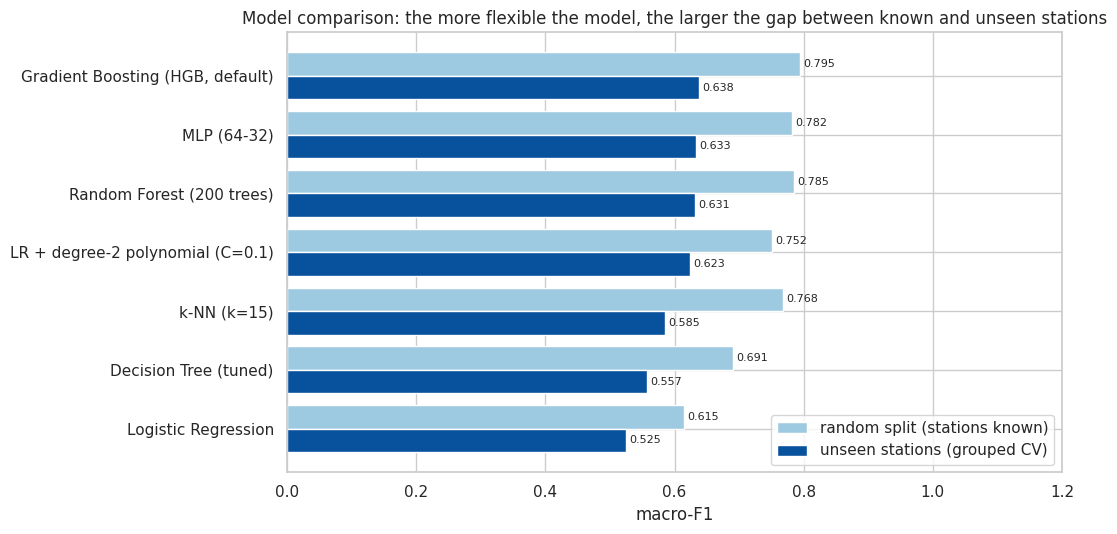

In [60]:
zt = zoo_table.sort_values("unseen stations macro-F1")
fig, ax = plt.subplots(figsize=(11, 5.5))
ypos = np.arange(len(zt))
ax.barh(ypos + 0.2, zt["random test macro-F1"], height=0.4, color="#9ecae1", label="random split (stations known)")
ax.barh(ypos - 0.2, zt["unseen stations macro-F1"], height=0.4, color="#08519c", label="unseen stations (grouped CV)")
for i, (r, u) in enumerate(zip(zt["random test macro-F1"], zt["unseen stations macro-F1"])):
    ax.text(r + 0.005, i + 0.2, f"{r:.3f}", va="center", fontsize=8); ax.text(u + 0.005, i - 0.2, f"{u:.3f}", va="center", fontsize=8)
ax.set_yticks(ypos); ax.set_yticklabels(zt.index); ax.set_xlim(0, 1.2)
ax.set(xlabel="macro-F1", title="Model comparison: the more flexible the model, the larger the gap between known and unseen stations")
ax.legend(loc="lower right"); plt.tight_layout(); savefig("p6_model_comparison"); plt.show()

**Findings.**

* On the random split the flexible models (gradient boosting, random forest, MLP, k-NN, polynomial LR) beat plain
  LR by 0.14–0.18 macro-F1. On unseen stations they still win, in almost the same order, but by only 0.06–0.11.
  The gap column grows with flexibility (LR 0.09, k-NN 0.18): part of what flexible models learn on a random split
  is station identity. k-NN, which literally looks up the most similar training days, has the largest gap.
* **Model complexity vs. regularisation**: degree-2 polynomial features (230 features, `C = 0.1`) raise LR from
  0.615 to 0.752 on the random split and from 0.525 to 0.623 on unseen stations. Interactions such as
  *MinTemp × Humidity* remove much of LR's bias, and this gain does transfer to new stations.
* Gradient boosting is the best model under both protocols and the fastest of the strong models (≈ 4 s per fit);
  MLP and random forest are within 0.01. We tune it in 6.3 and use it for the feature experiments.

### 6.3 Hyperparameter tuning: randomised search for gradient boosting

Randomised search (`ParameterSampler`, the sampler used inside `RandomizedSearchCV`) draws 16 configurations from continuous/discrete distributions instead of a fixed grid,
evaluated with station-grouped 5-fold CV on the grouped training set (so the selection criterion is "performance on
unseen stations"). The tuned model is then tested once on the 15 held-out stations.

In [61]:
HGB_SPACE = {"histgradientboostingclassifier__learning_rate": loguniform(0.02, 0.3),
             "histgradientboostingclassifier__max_leaf_nodes": randint(8, 64),
             "histgradientboostingclassifier__min_samples_leaf": randint(20, 400),
             "histgradientboostingclassifier__l2_regularization": loguniform(1e-3, 10),
             "histgradientboostingclassifier__max_iter": randint(100, 400)}

HGB_DEFAULT = lambda: make_pipeline(SimpleImputer(strategy="median"), HistGradientBoostingClassifier(random_state=RANDOM_STATE))
# Equivalent to RandomizedSearchCV(n_iter=16), written as an explicit loop so that every sampled
# configuration is cached on its own (one configuration = 5 fits, ~20-40 s).
from sklearn.model_selection import ParameterSampler, cross_validate
rs_rows = []
for i, params in enumerate(ParameterSampler(HGB_SPACE, n_iter=16, random_state=RANDOM_STATE)):
    cvres = cached("p6_hgb_cfg", lambda params=params: cross_validate(
        HGB_DEFAULT().set_params(**params), X_all.iloc[grp_tr], y[grp_tr], groups=groups.iloc[grp_tr].values,
        cv=GCV, scoring="f1_macro", return_train_score=True, n_jobs=2), params=repr(sorted(params.items())), cv=repr(GCV))
    rs_rows.append({**{k.split("__")[1]: v for k, v in params.items()},
                    "mean_train_score": cvres["train_score"].mean(), "mean_test_score": cvres["test_score"].mean(),
                    "std_test_score": cvres["test_score"].std(), "_params": params})
rs_res = pd.DataFrame(rs_rows).sort_values("mean_test_score", ascending=False)
best_hgb_params = rs_res["_params"].iloc[0]
hgb_tuned = HGB_DEFAULT().set_params(**best_hgb_params).fit(X_all.iloc[grp_tr], y[grp_tr])
display(rs_res.drop(columns="_params").head(6).round(3))

hgb_default_cv = cached("p6_hgb_default_groupedcv", lambda: cross_val_score(
    HGB_DEFAULT(), X_all.iloc[grp_tr], y[grp_tr], groups=groups.iloc[grp_tr].values, cv=GCV,
    scoring="f1_macro", n_jobs=2).mean(), cv=repr(GCV))
hgb_default = HGB_DEFAULT().fit(X_all.iloc[grp_tr], y[grp_tr])
tuning_cmp = pd.DataFrame({
    "default HGB": {"grouped CV macro-F1 (33 training stations)": hgb_default_cv,
                    "test macro-F1 (15 unseen stations)": f1_score(y[grp_te], hgb_default.predict(X_all.iloc[grp_te]), average="macro")},
    "tuned HGB": {"grouped CV macro-F1 (33 training stations)": rs_res["mean_test_score"].iloc[0],
                  "test macro-F1 (15 unseen stations)": f1_score(y[grp_te], hgb_tuned.predict(X_all.iloc[grp_te]), average="macro")},
}).T
tuning_cmp.round(3)

,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,mean_train_score,mean_test_score,std_test_score
14,0.020,0.094,351,47,232,0.968,0.481,0.082
9,7.287,0.179,364,33,72,0.972,0.481,0.085
7,0.114,0.099,230,44,326,0.939,0.480,0.084
5,0.015,0.105,269,35,207,0.940,0.480,0.084
6,0.029,0.069,274,58,383,0.944,0.480,0.081
10,0.008,0.038,363,54,54,0.931,0.479,0.083


,grouped CV macro-F1 (33 training stations),test macro-F1 (15 unseen stations)
default HGB,0.472,0.632
tuned HGB,0.481,0.636


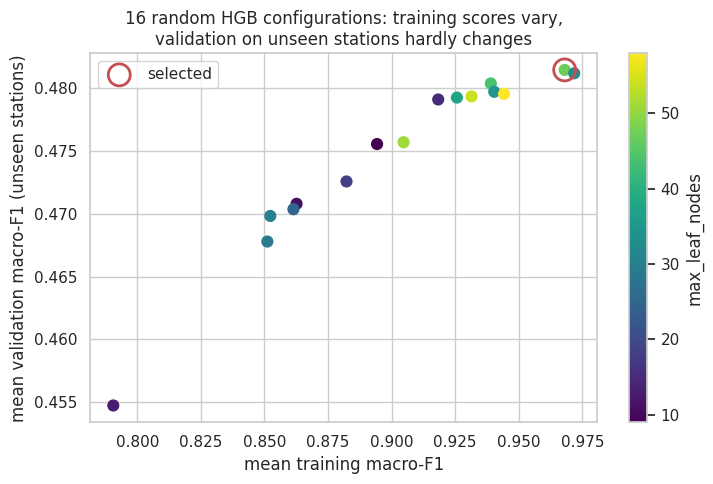

In [62]:
fig, ax = plt.subplots(figsize=(7.5, 5))
sc = ax.scatter(rs_res["mean_train_score"], rs_res["mean_test_score"],
                c=rs_res["max_leaf_nodes"].astype(float), cmap="viridis", s=60)
plt.colorbar(sc).set_label("max_leaf_nodes")
best = rs_res.iloc[0]
ax.scatter(best["mean_train_score"], best["mean_test_score"], s=250, facecolors="none", edgecolors="r", lw=2, label="selected")
ax.set(xlabel="mean training macro-F1", ylabel="mean validation macro-F1 (unseen stations)",
       title="16 random HGB configurations: training scores vary,\nvalidation on unseen stations hardly changes")
ax.legend(); plt.tight_layout(); savefig("p6_hgb_search"); plt.show()

**Findings.** All 16 configurations fit the training stations very well (macro-F1 0.93–0.97) but score
0.47–0.48 on validation stations; the best is only 0.009 above the default model, and on the 15 test stations the
gain is 0.004. The hyperparameters are not what limits gradient boosting here: the validation stations simply
differ from the training stations. (The grouped-CV level, 0.48, is lower than the 15-station test score, 0.63, for
two reasons. First, the search uses sklearn's default per-fold macro-F1, which counts a class with F1 = 0 in folds
where it is predicted but absent (Section 5.6). Second, each fold holds out only 6–7 of 33 stations, so the score
depends strongly on which stations are held out. Configurations are therefore compared only with each other.)

### 6.4 Feature engineering

**(a) Physically derived features.** Meteorologists describe a climate by daily *ranges and changes*, not only
levels. We add four features: diurnal temperature range `MaxTemp − MinTemp` (large in dry climates), humidity
drop `Humidity9am − Humidity3pm`, pressure change `Pressure3pm − Pressure9am`, and warming `Temp3pm − Temp9am`.

**(b) "Climate memory": how many days do you need to know where you are?** Part 3 showed that a station's
long-term profile reveals its zone far better than a single day. We therefore replace each day's measurements by
their mean over the last N calendar days at the same station. For station *s*, day *t* and daily feature *j*:

$$\bar x^{(N)}_{s,t,j} \;=\; \frac{1}{|W|}\sum_{\tau \in W} x_{s,\tau,j}, \qquad
W = \{\tau : t-N < \tau \le t,\; x_{s,\tau,j}\ \text{observed}\},$$

defined only if $|W| \ge \max(1, \lfloor N/3 \rfloor)$, otherwise missing.

* The window contains day *t* itself and the N − 1 days before it, and **never a later day**
  (pandas time-based `rolling("ND")`, which is right-closed).
* It is measured in **calendar days**: a gap in the record shortens the window's count instead of reaching further
  back. Missing values inside the window are skipped.
* At the start of a station's record (fewer than ⌊N/3⌋ observed days) the value is missing; like every other missing
  value it is filled by the median imputer that is fitted inside each training fold.
* The 18 daily features are averaged; `doy_sin` / `doy_cos` of day *t* are kept unchanged.

**Why computing the windows once on the full table does not leak in grouped CV.** A row's window uses only the same
station's own weather (no labels, no statistics learned across stations), and under station-grouped CV every station
is entirely in either the training or the validation fold. No information can pass from validation rows to
training rows. Under a **random** split this is not true: neighbouring days of the same station share most of their
window and land on both sides, so almost every test day has a near-copy in the training set. We show the
random-split number once as a warning; the time-based split in 6.6 uses a 14-day embargo for the same reason.

The question becomes: *"If you were dropped at an unknown Australian weather station and watched the weather for
N days, how well could you tell its climate zone?"*

In [63]:
BASE_DAILY = [c for c in FEATURE_SETS["core"] if not c.startswith("doy")]

def derived_features(Fr):
    out = Fr[FEATURE_SETS["core"]].copy()
    out["TempRange"] = Fr["MaxTemp"] - Fr["MinTemp"]
    out["HumidityDrop"] = Fr["Humidity9am"] - Fr["Humidity3pm"]
    out["PressureChange"] = Fr["Pressure3pm"] - Fr["Pressure9am"]
    out["Warming"] = Fr["Temp3pm"] - Fr["Temp9am"]
    return out

def rolling_features(window_days, cols=BASE_DAILY):
    # trailing N-day mean per station (past + today only); row order is restored at the end
    t = F[cols].copy(); t["_date"] = df["Date"].values; t["_st"] = groups.values
    t = t.sort_values(["_st", "_date"])
    parts = []
    for _, s in t.groupby("_st"):
        r = s.set_index("_date")[cols].rolling(f"{window_days}D", min_periods=max(1, window_days // 3)).mean()
        r.index = s.index; parts.append(r)
    out = pd.concat(parts).loc[F.index]
    out.columns = [f"{c}_mean{window_days}d" for c in cols]
    return out

X_derived = derived_features(F)
WINDOWS = [1, 3, 7, 14, 30, 90, 365]
X_windows = {N: (X_all if N == 1 else pd.concat([rolling_features(N), F[["doy_sin", "doy_cos"]]], axis=1)) for N in WINDOWS}
X_multi = pd.concat([X_all] + [rolling_features(N) for N in (7, 30, 90)], axis=1)   # today + 7/30/90-day means
print("derived:", X_derived.shape[1], "features | rolling:", X_windows[30].shape[1], "| multi-scale:", X_multi.shape[1])
miss14 = X_windows[14][[f"{c}_mean14d" for c in BASE_DAILY]].isna().mean()
print(f"14-day means missing before imputation: median {miss14.median():.2%}, max {miss14.max():.2%} ({miss14.idxmax()})")

derived: 24 features | rolling: 20 | multi-scale: 74
14-day means missing before imputation: median 1.84%, max 10.59% (Pressure9am_mean14d)


In [64]:
HGB = MODEL_ZOO["Gradient Boosting (HGB, default)"]
fe_results = {"core (20 daily features)": zoo["Gradient Boosting (HGB, default)"]}
fe_results["core + 4 derived"] = cached("p6_fe_derived", lambda: two_protocols(HGB, X_derived), version=1)
for N in WINDOWS[1:]:
    fe_results[f"{N}-day trailing mean"] = cached(f"p6_fe_roll{N}", lambda N=N: two_protocols(HGB, X_windows[N]), window=N, version=1)
fe_results["multi-scale: today + 7/30/90-day means"] = cached("p6_fe_multi", lambda: two_protocols(HGB, X_multi), windows=(7, 30, 90), version=1)
fe_table = pd.DataFrame({k: summarise(v) for k, v in fe_results.items()}).T.drop(columns="fit time (s)")
fe_table.round(3)

,random test macro-F1,unseen stations macro-F1,unseen per-fold mean,unseen per-fold std,unseen stations accuracy
core (20 daily features),0.795,0.638,0.624,0.090,0.628
core + 4 derived,0.800,0.641,0.627,0.085,0.632
3-day trailing mean,0.852,0.678,0.667,0.093,0.670
7-day trailing mean,0.914,0.710,0.700,0.088,0.706
14-day trailing mean,0.965,0.727,0.720,0.090,0.723
30-day trailing mean,0.989,0.715,0.713,0.093,0.722
90-day trailing mean,0.993,0.711,0.713,0.105,0.724
365-day trailing mean,0.973,0.655,0.645,0.089,0.668
multi-scale: today + 7/30/90-day means,0.999,0.718,0.717,0.103,0.730


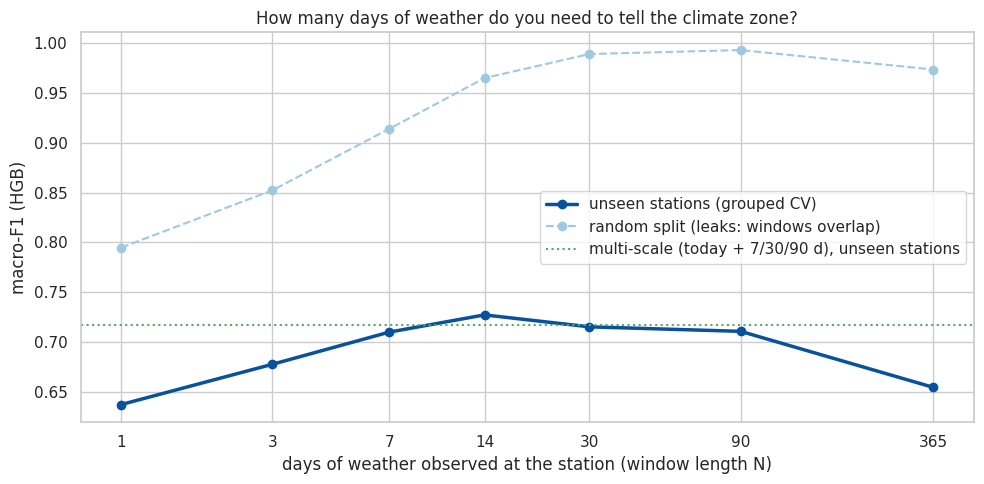

In [65]:
curve = fe_table.loc[["core (20 daily features)"] + [f"{N}-day trailing mean" for N in WINDOWS[1:]]]
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(WINDOWS, curve["unseen stations macro-F1"], marker="o", lw=2.5, color="#08519c", label="unseen stations (grouped CV)")
ax.plot(WINDOWS, curve["random test macro-F1"], marker="o", ls="--", color="#9ecae1", label="random split (leaks: windows overlap)")
ax.axhline(fe_table.loc["multi-scale: today + 7/30/90-day means", "unseen stations macro-F1"], color="C2", ls=":",
           label="multi-scale (today + 7/30/90 d), unseen stations")
ax.set_xscale("log"); ax.set_xticks(WINDOWS); ax.set_xticklabels(WINDOWS)
ax.set(xlabel="days of weather observed at the station (window length N)", ylabel="macro-F1 (HGB)",
       title="How many days of weather do you need to tell the climate zone?")
ax.legend(); plt.tight_layout(); savefig("p6_climate_memory"); plt.show()

**Findings.**

* The four derived features change little (+0.003): gradient boosting can already combine two inputs through
  successive splits.
* **Averaging the weather over a few days helps strongly on unseen stations**: macro-F1 rises from 0.638 (one day)
  to 0.710 (one week) and peaks at 0.727 for two weeks. A single day is dominated by the current weather situation
  (Part 3's "weather regimes"); averaging cancels the day-to-day noise and leaves the climate signal.
* **Longer windows do not help, and a one-year mean is clearly worse (0.655).** A one-year mean removes the seasonal
  cycle — exactly the information (summer vs. winter rain, seasonal temperature range) that Köppen uses to define
  the zones.
* Combining several time scales (today + 7/30/90-day means, 74 features) gives the best accuracy (0.730) but not a
  better macro-F1 (0.718) than the 14-day window alone; the differences between 7 and 90 days are within noise.
* The random-split curve reaches 0.99 for windows of 30 days or more: with overlapping windows, a test day has an
  almost identical neighbour in the training set. This is the strongest example of station leakage in the project
  and the reason we only trust the unseen-station curve.

### 6.5 Feature selection: what does the model use?

Permutation importance of the best model (multi-scale HGB trained on the grouped training set): how much
macro-F1 on the 15 unseen test stations drops when one feature is randomly shuffled (3 repeats, 10,000 random test days).
We then retrain using only the top-k features to see how many are actually needed.

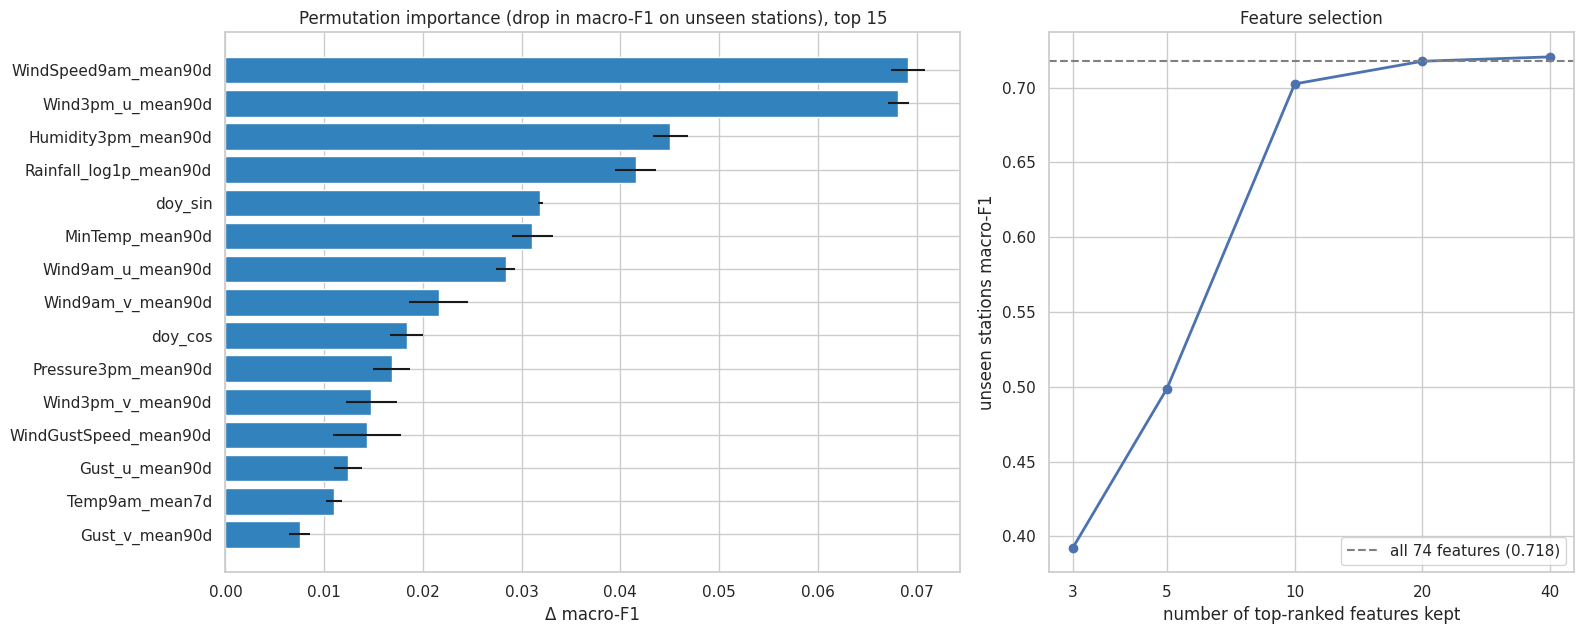

,top-k features,unseen stations macro-F1,features
0,3,0.392,"WindSpeed9am_mean90d, Wind3pm_u_mean90d, Humid..."
1,5,0.499,"WindSpeed9am_mean90d, Wind3pm_u_mean90d, Humid..."
2,10,0.702,"WindSpeed9am_mean90d, Wind3pm_u_mean90d, Humid..."
3,20,0.718,"WindSpeed9am_mean90d, Wind3pm_u_mean90d, Humid..."
4,40,0.721,"WindSpeed9am_mean90d, Wind3pm_u_mean90d, Humid..."


In [66]:
def importance():
    model = HGB().fit(X_multi.iloc[grp_tr], y[grp_tr])
    sub = np.random.default_rng(RANDOM_STATE).choice(grp_te, 10000, replace=False)
    pi = permutation_importance(model, X_multi.iloc[sub], y[sub], scoring="f1_macro", n_repeats=3,
                                random_state=RANDOM_STATE, n_jobs=2)
    return pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std},
                        index=X_multi.columns).sort_values("mean", ascending=False)

imp = cached("p6_importance", importance, version=1, cols=tuple(X_multi.columns))
sel_rows = []
for k in [3, 5, 10, 20, 40]:
    cols = list(imp.index[:k])
    p = cached(f"p6_select_top{k}", lambda cols=cols: cross_val_predict(HGB(), X_multi[cols], y, groups=groups.values,
                                                                        cv=GCV, n_jobs=2), cols=tuple(cols))
    sel_rows.append({"top-k features": k, "unseen stations macro-F1": f1_score(y, p, average="macro"),
                     "features": ", ".join(cols[:5]) + (" ..." if k > 5 else "")})
selection = pd.DataFrame(sel_rows)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.4, 1]})
top = imp.head(15)[::-1]
axes[0].barh(top.index, top["mean"], xerr=top["std"], color="#3182bd")
axes[0].set(title="Permutation importance (drop in macro-F1 on unseen stations), top 15", xlabel="Δ macro-F1")
full_score = fe_table.loc["multi-scale: today + 7/30/90-day means", "unseen stations macro-F1"]
axes[1].plot(selection["top-k features"], selection["unseen stations macro-F1"], marker="o", lw=2)
axes[1].axhline(full_score, ls="--", color="grey", label=f"all {X_multi.shape[1]} features ({full_score:.3f})")
axes[1].set(xscale="log", xticks=selection["top-k features"], xticklabels=selection["top-k features"],
            xlabel="number of top-ranked features kept", ylabel="unseen stations macro-F1", title="Feature selection")
axes[1].legend(); plt.tight_layout(); savefig("p6_importance_selection"); plt.show()
selection.round(3)

**Findings.** The most important features are **90-day means**: mean morning wind speed, the east–west wind component
in the afternoon, afternoon humidity and rainfall, then the day of the year and the mean minimum temperature.
These are the long-term "climate" variables. Wind ranks first; part of this may be a site effect (how exposed the
anemometer is), but because the importance is measured on unseen stations, it also reflects real wind regimes such
as the south-east trade winds in the tropics and the westerlies in the south. Ten features reach 0.70 and twenty
match all 74 features (0.718), so most of the multi-scale features are redundant.

### 6.6 Three evaluation protocols for the key models

A single number per model can depend on the split. For the four models that carry our conclusions we compare:

| Protocol | Train | Test | Question |
|---|---|---|---|
| random 70/30 | random 70% of days | other 30% | new days, known stations (adjacent days on both sides) |
| **time 70/30** | days before the cut date | days ≥ cut + 14 days (embargo) | **future** days, known stations |
| **station-grouped, 3 × 5 folds** | 4/5 of the stations | the other 1/5 | **unseen stations**; `StratifiedGroupKFold` with seeds 42, 0, 7 → 15 held-out station groups |

The cut date is the first day of the month that contains the 70% quantile of all dates. The 14-day embargo removes
test days whose 14-day window would reach into the training period.

In [67]:
cut = df["Date"].quantile(0.7).to_period("M").to_timestamp()
time_tr = np.where(df["Date"] < cut)[0]
time_te = np.where(df["Date"] >= cut + pd.Timedelta(days=14))[0]
print(f"time split: train {df['Date'].min().date()} → {(cut - pd.Timedelta(days=1)).date()} ({len(time_tr):,} days), "
      f"test {(cut + pd.Timedelta(days=14)).date()} → {df['Date'].max().date()} ({len(time_te):,} days); "
      f"stations in test: {groups.iloc[time_te].nunique()}, also in train: "
      f"{len(set(groups.iloc[time_te]) & set(groups.iloc[time_tr]))}")

KEY_MODELS = {"Logistic Regression": (MODEL_ZOO["Logistic Regression"], X_all, zoo["Logistic Regression"]),
              "Decision Tree (tuned)": (MODEL_ZOO["Decision Tree (tuned)"], X_all, zoo["Decision Tree (tuned)"]),
              "HGB, daily features": (HGB, X_all, zoo["Gradient Boosting (HGB, default)"]),
              "HGB, 14-day trailing mean": (HGB, X_windows[14], fe_results["14-day trailing mean"])}
FOLD_SEEDS = [RANDOM_STATE, 0, 7]

def time_split_f1(make, X):
    m = make().fit(X.iloc[time_tr], y[time_tr])
    return f1_score(y[time_te], m.predict(X.iloc[time_te]), average="macro")

def grouped_oof(make, X, seed):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    return cross_val_predict(make(), X, y, groups=groups.values, cv=cv, n_jobs=2)

proto_rows, fold_scores = [], {}
for name, (make, X, res42) in KEY_MODELS.items():
    key = "".join(ch for ch in name if ch.isalnum())
    t_f1 = cached(f"p6_time_{key}", lambda make=make, X=X: time_split_f1(make, X), model=name, cut=str(cut), embargo=14)
    scores, pooled = [], []
    for seed in FOLD_SEEDS:
        pred = res42["oof"] if seed == RANDOM_STATE else cached(f"p6_oof_seed{seed}_{key}",
                                                                lambda make=make, X=X, seed=seed: grouped_oof(make, X, seed),
                                                                model=name, seed=seed)
        folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed).split(X_all, y, groups.values))
        scores.append(per_fold_f1(pred, folds)); pooled.append(f1_score(y, pred, average="macro"))
    fold_scores[name] = np.concatenate(scores)
    proto_rows.append({"model": name, "random 70/30": res42["random test macro-F1"], "time 70/30": t_f1,
                       "grouped: pooled (mean of 3 seeds)": np.mean(pooled),
                       "grouped: per-fold mean": fold_scores[name].mean(), "grouped: per-fold std": fold_scores[name].std(),
                       "grouped: min fold": fold_scores[name].min(), "grouped: max fold": fold_scores[name].max()})
protocols = pd.DataFrame(proto_rows).set_index("model")
protocols.round(3)

time split: train 2007-11-01 → 2014-12-31 (98,916 days), test 2015-01-15 → 2017-06-25 (42,863 days); stations in test: 48, also in train: 48


,random 70/30,time 70/30,grouped: pooled (mean of 3 seeds),grouped: per-fold mean,grouped: per-fold std,grouped: min fold,grouped: max fold
model,,,,,,,
Logistic Regression,0.615,0.599,0.503,0.509,0.058,0.402,0.623
Decision Tree (tuned),0.691,0.658,0.515,0.528,0.056,0.448,0.642
"HGB, daily features",0.795,0.765,0.599,0.599,0.069,0.494,0.732
"HGB, 14-day trailing mean",0.965,0.895,0.673,0.683,0.091,0.514,0.828


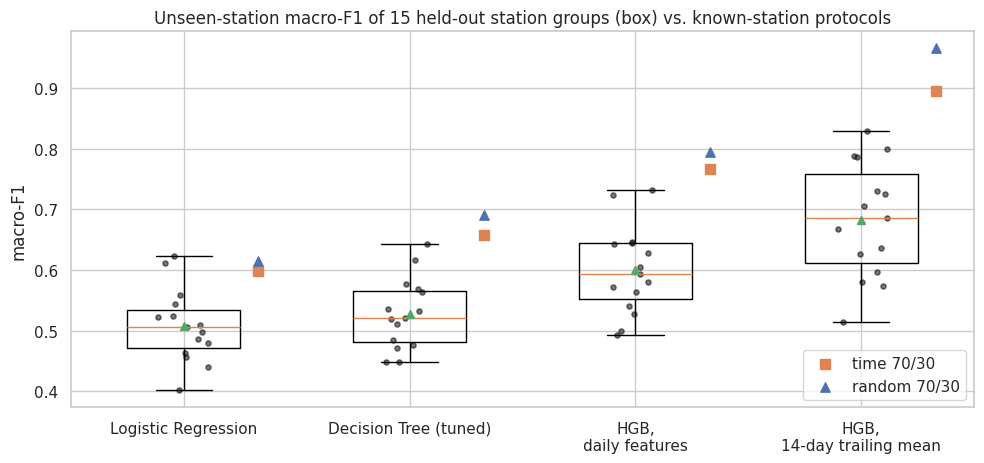

,mean difference,std of difference,folds where first is better
comparison,,,
"HGB, daily features − Logistic Regression",0.091,0.025,15 / 15
"HGB, daily features − Decision Tree (tuned)",0.072,0.022,15 / 15
Decision Tree (tuned) − Logistic Regression,0.019,0.028,10 / 15
"HGB, 14-day trailing mean − HGB, daily features",0.083,0.039,15 / 15


In [68]:
pairs = [("HGB, daily features", "Logistic Regression"), ("HGB, daily features", "Decision Tree (tuned)"),
         ("Decision Tree (tuned)", "Logistic Regression"), ("HGB, 14-day trailing mean", "HGB, daily features")]
paired = pd.DataFrame([{"comparison": f"{a}  −  {b}", "mean difference": (fold_scores[a] - fold_scores[b]).mean(),
                        "std of difference": (fold_scores[a] - fold_scores[b]).std(),
                        "folds where first is better": f"{int((fold_scores[a] > fold_scores[b]).sum())} / {len(fold_scores[a])}"}
                       for a, b in pairs]).set_index("comparison")

fig, ax = plt.subplots(figsize=(10, 4.8))
names = list(fold_scores)
ax.boxplot([fold_scores[n] for n in names], widths=0.5, showmeans=True)
for i, n in enumerate(names, start=1):
    ax.scatter(np.full(15, i) + np.random.default_rng(i).uniform(-0.12, 0.12, 15), fold_scores[n], s=14, color="k", alpha=0.6)
    ax.scatter(i + 0.33, protocols.loc[n, "time 70/30"], marker="s", color="C1", s=45, label="time 70/30" if i == 1 else None)
    ax.scatter(i + 0.33, protocols.loc[n, "random 70/30"], marker="^", color="C0", s=45, label="random 70/30" if i == 1 else None)
ax.set_xticks(range(1, len(names) + 1)); ax.set_xticklabels([n.replace(", ", ",\n") for n in names])
ax.set(ylabel="macro-F1", title="Unseen-station macro-F1 of 15 held-out station groups (box) vs. known-station protocols")
ax.legend(loc="lower right"); plt.tight_layout(); savefig("p6_protocols"); plt.show()
paired.round(3)

**Findings.**

* **Neighbouring days explain only a small part of the random-split optimism.** Going from the random to the time
  split (future days of known stations, 14-day embargo) lowers macro-F1 by 0.016–0.033 for single-day models and by
  0.07 for 14-day means. Going from the time split to unseen stations lowers it by a further 0.09–0.21. Most of the
  optimism of a random split comes from knowing the station, not from adjacent days.
* **The seed-42 folds used in 6.1–6.5 were slightly favourable.** Over 15 held-out station groups (3 seeds × 5 folds)
  the per-fold means are 0.51 ± 0.06 (LR), 0.53 ± 0.06 (tree), 0.60 ± 0.07 (HGB) and 0.68 ± 0.09 (HGB, 14-day
  means), 0.01–0.04 below the seed-42 values. Comparisons *within* one seed are unaffected because all models share
  the same folds; the 3-seed values are our headline estimates.
* **Paired comparisons are far more precise than the spread suggests.** Station groups differ a lot in difficulty,
  but they affect all models alike. HGB beats LR in 15 of 15 folds (+0.091 ± 0.025) and the tuned tree in 15 of 15;
  14-day means beat single days in 15 of 15 (+0.083 ± 0.039). The tuned tree beats LR in only 10 of 15 folds
  (+0.019 ± 0.028): on unseen stations the two simple models are not reliably different.

### 6.7 Final model choice

In [69]:
final_choice = pd.DataFrame({
    "Part 4 LR (default)": summarise(zoo["Logistic Regression"]),
    "Part 5 DT (tuned)": summarise(zoo["Decision Tree (tuned)"]),
    "HGB, daily features": summarise(zoo["Gradient Boosting (HGB, default)"]),
    "HGB, 14-day trailing mean": summarise(fe_results["14-day trailing mean"]),
    "HGB, multi-scale features": summarise(fe_results["multi-scale: today + 7/30/90-day means"]),
}).T.drop(columns="fit time (s)")
final_choice.round(3)

,random test macro-F1,unseen stations macro-F1,unseen per-fold mean,unseen per-fold std,unseen stations accuracy
Part 4 LR (default),0.615,0.525,0.523,0.078,0.522
Part 5 DT (tuned),0.691,0.557,0.551,0.071,0.550
"HGB, daily features",0.795,0.638,0.624,0.090,0.628
"HGB, 14-day trailing mean",0.965,0.727,0.720,0.090,0.723
"HGB, multi-scale features",0.999,0.718,0.717,0.103,0.730


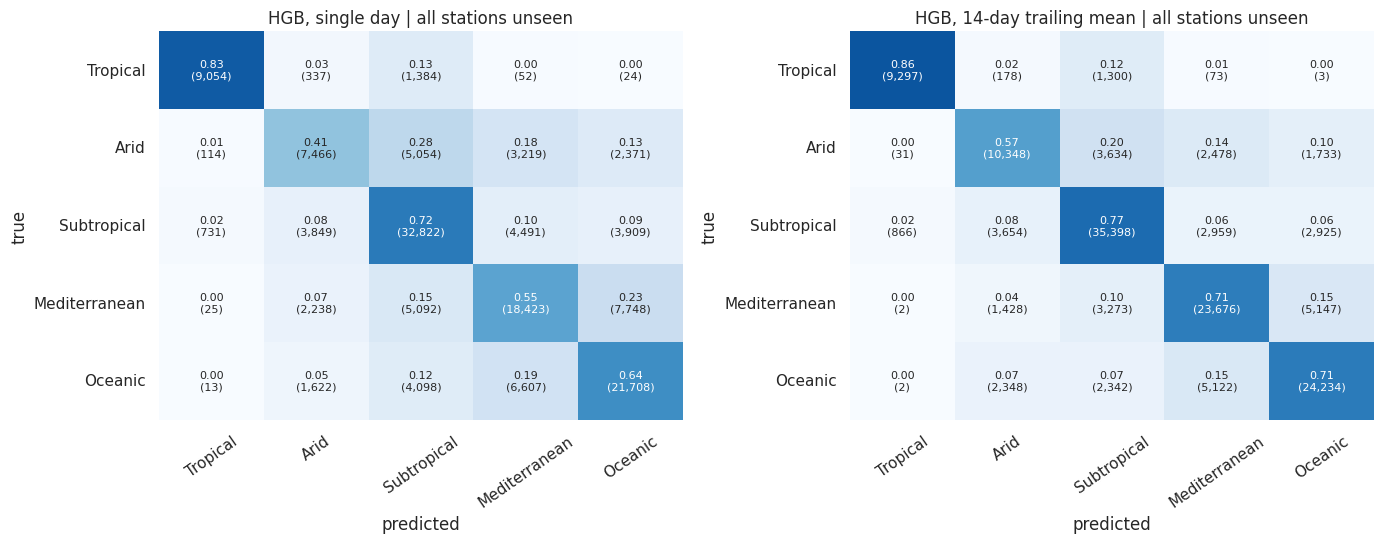

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
plot_cm(axes[0], y, zoo["Gradient Boosting (HGB, default)"]["oof"], "HGB, single day | all stations unseen")
plot_cm(axes[1], y, fe_results["14-day trailing mean"]["oof"], "HGB, 14-day trailing mean | all stations unseen")
plt.tight_layout(); savefig("p6_final_confusion"); plt.show()

**Choice.** For classifying a **single day** we select **gradient boosting (HGB)**: it is best under every
protocol (0.795 random, 0.765 time split, 0.60 ± 0.07 on unseen stations over 15 station groups), beats LR and the
tree in every one of the 15 folds, and trains in seconds. If two weeks of observations from the same station are
available, **HGB on 14-day trailing means** is clearly better on unseen stations (0.68 ± 0.09; better than single
days in 15 of 15 folds) with the same 20 features; the 74-feature multi-scale model is not better. Among the two
"simple" models of Parts 4–5, the tuned tree is better on known stations, while on new stations the two are not
reliably different (tree better in 10 of 15 folds). The confusion matrices show where the remaining errors are: Arid is still confused with
Subtropical, and Mediterranean with Oceanic.

### 6.8 Summary of the open-ended exploration

1. **Model comparison.** Seven model classes; flexible models are better, but their advantage over LR shrinks from
   0.14–0.18 (random split) to 0.06–0.11 macro-F1 (unseen stations), and the random − unseen gap grows with flexibility.
2. **Complexity and regularisation.** Degree-2 polynomial features with a stronger L2 penalty remove much of LR's
   bias, and the gain carries over to unseen stations (+0.10 macro-F1).
3. **Hyperparameter tuning.** Randomised search with station-grouped CV improves HGB by less than 0.01: the
   limitation is station diversity, not hyperparameters.
4. **Feature engineering.** "Climate memory" features are the most effective change in the project: two weeks of
   observations raise unseen-station macro-F1 from 0.64 to 0.73, while a one-year mean destroys the seasonal
   signal that defines the zones. Under a random split the same features leak almost perfectly.
5. **Feature selection.** 90-day means of wind, humidity, rainfall and minimum temperature carry most of the
   information; 20 of 74 features are enough.
6. **Evaluation protocols.** A time-based split costs only 0.02–0.07 compared with a random split, while unseen
   stations cost a further 0.09–0.21: the station, not temporal adjacency, is the main source of optimism. Over 15
   held-out station groups the headline scores are LR 0.51 ± 0.06, tree 0.53 ± 0.06, HGB 0.60 ± 0.07 and HGB with
   14-day means 0.68 ± 0.09, and the HGB improvements hold in every fold.